# Ранжирование фильмов на MovieLens 1M

## 1. Цель проекта

Сравним способы выбрать пять фильмов, которым знакомый системе пользователь поставил бы высокую оценку. Проверим, помогает ли текст описания и может ли второй этап на CatBoost улучшить порядок, предложенный DSSM или ALS. Настройки выбираем по NDCG@5 на пяти фолдах, затем один раз сравниваем зафиксированные варианты на общем тесте.

## 2. Данные и первичный анализ

### 2.1 Загрузка и описание таблиц

В наборе три основные таблицы: ratings (оценки), movies (фильмы), users (пользователи). MovieLens хранит их в файлах с разделителем из двух двоеточий.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

plt.style.use("seaborn-v0_8-whitegrid")
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 65)

data_dir = Path("ml-1m")
if not (data_dir / "ratings.dat").is_file():
    raise FileNotFoundError("Распакуйте MovieLens 1M в ml-1m рядом с ноутбуком и запустите Jupyter из папки проекта.")
print("Данные:", data_dir)

Данные: ml-1m


In [3]:
ratings = pd.read_csv(
    data_dir / "ratings.dat",
    sep="::", engine="python", header=None,
    names=["user_id", "movie_id", "rating", "timestamp"],
    dtype={"user_id": "int32", "movie_id": "int32", "rating": "int8", "timestamp": "int64"},
)
movies = pd.read_csv(
    data_dir / "movies.dat",
    sep="::", engine="python", header=None,
    names=["movie_id", "title", "genres"],
    encoding="latin-1", dtype={"movie_id": "int32"},
)
users = pd.read_csv(
    data_dir / "users.dat",
    sep="::", engine="python", header=None,
    names=["user_id", "gender", "age_group", "occupation", "zip_code"],
    dtype={"user_id": "int32", "zip_code": "string"},
)
ratings["rated_at"] = pd.to_datetime(ratings["timestamp"], unit="s", utc=True)

display(ratings.head(), movies.head(), users.head())

Посмотрим на число строк, признаки и расход памяти

In [4]:
overview = pd.DataFrame(
    [
        {
            "таблица": name,
            "строк": len(frame),
            "столбцов": frame.shape[1],
            "память, МБ": round(frame.memory_usage(deep=True).sum() / 2**20, 2),
            "поля": ", ".join(frame.columns),
        }
        for name, frame in [("ratings", ratings), ("movies", movies), ("users", users)]
    ]
)
display(overview)

n_users = ratings["user_id"].nunique()
n_rated_movies = ratings["movie_id"].nunique()
possible_pairs = n_users * n_rated_movies
density = len(ratings) / possible_pairs
print(f"Пользователей с оценками: {n_users:,}")
print(f"Фильмов в справочнике: {len(movies):,}")
print(f"Фильмов с оценками: {n_rated_movies:,}")
print(f"Известных оценок: {len(ratings):,}")
print(f"Заполненность матрицы пользователь × оценённый фильм: {density:.2%}")
print(f"Остальных пар без оценки: {1 - density:.2%}")
print(
    "Период выставления оценок:",
    ratings["rated_at"].min().date(),
    "—",
    ratings["rated_at"].max().date(),
)

,таблица,строк,столбцов,"память, МБ",поля
0,ratings,1000209,5,23.85,"user_id, movie_id, rating, timestamp, rated_at"
1,movies,3883,3,0.57,"movie_id, title, genres"
2,users,6040,5,0.81,"user_id, gender, age_group, occupation, zip_code"


Пользователей с оценками: 6,040
Фильмов в справочнике: 3,883
Фильмов с оценками: 3,706
Известных оценок: 1,000,209
Заполненность матрицы пользователь × оценённый фильм: 4.47%
Остальных пар без оценки: 95.53%
Период выставления оценок: 2000-04-25 — 2003-02-28


### 2.2 Качество данных

Проверим пропуски, дубликаты и связи между таблицами

In [5]:
missing = pd.DataFrame(
    {
        "таблица": ["ratings", "movies", "users"],
        "пропущенных ячеек": [
            int(ratings.isna().sum().sum()),
            int(movies.isna().sum().sum()),
            int(users.isna().sum().sum()),
        ],
        "полных дубликатов": [
            int(ratings.duplicated().sum()),
            int(movies.duplicated().sum()),
            int(users.duplicated().sum()),
        ],
    }
)
display(missing)
print(
    "Повторных пар пользователь–фильм:",
    ratings.duplicated(["user_id", "movie_id"]).sum(),
)
print(
    "Оценок с отсутствующим пользователем:",
    (~ratings["user_id"].isin(users["user_id"])).sum(),
)
print(
    "Оценок с отсутствующим фильмом:",
    (~ratings["movie_id"].isin(movies["movie_id"])).sum(),
)

,таблица,пропущенных ячеек,полных дубликатов
0,ratings,0,0
1,movies,0,0
2,users,0,0


Повторных пар пользователь–фильм: 0
Оценок с отсутствующим пользователем: 0
Оценок с отсутствующим фильмом: 0


### 2.3 Распределения и наблюдения

Оценка фильма - целевая переменная будущих моделей. Проверим, часто ли встречаются низкие и высокие оценки и насколько полезен прогноз средней оценкой.

,оценка,количество,"доля, %"
0,1,56174,5.62
1,2,107557,10.75
2,3,261197,26.11
3,4,348971,34.89
4,5,226310,22.63


,значение
число оценок,1.000209e+06
среднее,3.581564e+00
ст. отклонение,1.117102e+00
минимум,1.000000e+00
25-й процентиль,3.000000e+00
медиана,4.000000e+00
75-й процентиль,4.000000e+00
максимум,5.000000e+00


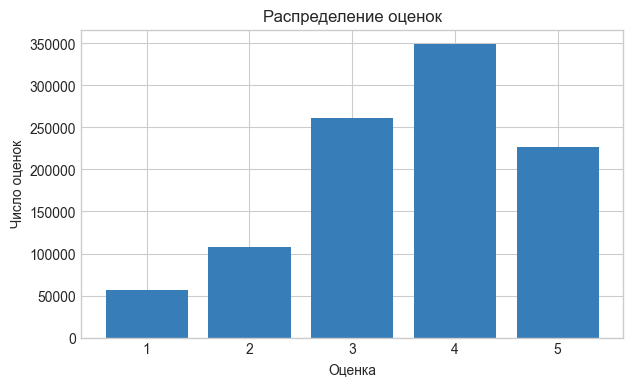

In [6]:
rating_distribution = ratings["rating"].value_counts().sort_index()
rating_table = pd.DataFrame({
    "оценка": rating_distribution.index,
    "количество": rating_distribution.values,
    "доля, %": (100 * rating_distribution.values / len(ratings)).round(2),
})
display(rating_table)
display(
    ratings["rating"]
    .describe()
    .rename(index={"count": "число оценок", "mean": "среднее", "std": "ст. отклонение",
                   "min": "минимум", "25%": "25-й процентиль",
                   "50%": "медиана", "75%": "75-й процентиль", "max": "максимум"})
    .to_frame(name="значение")
)

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(rating_distribution.index.astype(str), rating_distribution.values, color="#377eb8")
ax.set(title="Распределение оценок", xlabel="Оценка", ylabel="Число оценок")
plt.show()

Число оценок на пользователя и на фильм может сильно различаться. По короткой истории сложнее найти похожих пользователей, а по редкому фильму похожие фильмы.

,оценок у пользователя,оценок у фильма
count,6040.0,3706.0
mean,165.6,269.9
std,192.7,384.0
min,20.0,1.0
25%,44.0,33.0
50%,96.0,123.5
75%,208.0,350.0
90%,400.0,729.5
95%,556.0,1051.5
99%,906.7,1784.9


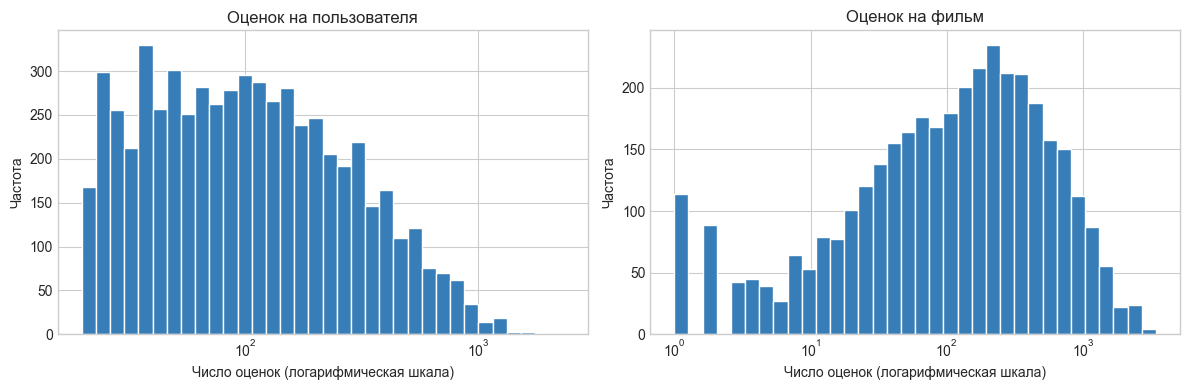

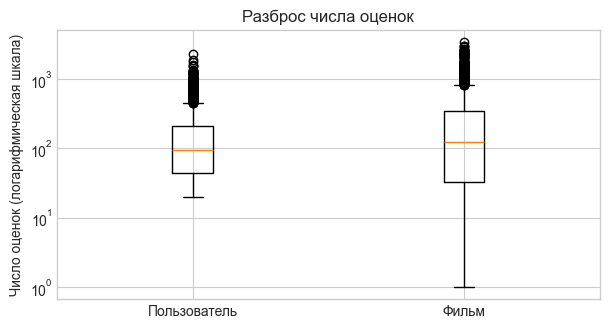

In [7]:
user_activity = ratings.groupby("user_id").size().rename("оценок у пользователя")
movie_popularity = ratings.groupby("movie_id").size().rename("оценок у фильма")
activity_summary = pd.concat(
    [user_activity.describe(percentiles=[.25, .5, .75, .9, .95, .99]),
     movie_popularity.describe(percentiles=[.25, .5, .75, .9, .95, .99])],
    axis=1,
).round(1)
display(activity_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, values, title in [
    (axes[0], user_activity, "Оценок на пользователя"),
    (axes[1], movie_popularity, "Оценок на фильм"),
]:
    bins = np.logspace(np.log10(values.min()), np.log10(values.max()), 35)
    ax.hist(values, bins=bins, color="#377eb8", edgecolor="white")
    ax.set_xscale("log")
    ax.set(title=title, xlabel="Число оценок (логарифмическая шкала)", ylabel="Частота")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.boxplot([user_activity, movie_popularity], labels=["Пользователь", "Фильм"])
ax.set_yscale("log")
ax.set(title="Разброс числа оценок", ylabel="Число оценок (логарифмическая шкала)")
plt.show()

Жанры это основа будущего content-based подхода. Год выпуска извлекаем из названия, также сделаем сразу отдельный признак - кол-во жанров. Один фильм может относиться сразу к нескольким жанрам, поэтому суммы по жанрам будут больше числа фильмов. И при этом воспользуемся multi-hot кодированием для разделение жанров

Жанровых признаков: 18


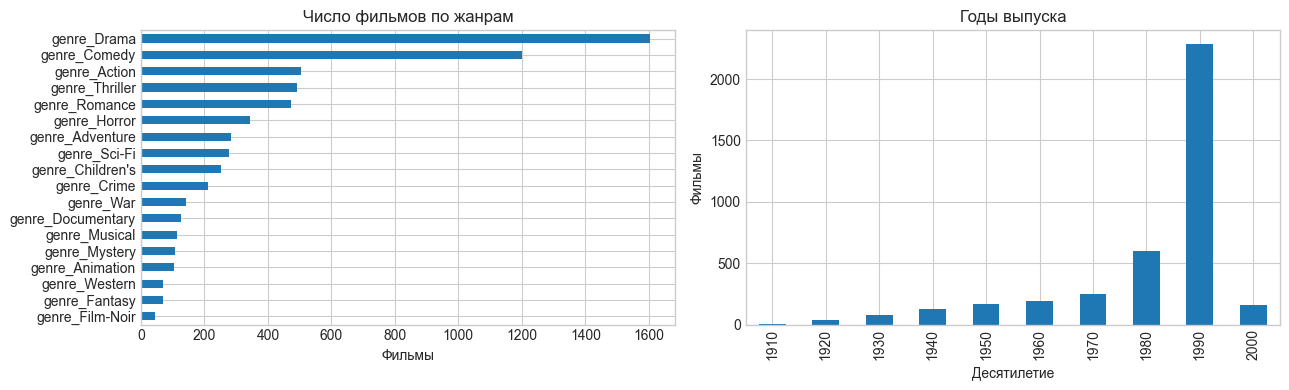

In [8]:
movies["release_year"] = (
    movies["title"].str.extract(r"\((\d{4})\)$")[0].astype("int16")
)

movies["title_clean"] = movies["title"].str.replace(
    r"\s*\(\d{4}\)$", "", regex=True
)

display(movies[["title", "title_clean", "release_year"]].head())
movies["genre_count"] = (
    movies["genres"].str.count(r"\|") + 1
).astype("int8")

genre_ohe = (
    movies["genres"]
    .str.get_dummies(sep="|")
    .add_prefix("genre_")
    .astype("int8")
)
movies[genre_ohe.columns] = genre_ohe


display(
    movies[
        ["title", "genres", "release_year",
         "genre_count", "genre_Comedy", "genre_Drama"]
    ].head()
)
print("Жанровых признаков:", len(genre_ohe.columns))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

genre_ohe.sum().sort_values().plot.barh(ax=axes[0])
axes[0].set(title="Число фильмов по жанрам", xlabel="Фильмы")

decades = movies["release_year"] // 10 * 10
decades.value_counts().sort_index().plot.bar(ax=axes[1])
axes[1].set(title="Годы выпуска", xlabel="Десятилетие", ylabel="Фильмы")

plt.tight_layout()
plt.show()

Демографические данные предоставлены пользователями добровольно и не проверялись авторами набора. Возраст здесь задан группой, а не точным числом лет.

,число пользователей
age_group,
25–34,2096
35–44,1193
18–24,1103
45–49,550
50–55,496
56+,380
<18,222


,число пользователей
gender,
M,4331
F,1709


,число оценок
rated_at,
2000,904757
2001,68058
2002,24046
2003,3348


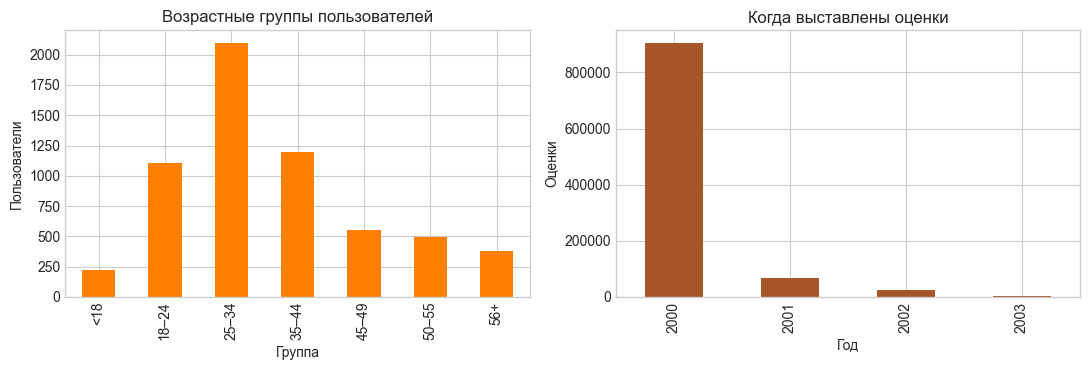

In [9]:
age_labels = {1: "<18", 18: "18–24", 25: "25–34", 35: "35–44",
              45: "45–49", 50: "50–55", 56: "56+"}
age_counts = users["age_group"].map(age_labels).value_counts()
gender_counts = users["gender"].value_counts()
ratings_by_year = ratings["rated_at"].dt.year.value_counts().sort_index()
display(
    pd.DataFrame({"число пользователей": age_counts}),
    pd.DataFrame({"число пользователей": gender_counts}),
    pd.DataFrame({"число оценок": ratings_by_year}),
)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
age_counts.reindex(age_labels.values()).plot.bar(ax=axes[0], color="#ff7f00")
axes[0].set(title="Возрастные группы пользователей", xlabel="Группа", ylabel="Пользователи")
ratings_by_year.plot.bar(ax=axes[1], color="#a65628")
axes[1].set(title="Когда выставлены оценки", xlabel="Год", ylabel="Оценки")
plt.tight_layout()
plt.show()

Корреляции здесь служат только описанию данных. Число оценок фильма и пользователя посчитано по всему набору для EDA; использовать эти значения как признаки при обучении модели нельзя — после разделения их нужно пересчитать только по обучающей части.

,rating,release_year,genre_count,user_activity,movie_popularity
rating,1.000,-0.157,0.002,-0.121,0.255
release_year,-0.157,1.000,0.003,-0.010,0.092
genre_count,0.002,0.003,1.000,-0.073,0.361
user_activity,-0.121,-0.010,-0.073,1.000,-0.205
movie_popularity,0.255,0.092,0.361,-0.205,1.000


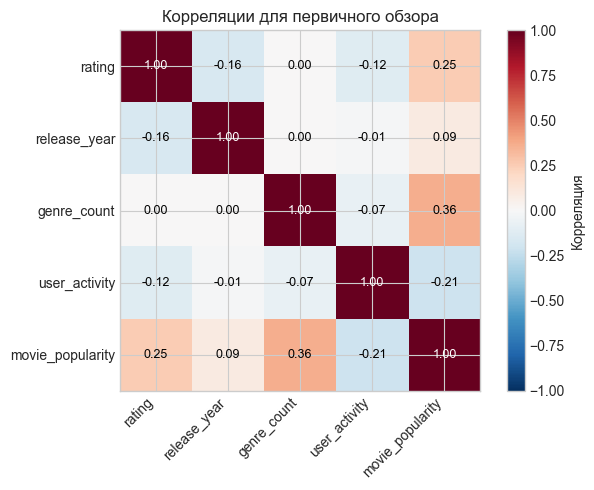

In [10]:
eda_numeric = (
    ratings[["user_id", "movie_id", "rating"]]
    .merge(movies[["movie_id", "release_year", "genre_count"]], on="movie_id", how="left")
    .assign(
        user_activity=lambda frame: frame["user_id"].map(user_activity),
        movie_popularity=lambda frame: frame["movie_id"].map(movie_popularity),
    )
)
correlations = eda_numeric[
    ["rating", "release_year", "genre_count", "user_activity", "movie_popularity"]
].corr()
display(correlations.round(3))

fig, ax = plt.subplots(figsize=(6.5, 5))
image = ax.imshow(correlations, vmin=-1, vmax=1, cmap="RdBu_r")
ax.set_xticks(range(len(correlations.columns)), correlations.columns, rotation=45, ha="right")
ax.set_yticks(range(len(correlations.index)), correlations.index)
for row in range(len(correlations)):
    for col in range(len(correlations)):
        value = correlations.iloc[row, col]
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(value) > 0.5 else "black")
fig.colorbar(image, ax=ax, label="Корреляция")
ax.set_title("Корреляции для первичного обзора")
plt.tight_layout()
plt.show()
del eda_numeric

### 2.4 Feature engineering

Мы уже чутка поработали с movies, добавим несколько признаком для юзеров и фильмов.

In [11]:
movie_stats = ratings.groupby("movie_id")["rating"].agg(["mean", "std"])
user_stats = ratings.groupby("user_id")["rating"].agg(["mean", "std"])

# Признаки фильмов
movies["movie_mean_rating"] = movies["movie_id"].map(movie_stats["mean"])
movies["movie_rating_count"] = (
    movies["movie_id"].map(movie_popularity).fillna(0).astype("int32")
)
movies["movie_rating_std"] = movies["movie_id"].map(movie_stats["std"])

# Признаки пользователей
users["user_mean_rating"] = users["user_id"].map(user_stats["mean"])
users["user_activity"] = users["user_id"].map(user_activity).astype("int32")
users["user_rating_std"] = users["user_id"].map(user_stats["std"])

display(
    movies[
        ["title_clean", "movie_mean_rating",
         "movie_rating_count", "movie_rating_std"]
    ].head()
)
display(
    users[
        ["user_id", "user_mean_rating",
         "user_activity", "user_rating_std"]
    ].head()
)


## 3. Постановка задачи оценки

### 3.1 Что видит модель и что предсказывает

Модель использует обучающую часть данных: знает, какие фильмы каждый пользователь оценил и какие оценки поставил. Затем мы проверяем, насколько хорошо она предсказывает оценки и ранжирует фильмы, оценки за которые были отложены.

Для расчёта `Precision@5` и `NDCG@5` рассматриваются отложенные фильмы каждого пользователя. Хорошими считаются фильмы с оценками 4 и 5. Поэтому эти метрики показывают, насколько высоко модель ставит среди отложенных фильмов те, которые пользователь оценил положительно.

### 3.2 Порог хорошей оценки и кандидаты для ранжирования
Оценки 4 и 5 считаем хорошими, потому что оценка 3 для нас пограничная: она может отражать неоднозначное впечатление от фильма. Оценки 4 и 5 выглядят более уверенным положительным откликом.

В этой проверке мы оцениваем ранжирование среди отложенных фильмов с известными оценками, а не среди всего каталога фильмов.

### 3.3 Метрики качества

#### RMSE

$$
\mathrm{RMSE} = 
\sqrt{
\frac{1}{|T|}
\sum_{(u,i)\in T}
(r_{ui}-\hat r_{ui})^2
}
$$

Здесь $T$ — отложенные оценки, $r_{ui}$ — настоящая оценка, а $\hat r_{ui}$ — прогноз. Чем меньше RMSE, тем лучше.

#### Precision@K

Для каждого пользователя сортируем фильмы по прогнозу. Пусть $y_{u,j}=1$, если фильм на позиции $j$ получил настоящую оценку 4 или 5, и $y_{u,j}=0$ в остальных случаях.

$$
\mathrm{Precision@K}(u) =
\frac{1}{K}\sum_{j=1}^{K}y_{u,j}
$$

Метрика показывает долю подходящих фильмов среди первых $K$ рекомендаций. Итоговое значение усредняем по пользователям. Чем оно выше, тем лучше.

#### NDCG@K

$$
\mathrm{DCG@K}(u) =
\sum_{j=1}^{K}\frac{y_{u,j}}{\log_2(j+1)}
$$

$$
\mathrm{NDCG@K}(u) =
\frac{\mathrm{DCG@K}(u)}{\mathrm{IDCG@K}(u)}
$$

$\mathrm{IDCG@K}$ — значение DCG при идеальном порядке фильмов: все подходящие фильмы стоят первыми. NDCG близка к 1, когда подходящие фильмы находятся в начале списка. Итоговое значение усредняем по пользователям.

#### Как читать метрики

- **RMSE ↓** — чем меньше, тем лучше: прогнозы оценок ближе к реальным.
- **Precision@5 ↑** — чем больше, тем лучше: среди пяти рекомендованных фильмов больше тех, которым пользователь поставил 4 или 5.
- **NDCG@5 ↑** — чем больше, тем лучше: хорошие фильмы не только попадают в топ-5, но и занимают в нём более высокие позиции.

### 3.4 Разделение данных и кросс-валидация

Мы проверяем, сможет ли рекомендательная система предсказать оценки, которые известные пользователи ещё не показали модели.

Для каждого пользователя случайно откладываем 20% его оценок. Оставшиеся 80% используем для обучения, а отложенные оценки для проверки. Так в обучающей части остаются оценки каждого пользователя, и мы проверяем рекомендации для уже известных пользователей.

Матрицу оценок строим только по обучающей части. Строки матрицы соответствуют пользователям, столбцы фильмам, а сохранённые значения — оценкам из `train_ratings`. Пустая ячейка означает, что обучающей оценки для этой пары нет; это не оценка 0.

Параметры моделей подбираем с помощью кросс-валидации внутри `train_ratings`. Отложенную часть `test_ratings` оставляем для финальной проверки после выбора моделей и параметров.

In [12]:
from scipy.sparse import csr_matrix

# Откладываем случайные 20% оценок каждого пользователя
test_idx = ratings.groupby("user_id", group_keys=False).sample(
    frac=0.2,
    random_state=42
).index

train_ratings = ratings.drop(index=test_idx).copy()
test_ratings = ratings.loc[test_idx].copy()

# Общая нумерация пользователей и фильмов
user_ids = ratings["user_id"].unique()
movie_ids = ratings["movie_id"].unique()

user_to_code = {user_id: code for code, user_id in enumerate(user_ids)}
movie_to_code = {movie_id: code for code, movie_id in enumerate(movie_ids)}

# Координаты оценок из обучающей части
user_codes = train_ratings["user_id"].map(user_to_code)
movie_codes = train_ratings["movie_id"].map(movie_to_code)

# Матрица содержит только обучающие оценки
rating_matrix = csr_matrix(
    (
        train_ratings["rating"].to_numpy(),
        (user_codes, movie_codes)
    ),
    shape=(len(user_ids), len(movie_ids))
)

print("Оценок для обучения:", len(train_ratings))
print("Оценок для проверки:", len(test_ratings))
print("Размер матрицы:", rating_matrix.shape)
print("Оценок хранится в матрице:", rating_matrix.nnz)

Оценок для обучения: 800193
Оценок для проверки: 200016
Размер матрицы: (6040, 3706)
Оценок хранится в матрице: 800193


In [13]:
from sklearn.model_selection import KFold

n_folds = 5

cv_ratings = train_ratings.copy()
cv_ratings["fold"] = -1

splitter = KFold(n_splits=n_folds, shuffle=True, random_state=42)

# Распределяем оценки каждого пользователя по фолдам
for _, user_ratings in cv_ratings.groupby("user_id"):
    for fold_id, (_, valid_positions) in enumerate(splitter.split(user_ratings)):
        valid_indices = user_ratings.index[valid_positions]
        cv_ratings.loc[valid_indices, "fold"] = fold_id

print("Оценок в проверочной части каждого фолда:")
display(cv_ratings.groupby("fold").size())

print(
    "Минимум проверочных оценок на пользователя:",
    cv_ratings.groupby(["fold", "user_id"]).size().min()
)

Оценок в проверочной части каждого фолда:


fold
0    162531
1    161282
2    160027
3    158745
4    157608
dtype: int64

Минимум проверочных оценок на пользователя: 3


## 4. User-based

### 4.1 Идея и формула
Для каждого пользователя алгоритм ищет других пользователей с похожими оценками. Затем для пользователя и ещё не оценённого им фильма предсказывает оценку на основе оценок похожих пользователей. Косинусное сходство учитывает пересечение историй и норму полного вектора оценок каждого пользователя.

В этом первом варианте алгоритм не обучает нейронную сеть и не подбирает параметры градиентным спуском. Он рассчитывает сходство пользователей по обучающим оценкам и использует его для прогнозов.

Для пары $(u,i)$ берём до $k$ пользователей с наибольшим положительным сходством с $u$ среди тех, кто оценил $i$. Обозначим этих соседей $N_k(u,i)$. Самого пользователя исключаем.

Прогноз оценки фильма $i$ для пользователя $u$:

$$
\hat{r}_{ui} =
\overline{r}_u
+
\frac{
\sum_{v \in N_k(u,i)} s(u,v)(r_{vi} - \overline{r}_v)
}{
\sum_{v \in N_k(u,i)} |s(u,v)|
}
$$

Здесь учитываются только похожие пользователи, которые оценили фильм $i$. Центрирование учитывает, что одни пользователи в среднем ставят более высокие оценки, чем другие. Если подходящих соседей нет, используем среднюю оценку пользователя.

Сходство пользователей $u$ и $v$ считаем как косинусное сходство их векторов оценок:

$$
s(u,v) =
\frac{
\sum_{i \in I_u \cap I_v} r_{ui}r_{vi}
}{
\sqrt{\sum_{i \in I_u} r_{ui}^{2}}
\sqrt{\sum_{i \in I_v} r_{vi}^{2}}
}
$$

В числителе участвуют фильмы, оценённые обоими пользователями. В знаменателе учитываются все оценки каждого пользователя. Отсутствующая оценка не означает, что пользователь поставил фильму ноль.

In [ ]:
from sklearn.metrics.pairwise import cosine_similarity

user_similarity = cosine_similarity(rating_matrix)

print("Размер матрицы сходства:", user_similarity.shape)

Размер матрицы сходства: (6040, 6040)


In [57]:
def predict_user_based(
    user_code,
    movie_code,
    user_similarity,
    ratings_by_movie,
    user_means,
    k=30
):
    # В CSC-матрице быстро получаем пользователей,
    # которые оценили нужный фильм
    start = ratings_by_movie.indptr[movie_code]
    end = ratings_by_movie.indptr[movie_code + 1]

    neighbor_users = ratings_by_movie.indices[start:end]
    neighbor_ratings = ratings_by_movie.data[start:end]

    # Сходство целевого пользователя с теми,
    # кто оценил этот фильм
    similarities = user_similarity[user_code, neighbor_users]

    # Убираем самого пользователя и нулевое/некорректное сходство
    suitable = (
        (neighbor_users != user_code)
        & np.isfinite(similarities)
        & (similarities > 0)
    )

    neighbor_users = neighbor_users[suitable]
    neighbor_ratings = neighbor_ratings[suitable]
    similarities = similarities[suitable]

    # Если подходящих соседей нет — возвращаем среднюю оценку пользователя
    if len(neighbor_users) == 0:
        return float(user_means[user_code])

    # Оставляем k пользователей с наибольшим сходством
    n_neighbors = min(k, len(neighbor_users))
    best = np.argsort(similarities)[-n_neighbors:]

    best_users = neighbor_users[best]
    best_ratings = neighbor_ratings[best]
    best_similarities = similarities[best]

    # Поправляем среднюю оценку пользователя
    # на отклонения оценок похожих пользователей от их средних
    prediction = user_means[user_code] + (
        np.sum(
            best_similarities
            * (best_ratings - user_means[best_users])
        )
        / np.sum(np.abs(best_similarities))
    )

    return float(np.clip(prediction, 1, 5))

### 4.2 Подбор числа соседей на пяти фолдах

На каждом шаге четыре фолда используем для обучения, а пятый — для проверки. По обучающим оценкам строим матрицу сходства пользователей и прогнозируем оценки в проверочном фолде.

Сравним несколько значений числа соседей $k$ по RMSE, Precision@5 и NDCG@5. Для Precision@5 и NDCG@5 учитываем пользователей, у которых в проверочном фолде есть не меньше пяти фильмов-кандидатов. RMSE считаем по всем проверочным оценкам.

In [ ]:
neighbors_to_try = [10, 30, 50, 100]
discounts = 1 / np.log2(np.arange(2, 7))

user_cv_rows = []

# n_folds = 5 задан в разделе 3.4
for fold_id in range(n_folds):
    print(f"User-based: фолд {fold_id + 1} из {n_folds}")

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    # Матрицу и сходство строим только по обучающей части этого фолда
    train_user_codes = cv_train["user_id"].map(user_to_code)
    train_movie_codes = cv_train["movie_id"].map(movie_to_code)

    matrix_cv = csr_matrix(
        (
            cv_train["rating"].to_numpy(dtype=float),
            (train_user_codes, train_movie_codes)
        ),
        shape=rating_matrix.shape
    )

    user_similarity_cv = cosine_similarity(matrix_cv)
    ratings_by_movie_cv = matrix_cv.tocsc()

    user_means_cv = (
        cv_train.groupby("user_id")["rating"]
        .mean()
        .reindex(user_ids)
        .to_numpy()
    )

    # Для каждого k сохраняем прогнозы на одних и тех же проверочных оценках
    predictions_by_k = {
        k: np.empty(len(cv_valid), dtype=float)
        for k in neighbors_to_try
    }

    for row_number, row in enumerate(cv_valid.itertuples(index=False)):
        user_code = user_to_code[row.user_id]
        movie_code = movie_to_code[row.movie_id]

        for k in neighbors_to_try:
            predictions_by_k[k][row_number] = predict_user_based(
                user_code=user_code,
                movie_code=movie_code,
                user_similarity=user_similarity_cv,
                ratings_by_movie=ratings_by_movie_cv,
                user_means=user_means_cv,
                k=k
            )

    # Считаем метрики каждого значения k на этом фолде
    for k in neighbors_to_try:
        predictions = predictions_by_k[k]
        actual = cv_valid["rating"].to_numpy(dtype=float)

        rmse = np.sqrt(np.mean((actual - predictions) ** 2))

        scored = cv_valid[
            ["user_id", "movie_id", "rating"]
        ].copy()
        scored["prediction"] = predictions

        precisions = []
        ndcgs = []

        for _, group in scored.groupby("user_id"):
            # Для метрик @5 нужны хотя бы 5 фильмов-кандидатов
            if len(group) < 5:
                continue

            top5 = group.sort_values(
                ["prediction", "movie_id"],
                ascending=[False, True]
            ).head(5)

            top5_relevant = (top5["rating"] >= 4).to_numpy()
            all_relevant = (group["rating"] >= 4).to_numpy()

            precisions.append(top5_relevant.mean())

            dcg = np.sum(top5_relevant * discounts)
            ideal_top5 = np.sort(all_relevant)[::-1][:5]
            idcg = np.sum(ideal_top5 * discounts)

            ndcgs.append(dcg / idcg if idcg > 0 else 0)

        user_cv_rows.append({
            "фолд": fold_id,
            "k": k,
            "RMSE": rmse,
            "Precision@5": np.mean(precisions),
            "NDCG@5": np.mean(ndcgs),
            "пользователей для метрик @5": len(precisions)
        })

    # Удаляем большие промежуточные матрицы перед следующим фолдом
    del matrix_cv, user_similarity_cv, ratings_by_movie_cv

user_cv_results = pd.DataFrame(user_cv_rows)

print("Результаты по каждому фолду:")
display(user_cv_results.round(4))

print("Среднее и стандартное отклонение по пяти фолдам:")
display(
    user_cv_results
    .groupby("k")[["RMSE", "Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
    .round(4)
)

User-based: фолд 1 из 5
User-based: фолд 2 из 5
User-based: фолд 3 из 5
User-based: фолд 4 из 5
User-based: фолд 5 из 5
Результаты по каждому фолду:


,фолд,k,RMSE,Precision@5,NDCG@5,пользователей для метрик @5
0,0,10,0.9240,0.7822,0.8341,5549
1,0,30,0.9076,0.7957,0.8476,5549
2,0,50,0.9071,0.7966,0.8495,5549
3,0,100,0.9098,0.7965,0.8500,5549
4,1,10,0.9291,0.7834,0.8335,5487
5,1,30,0.9114,0.7947,0.8488,5487
6,1,50,0.9109,0.7966,0.8510,5487
7,1,100,0.9132,0.7962,0.8513,5487
8,2,10,0.9285,0.7841,0.8337,5361
9,2,30,0.9112,0.7971,0.8477,5361


Среднее и стандартное отклонение по пяти фолдам:


RMSE         Precision@5          NDCG@5        
       mean     std        mean     std    mean     std
k                                                      
10   0.9266  0.0021      0.7845  0.0021  0.8342  0.0010
30   0.9096  0.0017      0.7970  0.0030  0.8480  0.0023
50   0.9089  0.0017      0.7980  0.0022  0.8502  0.0015
100  0.9113  0.0016      0.7978  0.0016  0.8501  0.0014

In [ ]:
user_cv_summary = (
    user_cv_results
    .groupby("k")[["RMSE", "Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
)

best_user_k = user_cv_summary[("NDCG@5", "mean")].idxmax()
best_user_metrics = user_cv_summary.loc[best_user_k]

best_user_result = {
    "k": int(best_user_k),
    "RMSE_mean": best_user_metrics[("RMSE", "mean")],
    "RMSE_std": best_user_metrics[("RMSE", "std")],
    "Precision@5_mean": best_user_metrics[("Precision@5", "mean")],
    "Precision@5_std": best_user_metrics[("Precision@5", "std")],
    "NDCG@5_mean": best_user_metrics[("NDCG@5", "mean")],
    "NDCG@5_std": best_user_metrics[("NDCG@5", "std")],
}

display(pd.DataFrame([best_user_result]).round(4))

,k,RMSE_mean,RMSE_std,Precision@5_mean,Precision@5_std,NDCG@5_mean,NDCG@5_std
0,50,0.9089,0.0017,0.798,0.0022,0.8502,0.0015


### 4.3 Результат и мой вывод
Для задачи рекомендаций в первую очередь важны метрики качества верхней части списка: Precision@5 показывает долю хороших фильмов среди первых пяти, а NDCG@5 дополнительно учитывает их порядок. RMSE оценивает точность предсказания рейтингов и служит дополнительной метрикой.

В данной кроссвалижации получаем, что лучше всего метод при k=50

## 5. Item-based

### 5.1 Идея и формула
Теперь для фильма ищем похожие фильмы и смотрим, какие оценки им уже поставил целевой пользователь

Для пользователя $u$ выбираем до $k$ похожих фильмов, которые он уже оценил. Прогноз строим от средней оценки пользователя, учитывая, насколько оценки похожих фильмов отклоняются от его среднего:

$$
\hat{r}_{ui} =
\overline{r}_u
+
\frac{
\sum_{j \in N_k(i,u)} s(i,j)(r_{uj}-\overline{r}_u)
}{
\sum_{j \in N_k(i,u)} |s(i,j)|
}
$$

Здесь $N_k(i,u)$ — не более $k$ фильмов, которые оценил пользователь $u$ и которые наиболее похожи на целевой фильм $i$. Если подходящих фильмов нет, прогнозируем среднюю оценку пользователя.

In [ ]:
item_similarity = cosine_similarity(rating_matrix.T)

print("Размер матрицы сходства фильмов:", item_similarity.shape)

Размер матрицы сходства фильмов: (3706, 3706)


In [58]:
import numpy as np

def predict_item_based(
    user_code,
    movie_code,
    item_similarity,
    ratings_by_user,
    user_means,
    k=30
):
    # В CSR-матрице получаем фильмы, которые оценил пользователь
    start = ratings_by_user.indptr[user_code]
    end = ratings_by_user.indptr[user_code + 1]

    rated_movies = ratings_by_user.indices[start:end]
    known_ratings = ratings_by_user.data[start:end]

    # Сходство целевого фильма с уже оценёнными фильмами
    similarities = item_similarity[movie_code, rated_movies]

    # Убираем целевой фильм, нулевое и некорректное сходство
    suitable = (
        (rated_movies != movie_code)
        & np.isfinite(similarities)
        & (similarities > 0)
    )

    similarities = similarities[suitable]
    known_ratings = known_ratings[suitable]

    user_mean = float(user_means[user_code])

    # Если похожих оценённых фильмов нет — возвращаем среднее пользователя
    if len(similarities) == 0:
        return user_mean

    # Оставляем k фильмов с наибольшим сходством
    n_neighbors = min(k, len(similarities))
    best = np.argsort(similarities)[-n_neighbors:]

    best_similarities = similarities[best]
    best_ratings = known_ratings[best]

    # Корректируем среднее пользователя на отклонения
    # оценок похожих фильмов от этого среднего
    prediction = user_mean + (
        np.sum(best_similarities * (best_ratings - user_mean))
        / np.sum(np.abs(best_similarities))
    )

    return float(np.clip(prediction, 1, 5))

### 5.2 Кросс-валидация и подбор соседей

In [ ]:
item_neighbors_to_try = [10, 30, 50, 100]
discounts = 1 / np.log2(np.arange(2, 7))

item_cv_rows = []

for fold_id in range(n_folds):
    print(f"Item-based: фолд {fold_id + 1} из {n_folds}")

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    # Матрицу строим только по обучающим оценкам этого фолда
    train_user_codes = cv_train["user_id"].map(user_to_code).to_numpy()
    train_movie_codes = cv_train["movie_id"].map(movie_to_code).to_numpy()

    matrix_cv = csr_matrix(
        (
            cv_train["rating"].to_numpy(dtype=float),
            (train_user_codes, train_movie_codes)
        ),
        shape=rating_matrix.shape
    )

    # Сходство фильмов рассчитываем по оценкам из train-части
    item_similarity_cv = cosine_similarity(matrix_cv.T)
    ratings_by_user_cv = matrix_cv.tocsr()

    # Средние оценки пользователей тоже считаем только на train-части
    user_means_cv = (
        cv_train.groupby("user_id")["rating"]
        .mean()
        .reindex(user_ids)
        .to_numpy(dtype=float)
    )

    # Прогнозируем все проверочные пары для каждого значения k
    predictions_by_k = {
        k: np.empty(len(cv_valid), dtype=float)
        for k in item_neighbors_to_try
    }

    for row_number, row in enumerate(cv_valid.itertuples(index=False)):
        user_code = user_to_code[row.user_id]
        movie_code = movie_to_code[row.movie_id]

        for k in item_neighbors_to_try:
            predictions_by_k[k][row_number] = predict_item_based(
                user_code=user_code,
                movie_code=movie_code,
                item_similarity=item_similarity_cv,
                ratings_by_user=ratings_by_user_cv,
                user_means=user_means_cv,
                k=k
            )

    # Считаем метрики для каждого k
    for k in item_neighbors_to_try:
        predictions = predictions_by_k[k]
        actual = cv_valid["rating"].to_numpy(dtype=float)

        rmse = np.sqrt(np.mean((actual - predictions) ** 2))

        scored = cv_valid[
            ["user_id", "movie_id", "rating"]
        ].copy()
        scored["prediction"] = predictions

        precisions = []
        ndcgs = []

        for _, group in scored.groupby("user_id"):
            # Для метрик @5 нужно не менее пяти фильмов-кандидатов
            if len(group) < 5:
                continue

            top5 = group.sort_values(
                ["prediction", "movie_id"],
                ascending=[False, True]
            ).head(5)

            top5_relevant = (top5["rating"] >= 4).to_numpy()
            all_relevant = (group["rating"] >= 4).to_numpy()

            precisions.append(top5_relevant.mean())

            dcg = np.sum(top5_relevant * discounts)
            ideal_top5 = np.sort(all_relevant)[::-1][:5]
            idcg = np.sum(ideal_top5 * discounts)

            ndcgs.append(dcg / idcg if idcg > 0 else 0)

        item_cv_rows.append({
            "фолд": fold_id,
            "k": k,
            "RMSE": rmse,
            "Precision@5": (
                np.mean(precisions) if precisions else np.nan
            ),
            "NDCG@5": (
                np.mean(ndcgs) if ndcgs else np.nan
            ),
            "пользователей для метрик @5": len(precisions)
        })

    # Освобождаем крупные матрицы перед следующим фолдом
    del matrix_cv, item_similarity_cv, ratings_by_user_cv

item_cv_results = pd.DataFrame(item_cv_rows)

print("Результаты по каждому фолду:")
display(item_cv_results.round(4))

item_cv_summary = (
    item_cv_results
    .groupby("k")[["RMSE", "Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
)

print("Среднее и стандартное отклонение по пяти фолдам:")
display(item_cv_summary.round(4))

Item-based: фолд 1 из 5
Item-based: фолд 2 из 5
Item-based: фолд 3 из 5
Item-based: фолд 4 из 5
Item-based: фолд 5 из 5
Результаты по каждому фолду:


,фолд,k,RMSE,Precision@5,NDCG@5,пользователей для метрик @5
0,0,10,0.9408,0.7760,0.8221,5549
1,0,30,0.9437,0.7826,0.8297,5549
2,0,50,0.9544,0.7828,0.8303,5549
3,0,100,0.9723,0.7797,0.8271,5549
4,1,10,0.9398,0.7727,0.8197,5487
5,1,30,0.9447,0.7787,0.8275,5487
6,1,50,0.9552,0.7791,0.8277,5487
7,1,100,0.9734,0.7811,0.8283,5487
8,2,10,0.9450,0.7748,0.8177,5361
9,2,30,0.9481,0.7819,0.8258,5361


Среднее и стандартное отклонение по пяти фолдам:


RMSE         Precision@5          NDCG@5        
       mean     std        mean     std    mean     std
k                                                      
10   0.9418  0.0030      0.7743  0.0026  0.8190  0.0026
30   0.9455  0.0021      0.7814  0.0028  0.8274  0.0016
50   0.9559  0.0022      0.7829  0.0029  0.8289  0.0017
100  0.9734  0.0019      0.7832  0.0035  0.8282  0.0017

In [ ]:
best_item_k = item_cv_summary[("NDCG@5", "mean")].idxmax()
best_item_metrics = item_cv_summary.loc[best_item_k]

best_item_result = {
    "k": int(best_item_k),
    "RMSE_mean": best_item_metrics[("RMSE", "mean")],
    "RMSE_std": best_item_metrics[("RMSE", "std")],
    "Precision@5_mean": best_item_metrics[("Precision@5", "mean")],
    "Precision@5_std": best_item_metrics[("Precision@5", "std")],
    "NDCG@5_mean": best_item_metrics[("NDCG@5", "mean")],
    "NDCG@5_std": best_item_metrics[("NDCG@5", "std")],
}

display(pd.DataFrame([best_item_result]).round(4))

,k,RMSE_mean,RMSE_std,Precision@5_mean,Precision@5_std,NDCG@5_mean,NDCG@5_std
0,50,0.9559,0.0022,0.7829,0.0029,0.8289,0.0017


### 5.3 Результат и мой вывод

При $k=10$ получен минимальный RMSE (0.9418), то есть этот вариант точнее предсказывает оценки. Наибольший Precision@5 получен при $k=100$ (0.7832), а наибольший NDCG@5 при $k=50$ (0.8289).

Поскольку для рекомендательной системы важны качество и порядок верхних рекомендаций, выбираю $k=50$ по максимальному NDCG@5. Результаты при $k=50$ и $k=100$ близки по метрикам ранжирования, но при $k=50$ ниже RMSE.

### 5.4 Сравнение User-based и Item-based

Сравниваем лучшие настройки обоих методов по средним значениям на пяти фолдах. Для обоих методов это $k=50$.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|---:|
| User-based, $k=50$ | 0.9089 ± 0.0017 | 0.7980 ± 0.0022 | 0.8502 ± 0.0015 |
| Item-based, $k=50$ | 0.9559 ± 0.0022 | 0.7829 ± 0.0029 | 0.8289 ± 0.0017 |

На этих данных User-based показал лучшие результаты по всем трём метрикам. Особенно это заметно по NDCG@5: он лучше расставляет хорошие фильмы выше в списке рекомендаций. Поэтому из двух вариантов коллаборативной фильтрации для дальнейшего сравнения выбираю User-based.

## 6. Матричная факторизация

### 6.1 Общая идея

Предположим, что предпочтения пользователя и свойства фильма можно описать небольшим числом скрытых факторов. Каждому пользователю $u$ сопоставим вектор $p_u$, а каждому фильму $i$ — вектор $q_i$. Эти векторы модель найдёт по известным оценкам; заранее задавать смысл каждого фактора не нужно.

Прогноз оценки получаем так:

$$
\hat r_{ui} = \mu + p_u^\top q_i
$$

Здесь $\mu$ — средняя оценка в **обучающей части текущего фолда**, а $p_u^\top q_i$ — поправка для конкретной пары «пользователь — фильм».

Модель подбирает векторы так, чтобы прогнозы были близки к известным оценкам. В ошибку входят только пары, для которых пользователь действительно поставил оценку. Регуляризация с коэффициентом $\lambda$ ограничивает величину векторов и помогает избежать переобучения.

**SGD и ALS обучают эту же модель, но по-разному:** SGD постепенно меняет векторы после каждой оценки, а ALS поочерёдно пересчитывает векторы пользователей и фильмов.

### 6.2 Обучение методом SGD

SGD (стохастический градиентный спуск) постепенно исправляет векторы пользователей и фильмов, опираясь на известные оценки.

1. Сначала задаём векторам $p_u$ и $q_i$ небольшие случайные значения.
2. Берём известную оценку $r_{ui}$ и считаем ошибку прогноза:

$$
e_{ui} = r_{ui} - (\mu + p_u^\top q_i)
$$

3. Немного меняем оба вектора в направлении уменьшения ошибки:

$$
p_u \leftarrow p_u + \eta(e_{ui}q_i - \lambda p_u)
$$

$$
q_i \leftarrow q_i + \eta(e_{ui}p_u - \lambda q_i)
$$

Здесь $\eta$ — скорость обучения, а $\lambda$ — сила регуляризации. При обновлении обоих векторов используем их значения **до изменения**. После прохода по всем обучающим оценкам начинается следующая эпоха; перед ней оценки снова перемешиваются.

In [59]:
def fit_sgd(
    train_data,
    n_factors=20,
    n_epochs=10,
    learning_rate=0.01,
    reg=0.05,
    seed=42
):
    # Переводим ID в номера строк матриц факторов
    user_codes = train_data["user_id"].map(user_to_code).to_numpy(dtype=int)
    movie_codes = train_data["movie_id"].map(movie_to_code).to_numpy(dtype=int)
    ratings_train = train_data["rating"].to_numpy(dtype=float)

    # Среднее считаем только по данным, переданным для обучения
    mu = ratings_train.mean()

    rng = np.random.default_rng(seed)
    user_factors = rng.normal(0, 0.1, size=(len(user_ids), n_factors))
    movie_factors = rng.normal(0, 0.1, size=(len(movie_ids), n_factors))

    for _ in range(n_epochs):
        # В каждую эпоху обходим оценки в новом случайном порядке
        for position in rng.permutation(len(ratings_train)):
            u = user_codes[position]
            i = movie_codes[position]

            old_user = user_factors[u].copy()
            old_movie = movie_factors[i].copy()

            prediction = mu + old_user @ old_movie
            error = ratings_train[position] - prediction

            user_factors[u] += learning_rate * (
                error * old_movie - reg * old_user
            )
            movie_factors[i] += learning_rate * (
                error * old_user - reg * old_movie
            )

    return mu, user_factors, movie_factors

#### Гиперпараметры SGD

| Гиперпараметр | Текущее значение | Что определяет |
|---|---:|---|
| `n_factors` | 20 | Число скрытых факторов в векторе пользователя и фильма |
| `n_epochs` | 10 | Число проходов по обучающим оценкам |
| `learning_rate` | 0.01 | Размер шага при обновлении векторов |
| `reg` | 0.05 | Силу регуляризации |

**Итого: 4 гиперпараметра.** Эти значения пока служат начальной настройкой; позже подберём их на пяти фолдах. `seed=42` фиксирует случайность для воспроизводимости и в подбор не входит.

#### Единый расчёт метрик

Для SGD и ALS используем одинаковую проверку качества, чтобы результаты можно было сравнивать. По прогнозам на проверочном фолде считаем RMSE, Precision@5 и NDCG@5. Как и в предыдущих разделах, хорошими считаем фильмы с оценкой 4 или 5, а ранжируем только отложенные фильмы с известными оценками.

Функция ниже только рассчитывает метрики: обучение модели и разделение на фолды выполняются отдельно.

In [26]:
def evaluate_predictions(valid_data, predictions):
    result = valid_data[["user_id", "movie_id", "rating"]].copy()
    result["pred"] = predictions

    rmse = np.sqrt(np.mean((result["rating"] - result["pred"]) ** 2))

    discounts = 1 / np.log2(np.arange(2, 7))
    precisions = []
    ndcgs = []

    for _, group in result.groupby("user_id"):
        if len(group) < 5:
            continue

        top5 = group.sort_values(
            ["pred", "movie_id"],
            ascending=[False, True]
        ).head(5)

        relevant_top5 = (top5["rating"] >= 4).to_numpy(dtype=float)
        relevant_all = (group["rating"] >= 4).to_numpy(dtype=float)

        precisions.append(relevant_top5.mean())

        dcg = np.sum(relevant_top5 * discounts)
        ideal_top5 = np.sort(relevant_all)[::-1][:5]
        idcg = np.sum(ideal_top5 * discounts)

        ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

    return {
        "RMSE": rmse,
        "Precision@5": np.mean(precisions),
        "NDCG@5": np.mean(ndcgs)
    }

Перед запуском CV посмтрим одну проверку

In [ ]:
import time

sgd_cv_rows = []

for fold_id in range(n_folds):
    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    start = time.perf_counter()

    mu, user_factors, movie_factors = fit_sgd(
        cv_train,
        n_factors=20,
        n_epochs=10,
        learning_rate=0.01,
        reg=0.05,
        seed=42 + fold_id
    )

    train_seconds = time.perf_counter() - start

    valid_users = cv_valid["user_id"].map(user_to_code).to_numpy(dtype=int)
    valid_movies = cv_valid["movie_id"].map(movie_to_code).to_numpy(dtype=int)

    predictions = mu + np.sum(
        user_factors[valid_users] * movie_factors[valid_movies],
        axis=1
    )

    # Если фильма или пользователя не было в обучении, используем среднее
    known = (
        cv_valid["user_id"].isin(cv_train["user_id"])
        & cv_valid["movie_id"].isin(cv_train["movie_id"])
    ).to_numpy()
    predictions[~known] = mu
    predictions = np.clip(predictions, 1, 5)

    metrics = evaluate_predictions(cv_valid, predictions)
    sgd_cv_rows.append({
        "фолд": fold_id + 1,
        **metrics,
        "время обучения, с": train_seconds
    })

    print(f"Готов фолд {fold_id + 1} из {n_folds}")

sgd_cv_results = pd.DataFrame(sgd_cv_rows)

display(sgd_cv_results.round(4))
display(
    sgd_cv_results[
        ["RMSE", "Precision@5", "NDCG@5", "время обучения, с"]
    ].agg(["mean", "std"]).round(4)
)

Готов фолд 1 из 5
Готов фолд 2 из 5
Готов фолд 3 из 5
Готов фолд 4 из 5
Готов фолд 5 из 5


,фолд,RMSE,Precision@5,NDCG@5,"время обучения, с"
0,1,0.8910,0.7970,0.8496,40.4125
1,2,0.8919,0.7973,0.8506,41.3596
2,3,0.8945,0.7966,0.8459,41.8052
3,4,0.8925,0.8002,0.8488,41.0607
4,5,0.8920,0.7985,0.8472,41.4509


,RMSE,Precision@5,NDCG@5,"время обучения, с"
mean,0.8924,0.7979,0.8484,41.2178
std,0.0013,0.0014,0.0019,0.5226


#### Сравнение начальной настройки SGD с предыдущими методами

Все результаты получены на одних и тех же пяти фолдах.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|---:|
| User-based, 50 соседей | 0.9089 | **0.7980** | **0.8502** |
| Item-based, 50 соседей | 0.9559 | 0.7829 | 0.8289 |
| SGD, начальная настройка | **0.8924** | 0.7979 | 0.8484 |

SGD точнее предсказывает оценки: у него наименьший RMSE. Однако по Precision@5 и NDCG@5 он практически не отличается от User-based. Поэтому пока нельзя сказать, что SGD лучше для нашей задачи рекомендаций. Далее проверим, улучшит ли результат подбор гиперпараметров.

#### Подбор гиперпараметров SGD

Начальная настройка показывает, как SGD работает без подбора параметров. Теперь сравним несколько значений числа факторов, скорости обучения, регуляризации и числа эпох.

Каждую комбинацию проверяем на **тех же пяти фолдах**. Основной критерий выбора — NDCG@5, поскольку нам важно положение хороших фильмов в начале списка. Precision@5 и RMSE также сохраняем, чтобы видеть, чем сопровождается улучшение ранжирования. Отложенный тестовый набор при подборе не используем.

In [ ]:
import time
from itertools import product

factor_values = [10, 20]
epoch_values = [10, 20]
learning_rate_values = [0.005, 0.01]
reg_values = [0.01, 0.05]

settings = list(product(
    factor_values,
    epoch_values,
    learning_rate_values,
    reg_values
))
total_runs = len(settings) * n_folds

# При первом запуске добавляем уже полученные результаты начальной настройки.
# При повторном запуске сохраняем результаты завершённых фолдов.
if "sgd_full_cv_rows" not in globals():
    sgd_full_cv_rows = []

    for _, row in sgd_cv_results.iterrows():
        sgd_full_cv_rows.append({
            "факторов": 20,
            "эпох": 10,
            "learning_rate": 0.01,
            "reg": 0.05,
            "фолд": int(row["фолд"]),
            "RMSE": row["RMSE"],
            "Precision@5": row["Precision@5"],
            "NDCG@5": row["NDCG@5"],
            "время обучения, с": row["время обучения, с"]
        })

completed = {
    (row["факторов"], row["эпох"], row["learning_rate"],
     row["reg"], row["фолд"])
    for row in sgd_full_cv_rows
}

print(f"Уже готово: {len(completed)} из {total_runs} запусков")

for n_factors, n_epochs, learning_rate, reg in settings:
    for fold_id in range(n_folds):
        run_key = (
            n_factors, n_epochs, learning_rate, reg, fold_id + 1
        )

        if run_key in completed:
            continue

        print(
            f"Начинаю {len(completed) + 1}/{total_runs}: "
            f"факторы={n_factors}, эпохи={n_epochs}, "
            f"lr={learning_rate}, reg={reg}, "
            f"фолд={fold_id + 1}",
            flush=True
        )

        cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
        cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

        fold_start = time.perf_counter()

        mu, user_factors, movie_factors = fit_sgd(
            cv_train,
            n_factors=n_factors,
            n_epochs=n_epochs,
            learning_rate=learning_rate,
            reg=reg,
            seed=42 + fold_id
        )

        train_seconds = time.perf_counter() - fold_start

        valid_users = cv_valid["user_id"].map(user_to_code).to_numpy(dtype=int)
        valid_movies = cv_valid["movie_id"].map(movie_to_code).to_numpy(dtype=int)

        predictions = mu + np.sum(
            user_factors[valid_users] * movie_factors[valid_movies],
            axis=1
        )

        known = (
            cv_valid["user_id"].isin(cv_train["user_id"])
            & cv_valid["movie_id"].isin(cv_train["movie_id"])
        ).to_numpy()
        predictions[~known] = mu
        predictions = np.clip(predictions, 1, 5)

        metrics = evaluate_predictions(cv_valid, predictions)

        sgd_full_cv_rows.append({
            "факторов": n_factors,
            "эпох": n_epochs,
            "learning_rate": learning_rate,
            "reg": reg,
            "фолд": fold_id + 1,
            **metrics,
            "время обучения, с": train_seconds
        })
        completed.add(run_key)

        fold_seconds = time.perf_counter() - fold_start
        print(
            f"Готово {len(completed)}/{total_runs}: "
            f"обучение {train_seconds:.1f} с, "
            f"весь фолд {fold_seconds:.1f} с",
            flush=True
        )

Уже готово: 5 из 80 запусков
Начинаю 6/80: факторы=10, эпохи=10, lr=0.005, reg=0.01, фолд=1
Готово 6/80: обучение 39.6 с, весь фолд 41.0 с
Начинаю 7/80: факторы=10, эпохи=10, lr=0.005, reg=0.01, фолд=2
Готово 7/80: обучение 39.5 с, весь фолд 41.0 с
Начинаю 8/80: факторы=10, эпохи=10, lr=0.005, reg=0.01, фолд=3
Готово 8/80: обучение 40.1 с, весь фолд 41.5 с
Начинаю 9/80: факторы=10, эпохи=10, lr=0.005, reg=0.01, фолд=4
Готово 9/80: обучение 39.8 с, весь фолд 41.1 с
Начинаю 10/80: факторы=10, эпохи=10, lr=0.005, reg=0.01, фолд=5
Готово 10/80: обучение 39.8 с, весь фолд 41.1 с
Начинаю 11/80: факторы=10, эпохи=10, lr=0.005, reg=0.05, фолд=1
Готово 11/80: обучение 40.0 с, весь фолд 41.6 с
Начинаю 12/80: факторы=10, эпохи=10, lr=0.005, reg=0.05, фолд=2
Готово 12/80: обучение 39.5 с, весь фолд 40.9 с
Начинаю 13/80: факторы=10, эпохи=10, lr=0.005, reg=0.05, фолд=3
Готово 13/80: обучение 39.7 с, весь фолд 41.1 с
Начинаю 14/80: факторы=10, эпохи=10, lr=0.005, reg=0.05, фолд=4
Готово 14/80: обуче

In [ ]:
sgd_full_cv_results = pd.DataFrame(sgd_full_cv_rows)

group_columns = ["факторов", "эпох", "learning_rate", "reg"]
metric_columns = [
    "RMSE", "Precision@5", "NDCG@5", "время обучения, с"
]

sgd_full_cv_summary = (
    sgd_full_cv_results
    .groupby(group_columns)[metric_columns]
    .agg(["mean", "std"])
    .sort_values(("NDCG@5", "mean"), ascending=False)
)

print(f"Результатов по фолдам: {len(sgd_full_cv_results)} из 80")
display(sgd_full_cv_summary.round(4))

Результатов по фолдам: 80 из 80


RMSE         Precision@5          NDCG@5  \
                                    mean     std        mean     std    mean   
факторов эпох learning_rate reg                                                
20       20   0.010         0.05  0.8698  0.0019      0.8110  0.0022  0.8627   
10       20   0.010         0.05  0.8732  0.0018      0.8086  0.0012  0.8598   
                            0.01  0.8790  0.0022      0.8035  0.0008  0.8541   
20       20   0.005         0.05  0.8914  0.0013      0.7991  0.0017  0.8494   
         10   0.010         0.01  0.8885  0.0016      0.7990  0.0018  0.8486   
                            0.05  0.8924  0.0013      0.7979  0.0014  0.8484   
         20   0.005         0.01  0.8894  0.0016      0.7984  0.0022  0.8481   
              0.010         0.01  0.8939  0.0021      0.7975  0.0016  0.8472   
10       10   0.010         0.01  0.8895  0.0015      0.7974  0.0016  0.8470   
         20   0.005         0.01  0.8894  0.0015      0.7969  0.0016  0.8467   
                            0.05  0.8962  0.0010      0.7950  0.0024  0.8450   
         10   0.010         0.05  0.8973  0.0011      0.7944  0.0025  0.8443   
20       10   0.005         0.01  0.9264  0.0017      0.7811  0.0013  0.8281   
                            0.05  0.9407  0.0023      0.7803  0.0017  0.8272   
10       10   0.005         0.01  0.9322  0.0041      0.7798  0.0030  0.8262   
                            0.05  0.9493  0.0055      0.7795  0.0033  0.8257   

                                         время обучения, с           
                                     std              mean      std  
факторов эпох learning_rate reg                                      
20       20   0.010         0.05  0.0015           87.7674  10.0512  
10       20   0.010         0.05  0.0013           79.5346   0.4352  
                            0.01  0.0024           79.7334   0.4297  
20       20   0.005         0.05  0.0020           83.4153   1.5010  
         10   0.010         0.01  0.0007           42.0726   0.3069  
                            0.05  0.0019           41.2178   0.5226  
         20   0.005         0.01  0.0009           83.9673   0.5674  
              0.010         0.01  0.0017           82.0449   1.3346  
10       10   0.010         0.01  0.0014           40.3148   0.7674  
         20   0.005         0.01  0.0008           79.4272   0.8207  
                            0.05  0.0006           79.5692   0.8672  
         10   0.010         0.05  0.0006           39.6674   0.5740  
20       10   0.005         0.01  0.0013           42.2005   0.2604  
                            0.05  0.0019           42.1846   0.4321  
10       10   0.005         0.01  0.0025           39.7681   0.2244  
                            0.05  0.0029           39.9856   0.4068

#### Результат подбора SGD и сравнение методов

Среди 16 комбинаций гиперпараметров лучшие результаты на пяти фолдах показали **20 факторов, 20 эпох, `learning_rate=0.01` и `reg=0.05`**.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|---:|
| User-based, 50 соседей | 0.9089 | 0.7980 | 0.8502 |
| Item-based, 50 соседей | 0.9559 | 0.7829 | 0.8289 |
| SGD, начальная настройка | 0.8924 | 0.7979 | 0.8484 |
| **SGD, после подбора** | **0.8698** | **0.8110** | **0.8627** |

Подбор улучшил все три метрики SGD. Настроенный SGD также превзошёл User-based и Item-based на одинаковых пяти фолдах. При этом среднее время обучения одного фолда выросло примерно с 41 до 88 секунд.

### 6.3 Обучение методом ALS

ALS (Alternating Least Squares) обучает те же векторы пользователей $p_u$ и фильмов $q_i$, что и SGD. Прогноз остаётся прежним:

$$
\hat r_{ui} = \mu + p_u^\top q_i
$$

Разница в способе обучения. Вместо изменения векторов после каждой оценки ALS чередует два шага:

1. Фиксирует векторы фильмов и пересчитывает вектор каждого пользователя по фильмам, которые тот оценил.
2. Фиксирует обновлённые векторы пользователей и пересчитывает вектор каждого фильма по пользователям, которые его оценили.

Например, для пользователя $u$ алгоритм ищет вектор $p_u$, минимизирующий ошибку на его известных оценках:

$$
p_u = \arg\min_p \left[
\sum_{i \in I_u}(r_{ui}-\mu-p^\top q_i)^2
+ \lambda\|p\|_2^2
\right]
$$

Здесь $I_u$ — фильмы, оценённые пользователем, а $\lambda$ — сила регуляризации. Затем аналогичная задача решается для каждого фильма. Один пересчёт всех пользователей и всех фильмов называется итерацией ALS.

In [46]:
def fit_als(
    train_data,
    n_factors=20,
    n_iterations=10,
    reg=10,
    seed=42
):
    user_codes = train_data["user_id"].map(user_to_code).to_numpy(dtype=int)
    movie_codes = train_data["movie_id"].map(movie_to_code).to_numpy(dtype=int)
    ratings_train = train_data["rating"].to_numpy(dtype=float)

    mu = ratings_train.mean()

    # Матрица содержит только известные обучающие оценки
    matrix = csr_matrix(
        (ratings_train, (user_codes, movie_codes)),
        shape=(len(user_ids), len(movie_ids))
    )
    ratings_by_user = matrix.tocsr()
    ratings_by_movie = matrix.tocsc()

    rng = np.random.default_rng(seed)
    user_factors = rng.normal(0, 0.1, size=(len(user_ids), n_factors))
    movie_factors = rng.normal(0, 0.1, size=(len(movie_ids), n_factors))

    identity = np.eye(n_factors)

    for _ in range(n_iterations):
        # Шаг 1: обновляем векторы пользователей
        for u in range(len(user_ids)):
            start = ratings_by_user.indptr[u]
            end = ratings_by_user.indptr[u + 1]

            rated_movies = ratings_by_user.indices[start:end]
            user_ratings = ratings_by_user.data[start:end]

            if len(rated_movies) == 0:
                user_factors[u] = 0
                continue

            movie_vectors = movie_factors[rated_movies]

            left = movie_vectors.T @ movie_vectors + reg * identity
            right = movie_vectors.T @ (user_ratings - mu)

            user_factors[u] = np.linalg.solve(left, right)

        # Шаг 2: обновляем векторы фильмов
        for i in range(len(movie_ids)):
            start = ratings_by_movie.indptr[i]
            end = ratings_by_movie.indptr[i + 1]

            rated_users = ratings_by_movie.indices[start:end]
            movie_ratings = ratings_by_movie.data[start:end]

            if len(rated_users) == 0:
                movie_factors[i] = 0
                continue

            user_vectors = user_factors[rated_users]

            left = user_vectors.T @ user_vectors + reg * identity
            right = user_vectors.T @ (movie_ratings - mu)

            movie_factors[i] = np.linalg.solve(left, right)

    return mu, user_factors, movie_factors

#### Гиперпараметры ALS

| Гиперпараметр | Начальное значение | Что определяет |
|---|---:|---|
| `n_factors` | 20 | Размер вектора пользователя и фильма |
| `n_iterations` | 10 | Число чередующихся пересчётов пользователей и фильмов |
| `reg` | 10 | Силу регуляризации при пересчёте векторов |

**Итого: 3 гиперпараметра.** Это начальная настройка для проверки на пяти фолдах; затем подберём значения. `seed=42` фиксирует случайную инициализацию и в подбор не входит.

Значения `reg` для ALS и SGD напрямую сравнивать нельзя: алгоритмы применяют регуляризацию по-разному.

In [28]:
import time

als_cv_rows = []

for fold_id in range(n_folds):
    print(f"ALS: начинаю фолд {fold_id + 1}/{n_folds}", flush=True)

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    start = time.perf_counter()

    mu, user_factors, movie_factors = fit_als(
        cv_train,
        n_factors=20,
        n_iterations=10,
        reg=10,
        seed=42 + fold_id
    )

    train_seconds = time.perf_counter() - start

    valid_users = cv_valid["user_id"].map(user_to_code).to_numpy(dtype=int)
    valid_movies = cv_valid["movie_id"].map(movie_to_code).to_numpy(dtype=int)

    predictions = mu + np.sum(
        user_factors[valid_users] * movie_factors[valid_movies],
        axis=1
    )

    # Та же обработка неизвестных пар, что и при проверке SGD
    known = (
        cv_valid["user_id"].isin(cv_train["user_id"])
        & cv_valid["movie_id"].isin(cv_train["movie_id"])
    ).to_numpy()
    predictions[~known] = mu
    predictions = np.clip(predictions, 1, 5)

    metrics = evaluate_predictions(cv_valid, predictions)
    als_cv_rows.append({
        "фолд": fold_id + 1,
        **metrics,
        "время обучения, с": train_seconds
    })

    print(
        f"ALS: готов фолд {fold_id + 1}/{n_folds}, "
        f"обучение {train_seconds:.1f} с",
        flush=True
    )

als_cv_results = pd.DataFrame(als_cv_rows)

display(als_cv_results.round(4))
display(
    als_cv_results[
        ["RMSE", "Precision@5", "NDCG@5", "время обучения, с"]
    ].agg(["mean", "std"]).round(4)
)

ALS: начинаю фолд 1/5
ALS: готов фолд 1/5, обучение 6.9 с
ALS: начинаю фолд 2/5
ALS: готов фолд 2/5, обучение 13.3 с
ALS: начинаю фолд 3/5
ALS: готов фолд 3/5, обучение 6.2 с
ALS: начинаю фолд 4/5
ALS: готов фолд 4/5, обучение 6.0 с
ALS: начинаю фолд 5/5
ALS: готов фолд 5/5, обучение 6.2 с


,фолд,RMSE,Precision@5,NDCG@5,"время обучения, с"
0,1,0.8843,0.8072,0.8582,6.8505
1,2,0.8827,0.8079,0.8611,13.3436
2,3,0.8838,0.8102,0.8598,6.2102
3,4,0.8802,0.8105,0.8601,6.0464
4,5,0.8798,0.8088,0.8600,6.2297


,RMSE,Precision@5,NDCG@5,"время обучения, с"
mean,0.8822,0.8089,0.8599,7.7361
std,0.0021,0.0014,0.0011,3.1497


#### Сравнение ALS с предыдущими методами

Все метрики получены на одинаковых пяти фолдах. Время указано для обучения одного фолда; для User-based и Item-based мы его не измеряли.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ | Время обучения, с ↓ |
|---|---:|---:|---:|---:|
| User-based, 50 соседей | 0.9089 | 0.7980 | 0.8502 | — |
| Item-based, 50 соседей | 0.9559 | 0.7829 | 0.8289 | — |
| SGD, начальная настройка | 0.8924 | 0.7979 | 0.8484 | 41.2 |
| **SGD, после подбора** | **0.8698** | **0.8110** | **0.8627** | 87.8 |
| ALS, начальная настройка | 0.8822 | 0.8089 | 0.8599 | **7.7** |

Настроенный SGD пока лидирует по всем трём метрикам. ALS без подбора параметров уступает ему немного, зато обучается примерно в 11 раз быстрее. Поэтому дальше имеет смысл подобрать гиперпараметры ALS и проверить, сможет ли он улучшить качество рекомендаций.

#### Подбор гиперпараметров ALS

Проверим, как на качество ALS влияют число скрытых факторов, регуляризация и число итераций. Каждую комбинацию оцениваем на тех же пяти фолдах, что и предыдущие методы. Основной критерий выбора — NDCG@5; дополнительно сравниваем Precision@5, RMSE и время обучения. 

In [29]:
import time
from itertools import product

factor_values = [5, 10, 20]
reg_values = [5, 10, 20]
iteration_values = [5, 10]

settings = list(product(factor_values, reg_values, iteration_values))
total_runs = len(settings) * n_folds

# Сохраняем уже готовые результаты при повторном запуске ячейки.
if "als_grid_rows" not in globals():
    als_grid_rows = []

    # Начальную настройку (20 факторов, reg=10, 10 итераций)
    # мы уже проверили на пяти фолдах.
    for _, row in als_cv_results.iterrows():
        als_grid_rows.append({
            "факторов": 20,
            "reg": 10,
            "итераций": 10,
            "фолд": int(row["фолд"]),
            "RMSE": row["RMSE"],
            "Precision@5": row["Precision@5"],
            "NDCG@5": row["NDCG@5"],
            "время обучения, с": row["время обучения, с"]
        })

completed = {
    (row["факторов"], row["reg"], row["итераций"], row["фолд"])
    for row in als_grid_rows
}

print(f"Уже готово: {len(completed)} из {total_runs} запусков")

for n_factors, reg, n_iterations in settings:
    for fold_id in range(n_folds):
        run_key = (n_factors, reg, n_iterations, fold_id + 1)

        if run_key in completed:
            continue

        cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
        cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

        start = time.perf_counter()

        mu, user_factors, movie_factors = fit_als(
            cv_train,
            n_factors=n_factors,
            n_iterations=n_iterations,
            reg=reg,
            seed=42 + fold_id
        )

        train_seconds = time.perf_counter() - start

        valid_users = cv_valid["user_id"].map(user_to_code).to_numpy(dtype=int)
        valid_movies = cv_valid["movie_id"].map(movie_to_code).to_numpy(dtype=int)

        predictions = mu + np.sum(
            user_factors[valid_users] * movie_factors[valid_movies],
            axis=1
        )

        # Если пользователя или фильма не было в обучении этого фолда,
        # используем среднюю оценку обучающей части.
        known = (
            cv_valid["user_id"].isin(cv_train["user_id"])
            & cv_valid["movie_id"].isin(cv_train["movie_id"])
        ).to_numpy()

        predictions[~known] = mu
        predictions = np.clip(predictions, 1, 5)

        metrics = evaluate_predictions(cv_valid, predictions)

        als_grid_rows.append({
            "факторов": n_factors,
            "reg": reg,
            "итераций": n_iterations,
            "фолд": fold_id + 1,
            **metrics,
            "время обучения, с": train_seconds
        })

        completed.add(run_key)

        print(
            f"{len(completed)}/{total_runs}: "
            f"факторы={n_factors}, reg={reg}, "
            f"итерации={n_iterations}, фолд={fold_id + 1} — "
            f"{train_seconds:.1f} с, NDCG@5={metrics['NDCG@5']:.4f}",
            flush=True
        )

Уже готово: 5 из 90 запусков
6/90: факторы=5, reg=5, итерации=5, фолд=1 — 0.8 с, NDCG@5=0.8569
7/90: факторы=5, reg=5, итерации=5, фолд=2 — 0.7 с, NDCG@5=0.8570
8/90: факторы=5, reg=5, итерации=5, фолд=3 — 0.7 с, NDCG@5=0.8556
9/90: факторы=5, reg=5, итерации=5, фолд=4 — 0.7 с, NDCG@5=0.8577
10/90: факторы=5, reg=5, итерации=5, фолд=5 — 0.7 с, NDCG@5=0.8516
11/90: факторы=5, reg=5, итерации=10, фолд=1 — 1.3 с, NDCG@5=0.8596
12/90: факторы=5, reg=5, итерации=10, фолд=2 — 1.3 с, NDCG@5=0.8596
13/90: факторы=5, reg=5, итерации=10, фолд=3 — 1.5 с, NDCG@5=0.8591
14/90: факторы=5, reg=5, итерации=10, фолд=4 — 1.5 с, NDCG@5=0.8602
15/90: факторы=5, reg=5, итерации=10, фолд=5 — 1.5 с, NDCG@5=0.8589
16/90: факторы=5, reg=10, итерации=5, фолд=1 — 0.7 с, NDCG@5=0.8575
17/90: факторы=5, reg=10, итерации=5, фолд=2 — 0.7 с, NDCG@5=0.8583
18/90: факторы=5, reg=10, итерации=5, фолд=3 — 0.7 с, NDCG@5=0.8569
19/90: факторы=5, reg=10, итерации=5, фолд=4 — 0.7 с, NDCG@5=0.8591
20/90: факторы=5, reg=10, ит

In [30]:
als_grid_results = pd.DataFrame(als_grid_rows)

metric_columns = [
    "RMSE", "Precision@5", "NDCG@5", "время обучения, с"
]

als_grid_summary = (
    als_grid_results
    .groupby(["факторов", "reg", "итераций"])[metric_columns]
    .agg(["mean", "std"])
)

print(f"Получено результатов: {len(als_grid_results)} из 90")

print("\nЛучшие настройки по NDCG@5:")
display(
    als_grid_summary
    .sort_values(("NDCG@5", "mean"), ascending=False)
    .head(10)
    .round(4)
)

print("\nЛучшие настройки по RMSE:")
display(
    als_grid_summary
    .sort_values(("RMSE", "mean"))
    .head(5)
    .round(4)
)

Получено результатов: 90 из 90

Лучшие настройки по NDCG@5:


RMSE         Precision@5          NDCG@5          \
                         mean     std        mean     std    mean     std   
факторов reg итераций                                                       
20       20  10        0.8840  0.0016      0.8145  0.0022  0.8666  0.0018   
10       10  10        0.8695  0.0019      0.8137  0.0027  0.8657  0.0014   
         20  10        0.8845  0.0016      0.8133  0.0023  0.8657  0.0010   
20       20  5         0.8867  0.0018      0.8125  0.0023  0.8646  0.0015   
10       20  5         0.8882  0.0019      0.8115  0.0024  0.8635  0.0013   
         10  5         0.8765  0.0024      0.8098  0.0022  0.8611  0.0019   
         5   10        0.8712  0.0020      0.8102  0.0028  0.8606  0.0014   
5        10  10        0.8765  0.0015      0.8086  0.0020  0.8599  0.0006   
20       10  10        0.8822  0.0021      0.8089  0.0014  0.8599  0.0011   
5        5   10        0.8712  0.0018      0.8083  0.0019  0.8595  0.0005   

                      время обучения, с          
                                   mean     std  
факторов reg итераций                            
20       20  10                  5.4090  0.5647  
10       10  10                  3.4826  0.4882  
         20  10                  3.5408  0.7527  
20       20  5                   2.8335  0.6232  
10       20  5                   2.0437  0.9760  
         10  5                  12.9258  6.8063  
         5   10                  7.2769  3.9049  
5        10  10                  1.2990  0.0247  
20       10  10                  7.7361  3.1497  
5        5   10                  1.4125  0.1188


Лучшие настройки по RMSE:


RMSE         Precision@5          NDCG@5          \
                         mean     std        mean     std    mean     std   
факторов reg итераций                                                       
10       10  10        0.8695  0.0019      0.8137  0.0027  0.8657  0.0014   
5        5   10        0.8712  0.0018      0.8083  0.0019  0.8595  0.0005   
10       5   10        0.8712  0.0020      0.8102  0.0028  0.8606  0.0014   
         10  5         0.8765  0.0024      0.8098  0.0022  0.8611  0.0019   
5        10  10        0.8765  0.0015      0.8086  0.0020  0.8599  0.0006   

                      время обучения, с          
                                   mean     std  
факторов reg итераций                            
10       10  10                  3.4826  0.4882  
5        5   10                  1.4125  0.1188  
10       5   10                  7.2769  3.9049  
         10  5                  12.9258  6.8063  
5        10  10                  1.2990  0.0247

#### Сравнение ALS с предыдущими методами

Все метрики получены на одинаковых пяти фолдах.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|---:|
| User-based, 50 соседей | 0.9089 | 0.7980 | 0.8502 |
| Item-based, 50 соседей | 0.9559 | 0.7829 | 0.8289 |
| SGD, начальная настройка | 0.8924 | 0.7979 | 0.8484 |
| SGD, после подбора | **0.8698** | 0.8110 | 0.8627 |
| ALS, начальная настройка | 0.8822 | 0.8089 | 0.8599 |
| ALS, после подбора: 20 факторов, `reg=20`, 10 итераций | 0.8840 | **0.8145** | **0.8666** |

Настроенный ALS лучше всех ранжирует фильмы по Precision@5 и NDCG@5. Настроенный SGD точнее предсказывает числовые оценки по RMSE. Поскольку цель проекта рекомендации, для дальнейшего сравнения выбираем ALS по NDCG@5.

## 7. Content-based рекомендации


Здесь сходство фильмов определяем по их содержанию: жанрам и описаниям. Для персонализации используем оценки самого пользователя из обучающей части. Оценки других пользователей при расчёте сходства фильмов не используются.

### 7.1 Формула ранжирования

Для нового фильма $i$ ищем в истории пользователя $u$ понравившийся ему фильм, наиболее близкий по содержанию, и вычисляем балл

$$
\operatorname{score}(u,i) =
\max_{\substack{j \in I_u \\ r_{uj} > 3}}
\rho(e_i,e_j)\,r_{uj}.
$$

Здесь $I_u$ — фильмы, оценённые пользователем в обучающей части, $e_i$ и $e_j$ — представления фильмов, а $\rho$ — их косинусное сходство. Условие $r_{uj}>3$ оставляет оценки 4 и 5, которые мы ранее определили как положительные.

Для каждого пользователя сортируем проверочные фильмы по полученному баллу и рассчитываем Precision@5 и NDCG@5. Это балл **для ранжирования**, а не откалиброванный прогноз оценки от 1 до 5. Поэтому его RMSE нельзя напрямую трактовать как RMSE моделей, предсказывающих оценку.

In [30]:
from sklearn.metrics.pairwise import cosine_similarity

# Берём только столбцы отдельных жанров.
# genre_count — это количество жанров, его сюда не включаем.
genre_columns = [
    column for column in movies.columns
    if column.startswith("genre_") and column != "genre_count"
]

movie_genres = movies[genre_columns].to_numpy(dtype=float)

# Номер строки матрицы для каждого movie_id
content_movie_ids = movies["movie_id"].to_numpy()
content_movie_to_code = {
    movie_id: code
    for code, movie_id in enumerate(content_movie_ids)
}

# В ячейке [i, j] — сходство жанров фильмов i и j
content_similarity = cosine_similarity(movie_genres).astype("float32")
np.fill_diagonal(content_similarity, 0)

print("Форма матрицы сходства:", content_similarity.shape)
print("Жанровых признаков:", len(genre_columns))

Форма матрицы сходства: (3883, 3883)
Жанровых признаков: 18


In [46]:
import time
from scipy.sparse import csr_matrix

genre_rank_rows = []
discounts = 1 / np.log2(np.arange(2, 7))

for fold_id in range(n_folds):
    print(f"Жанры: начинаю фолд {fold_id + 1}/{n_folds}", flush=True)

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    # 1. Баллы фильмов
    score_start = time.perf_counter()

    liked = cv_train[cv_train["rating"] >= 4]

    liked_matrix = csr_matrix(
        (
            liked["rating"].to_numpy(dtype=float),
            (
                liked["user_id"].map(user_to_code).to_numpy(),
                liked["movie_id"].map(content_movie_to_code).to_numpy()
            )
        ),
        shape=(len(user_ids), len(content_movie_ids))
    )

    valid_movie_codes = (
        cv_valid["movie_id"]
        .map(content_movie_to_code)
        .to_numpy()
    )

    fold_scores = np.zeros(len(cv_valid), dtype=float)

    for user_id, positions in cv_valid.groupby("user_id").indices.items():
        user_code = user_to_code[user_id]

        start = liked_matrix.indptr[user_code]
        end = liked_matrix.indptr[user_code + 1]

        if start == end:
            continue

        liked_movies = liked_matrix.indices[start:end]
        liked_ratings = liked_matrix.data[start:end]
        target_movies = valid_movie_codes[positions]

        similarities = content_similarity[
            np.ix_(target_movies, liked_movies)
        ]

        fold_scores[positions] = (
            similarities * liked_ratings[None, :]
        ).max(axis=1)

    score_seconds = time.perf_counter() - score_start

    # 2. Precision@5 и NDCG@5
    metric_start = time.perf_counter()

    scored = cv_valid[["user_id", "movie_id", "rating"]].copy()
    scored["score"] = fold_scores
    scored["relevant"] = (scored["rating"] >= 4).astype(int)

    scored = scored.sort_values(
        ["user_id", "score", "movie_id"],
        ascending=[True, False, True]
    )

    scored["position"] = scored.groupby("user_id").cumcount() + 1
    scored["n_candidates"] = (
        scored.groupby("user_id")["movie_id"].transform("size")
    )

    top5 = scored[
        (scored["n_candidates"] >= 5)
        & (scored["position"] <= 5)
    ].copy()

    precision5 = top5["relevant"].mean()

    top5["gain"] = (
        top5["relevant"]
        / np.log2(top5["position"] + 1)
    )
    dcg = top5.groupby("user_id")["gain"].sum()

    relevant_counts = (
        scored.groupby("user_id")["relevant"]
        .sum()
        .reindex(dcg.index)
        .clip(upper=5)
        .to_numpy(dtype=int)
    )

    ideal_dcg = np.r_[0, np.cumsum(discounts)][relevant_counts]

    ndcg_per_user = np.divide(
        dcg.to_numpy(),
        ideal_dcg,
        out=np.zeros(len(dcg)),
        where=ideal_dcg > 0
    )
    ndcg5 = ndcg_per_user.mean()

    metric_seconds = time.perf_counter() - metric_start

    genre_rank_rows.append({
        "фолд": fold_id + 1,
        "Precision@5": precision5,
        "NDCG@5": ndcg5,
        "расчёт баллов, с": score_seconds,
        "расчёт метрик, с": metric_seconds
    })

    print(
        f"Готов фолд {fold_id + 1}/{n_folds}: "
        f"баллы {score_seconds:.1f} с, "
        f"метрики {metric_seconds:.1f} с",
        flush=True
    )

genre_rank_results = pd.DataFrame(genre_rank_rows)

display(genre_rank_results.round(4))
display(
    genre_rank_results[["Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
    .round(4)
)

Жанры: начинаю фолд 1/5
Готов фолд 1/5: баллы 0.3 с, метрики 0.0 с
Жанры: начинаю фолд 2/5
Готов фолд 2/5: баллы 0.3 с, метрики 0.0 с
Жанры: начинаю фолд 3/5
Готов фолд 3/5: баллы 0.3 с, метрики 0.0 с
Жанры: начинаю фолд 4/5
Готов фолд 4/5: баллы 0.3 с, метрики 0.0 с
Жанры: начинаю фолд 5/5
Готов фолд 5/5: баллы 0.3 с, метрики 0.0 с


,фолд,Precision@5,NDCG@5,"расчёт баллов, с","расчёт метрик, с"
0,1,0.6537,0.6862,0.3237,0.0306
1,2,0.6511,0.6843,0.3437,0.0231
2,3,0.6539,0.6841,0.3229,0.0226
3,4,0.6528,0.6841,0.3160,0.0205
4,5,0.6471,0.6788,0.3172,0.0206


,Precision@5,NDCG@5
mean,0.6517,0.6835
std,0.0028,0.0028


#### Результаты рекомендаций по жанрам

Метод проверен на пяти фолдах. Для каждого фильма мы находили наиболее похожий фильм среди тех, которым пользователь поставил 4 или 5, и использовали его сходство и оценку для ранжирования.

| Метрика | Среднее | Стандартное отклонение |
|---|---:|---:|
| Precision@5 ↑ | 0.6517 | 0.0028 |
| NDCG@5 ↑ | 0.6835 | 0.0028 |

В среднем доля подходящих фильмов в первых пяти рекомендациях составила около 65%. Близкие результаты на разных фолдах показывают, что оценка качества стабильна при выбранном разбиении. Метод опирается только на жанры, поэтому фильмы с одинаковыми жанрами ему трудно различать.

Полученный балл нужен для **ранжирования фильмов**, а не для предсказания оценки от 1 до 5. Поэтому RMSE здесь не рассчитываем.

### 7.2 Расширение каталога: английские описания фильмов

В исходном MovieLens 1M для фильма есть название и жанры, но нет описания сюжета. Чтобы проверить рекомендации по содержанию фильма, мы создали расширенный каталог `movies_with_overviews.csv`. Его основой стала таблица фильмов `ml-1m/movies.dat`; описания взяли из локальных файлов `links.csv` и `movies_metadata.csv` набора [The Movies Dataset](https://www.kaggle.com/datasets/rounakbanik/the-movies-dataset), содержащего метаданные TMDB. Это была обработка готового набора данных, а не запросы к сайту TMDB для каждого фильма.

**Как мы сопоставили фильмы:**

1. Связали `movie_id` из MovieLens с `movieId` в `links.csv` и получили идентификатор `tmdbId`.
2. По `tmdbId` нашли запись в `movies_metadata.csv`. Дополнительно сравнили IMDb ID в обеих таблицах, чтобы не перенести описание другого фильма.
3. Если IMDb ID в таблице соответствий отсутствовал, принимали совпадение только при уникальном точном совпадении нормализованного названия и года выпуска.
4. Проверили язык непустого описания. В `overview_en` записали только принятый английский текст; сомнительные или неанглийские описания не добавляли.

Так удалось подтвердить соответствие для 3823 фильмов. Английское описание получили **3804 из 3883 фильмов (97,97%)**. Все фильмы остались в каталоге, включая 79 без принятого описания:

| Причина отсутствия описания | Фильмов |
|---|---:|
| Не найдено подтверждённое соответствие | 50 |
| Соответствие найдено, но описание пустое | 18 |
| IMDb ID в источниках противоречат друг другу | 10 |
| Описание не прошло проверку английского языка | 1 |

Код подготовки сохраняет ID, название, год выпуска и жанры, затем добавляет `overview_en`, идентификатор и название найденного фильма TMDB, способ сопоставления, статус проверки и ссылку на источник. Фильмы без описания перечислены отдельно в `movies_overview_issues.csv`; код построения каталога находится в `enrich_movies_overviews.py`.

Далее представим английские описания числовыми векторами с помощью TF-IDF. Фильмы без описания не удаляем: при расчёте их сходства будем опираться на жанры.

In [33]:
movies_content = pd.read_csv(
    data_dir.parent / "movies_with_overviews.csv"
)

has_overview = (
    movies_content["overview_en"]
    .fillna("")
    .str.strip()
    .ne("")
)

assert np.array_equal(
    movies_content["movie_id"].to_numpy(),
    movies["movie_id"].to_numpy()
)

print("Всего фильмов:", len(movies_content))
print("С английским описанием:", has_overview.sum())
print("Без описания:", (~has_overview).sum())

display(
    movies_content.loc[has_overview, ["title", "overview_en"]].head(3)
)

Всего фильмов: 3883
С английским описанием: 3804
Без описания: 79


### 7.3 TF-IDF и жанры

Теперь представим английское описание каждого фильма числовым вектором. В TF-IDF строка соответствует фильму, а столбец — слову или паре соседних слов. Больший вес получают слова, которые встречаются в данном описании, но не слишком часто встречаются в остальных описаниях.

Используем английские стоп-слова, отдельные слова и пары слов. Термины, встретившиеся только в одном фильме, исключим (`min_df=2`). Полученная матрица будет разреженной: у каждого фильма ненулевые значения есть лишь для терминов из его описания.

Для 79 фильмов без описания текстовый вектор будет нулевым. Позже при объединении сходства предусмотрим для них опору на жанры.

In [60]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    stop_words="english",
    min_df=2,
    ngram_range=(1, 2)
)

movie_tfidf = tfidf.fit_transform(
    movies_content["overview_en"].fillna("")
)

print("Форма TF-IDF-матрицы:", movie_tfidf.shape)
print("Фильмов с ненулевым вектором:", (movie_tfidf.getnnz(axis=1) > 0).sum())

Форма TF-IDF-матрицы: (3883, 14501)
Фильмов с ненулевым вектором: 3804


#### Объединение сходства по описаниям и жанрам

Сначала отдельно посчитаем косинусное сходство описаний и жанров. Если описания есть у обоих фильмов, объединим результаты:

$$
s(i,j) = \alpha\,s_{\text{text}}(i,j) + (1-\alpha)\,s_{\text{genres}}(i,j)
$$

Для первого эксперимента возьмём $\alpha=0.7$: описание получит вес 70%, жанры — 30%. Если хотя бы у одного фильма нет описания, используем только сходство жанров. Значение $\alpha$ пока не подбираем.

In [63]:
text_similarity_matrix = cosine_similarity(movie_tfidf).astype("float32")

# Эта матрица уже построена в разделе 7.1
genre_similarity_matrix = content_similarity

alpha = 0.7

content_similarity_matrix = (
    alpha * text_similarity_matrix
    + (1 - alpha) * genre_similarity_matrix
)

# Если у одного из фильмов нет описания, берём только жанры
missing_text = ~has_overview.to_numpy()

content_similarity_matrix[missing_text, :] = (
    genre_similarity_matrix[missing_text, :]
)
content_similarity_matrix[:, missing_text] = (
    genre_similarity_matrix[:, missing_text]
)

np.fill_diagonal(content_similarity_matrix, 0)

print("Форма матрицы:", content_similarity_matrix.shape)
print("Фильмов без описания:", missing_text.sum())

Форма матрицы: (3883, 3883)
Фильмов без описания: 79


In [53]:

tfidf_rank_rows = []
discounts = 1 / np.log2(np.arange(2, 7))

for fold_id in range(n_folds):
    start_time = time.perf_counter()
    print(f"TF-IDF + жанры: фолд {fold_id + 1}/{n_folds}", flush=True)

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    # Фильмы, которым пользователь поставил 4 или 5 на обучении
    liked = cv_train[cv_train["rating"] >= 4]

    liked_matrix = csr_matrix(
        (
            liked["rating"].to_numpy(dtype=float),
            (
                liked["user_id"].map(user_to_code).to_numpy(),
                liked["movie_id"].map(content_movie_to_code).to_numpy()
            )
        ),
        shape=(len(user_ids), len(content_movie_ids))
    )

    valid_movie_codes = (
        cv_valid["movie_id"]
        .map(content_movie_to_code)
        .to_numpy()
    )

    scores = np.zeros(len(cv_valid), dtype=float)

    # Считаем баллы проверочных фильмов каждого пользователя
    for user_id, positions in cv_valid.groupby("user_id").indices.items():
        user_code = user_to_code[user_id]

        start = liked_matrix.indptr[user_code]
        end = liked_matrix.indptr[user_code + 1]

        if start == end:
            continue

        liked_movies = liked_matrix.indices[start:end]
        liked_ratings = liked_matrix.data[start:end]
        target_movies = valid_movie_codes[positions]

        similarities = content_similarity_matrix[
            np.ix_(target_movies, liked_movies)
        ]

        scores[positions] = (
            similarities * liked_ratings[None, :]
        ).max(axis=1)

    # Сортируем проверочные фильмы и берём первые пять
    scored = cv_valid[["user_id", "movie_id", "rating"]].copy()
    scored["score"] = scores
    scored["relevant"] = (scored["rating"] >= 4).astype(int)

    scored = scored.sort_values(
        ["user_id", "score", "movie_id"],
        ascending=[True, False, True]
    )

    scored["position"] = scored.groupby("user_id").cumcount() + 1
    scored["n_candidates"] = (
        scored.groupby("user_id")["movie_id"].transform("size")
    )

    top5 = scored[
        (scored["n_candidates"] >= 5)
        & (scored["position"] <= 5)
    ].copy()

    precision5 = top5["relevant"].mean()

    # NDCG@5
    top5["gain"] = (
        top5["relevant"]
        / np.log2(top5["position"] + 1)
    )
    dcg = top5.groupby("user_id")["gain"].sum()

    relevant_counts = (
        scored.groupby("user_id")["relevant"]
        .sum()
        .reindex(dcg.index)
        .clip(upper=5)
        .to_numpy(dtype=int)
    )

    ideal_dcg = np.r_[0, np.cumsum(discounts)][relevant_counts]

    ndcg_per_user = np.divide(
        dcg.to_numpy(),
        ideal_dcg,
        out=np.zeros(len(dcg)),
        where=ideal_dcg > 0
    )
    ndcg5 = ndcg_per_user.mean()

    tfidf_rank_rows.append({
        "фолд": fold_id + 1,
        "Precision@5": precision5,
        "NDCG@5": ndcg5,
        "время, с": time.perf_counter() - start_time
    })

    print(f"Готов фолд {fold_id + 1}/{n_folds}", flush=True)

tfidf_rank_results = pd.DataFrame(tfidf_rank_rows)

display(tfidf_rank_results.round(4))
display(
    tfidf_rank_results[["Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
    .round(4)
)

TF-IDF + жанры: фолд 1/5
Готов фолд 1/5
TF-IDF + жанры: фолд 2/5
Готов фолд 2/5
TF-IDF + жанры: фолд 3/5
Готов фолд 3/5
TF-IDF + жанры: фолд 4/5
Готов фолд 4/5
TF-IDF + жанры: фолд 5/5
Готов фолд 5/5


,фолд,Precision@5,NDCG@5,"время, с"
0,1,0.6705,0.7118,0.3770
1,2,0.6707,0.7122,0.4172
2,3,0.6712,0.7105,0.4067
3,4,0.6759,0.7142,0.3925
4,5,0.6694,0.7077,0.3830


,Precision@5,NDCG@5
mean,0.6715,0.7113
std,0.0025,0.0024


#### Результаты: TF-IDF и жанры

| Представление фильмов | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|
| Только жанры | 0.6517 | 0.6835 |
| TF-IDF + жанры | **0.6715** | **0.7113** |

Результаты TF-IDF + жанры получены на пяти фолдах; стандартные отклонения составили 0.0025 для Precision@5 и 0.0024 для NDCG@5. Добавление описаний улучшило оба показателя: подходящие фильмы чаще попадают в первую пятёрку и в среднем занимают в ней более высокие позиции. При этом результат относится к выбранному весу текста 0.7 — другие веса мы пока не проверяли.

### 7.4 MPNet и жанры

Теперь представим каждое английское описание плотным вектором с помощью предварительно обученной модели `all-mpnet-base-v2`. В отличие от TF-IDF, такой вектор учитывает описание целиком, а не только совпадение отдельных слов.

Модель здесь не обучается на оценках пользователей: мы один раз получаем эмбеддинги фильмов. Для 79 фильмов без описания оставляем нулевой текстовый вектор; при расчёте сходства будем использовать для них жанры.

In [34]:
from sentence_transformers import SentenceTransformer

mpnet_model = SentenceTransformer(
    "sentence-transformers/all-mpnet-base-v2",
    revision="e8c3b32edf5434bc2275fc9bab85f82640a19130",
)

# Кодируем только фильмы, у которых есть описание
overview_vectors = mpnet_model.encode(
    movies_content.loc[has_overview, "overview_en"].tolist(),
    batch_size=16,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

# Расставляем векторы по строкам исходного каталога.
# У фильмов без описания пока останутся нули.
movie_mpnet_embeddings = np.zeros(
    (len(movies_content), overview_vectors.shape[1]),
    dtype="float32"
)
movie_mpnet_embeddings[has_overview.to_numpy()] = overview_vectors

print("Форма матрицы эмбеддингов:", movie_mpnet_embeddings.shape)
print("Фильмов с описанием:", has_overview.sum())

Batches: 100%|██████████| 238/238 [00:32<00:00,  7.41it/s]


Форма матрицы эмбеддингов: (3883, 768)
Фильмов с описанием: 3804


In [61]:
mpnet_text_similarity_matrix = cosine_similarity(
    movie_mpnet_embeddings
).astype("float32")

mpnet_alpha = 0.7
genre_similarity_matrix = content_similarity

mpnet_content_similarity_matrix = (
    mpnet_alpha * mpnet_text_similarity_matrix
    + (1 - mpnet_alpha) * genre_similarity_matrix
)

# Если хотя бы у одного фильма нет описания,
# используем полное сходство по жанрам
missing_text = ~has_overview.to_numpy()

mpnet_content_similarity_matrix[missing_text, :] = (
    genre_similarity_matrix[missing_text, :]
)
mpnet_content_similarity_matrix[:, missing_text] = (
    genre_similarity_matrix[:, missing_text]
)

np.fill_diagonal(mpnet_content_similarity_matrix, 0)

print("Форма матрицы сходства:", mpnet_content_similarity_matrix.shape)

Форма матрицы сходства: (3883, 3883)


In [57]:
import time
from scipy.sparse import csr_matrix

mpnet_rank_rows = []
discounts = 1 / np.log2(np.arange(2, 7))

for fold_id in range(n_folds):
    start_time = time.perf_counter()
    print(f"MPNet + жанры: фолд {fold_id + 1}/{n_folds}", flush=True)

    cv_train = cv_ratings[cv_ratings["fold"] != fold_id]
    cv_valid = cv_ratings[cv_ratings["fold"] == fold_id]

    # Только понравившиеся фильмы из обучающей части
    liked = cv_train[cv_train["rating"] >= 4]

    liked_matrix = csr_matrix(
        (
            liked["rating"].to_numpy(dtype=float),
            (
                liked["user_id"].map(user_to_code).to_numpy(),
                liked["movie_id"].map(content_movie_to_code).to_numpy()
            )
        ),
        shape=(len(user_ids), len(content_movie_ids))
    )

    valid_movie_codes = (
        cv_valid["movie_id"]
        .map(content_movie_to_code)
        .to_numpy()
    )

    scores = np.zeros(len(cv_valid), dtype=float)

    # Балл фильма: максимальное «сходство × оценка»
    for user_id, positions in cv_valid.groupby("user_id").indices.items():
        user_code = user_to_code[user_id]

        start = liked_matrix.indptr[user_code]
        end = liked_matrix.indptr[user_code + 1]

        if start == end:
            continue

        liked_movies = liked_matrix.indices[start:end]
        liked_ratings = liked_matrix.data[start:end]
        target_movies = valid_movie_codes[positions]

        similarities = mpnet_content_similarity_matrix[
            np.ix_(target_movies, liked_movies)
        ]

        scores[positions] = (
            similarities * liked_ratings[None, :]
        ).max(axis=1)

    # Ранжирование проверочных фильмов
    scored = cv_valid[["user_id", "movie_id", "rating"]].copy()
    scored["score"] = scores
    scored["relevant"] = (scored["rating"] >= 4).astype(int)

    scored = scored.sort_values(
        ["user_id", "score", "movie_id"],
        ascending=[True, False, True]
    )

    scored["position"] = scored.groupby("user_id").cumcount() + 1
    scored["n_candidates"] = (
        scored.groupby("user_id")["movie_id"].transform("size")
    )

    top5 = scored[
        (scored["n_candidates"] >= 5)
        & (scored["position"] <= 5)
    ].copy()

    precision5 = top5["relevant"].mean()

    # NDCG@5
    top5["gain"] = (
        top5["relevant"]
        / np.log2(top5["position"] + 1)
    )
    dcg = top5.groupby("user_id")["gain"].sum()

    relevant_counts = (
        scored.groupby("user_id")["relevant"]
        .sum()
        .reindex(dcg.index)
        .clip(upper=5)
        .to_numpy(dtype=int)
    )

    ideal_dcg = np.r_[0, np.cumsum(discounts)][relevant_counts]

    ndcg_per_user = np.divide(
        dcg.to_numpy(),
        ideal_dcg,
        out=np.zeros(len(dcg)),
        where=ideal_dcg > 0
    )
    ndcg5 = ndcg_per_user.mean()

    mpnet_rank_rows.append({
        "фолд": fold_id + 1,
        "Precision@5": precision5,
        "NDCG@5": ndcg5,
        "время, с": time.perf_counter() - start_time
    })

    print(f"Готов фолд {fold_id + 1}/{n_folds}", flush=True)

mpnet_rank_results = pd.DataFrame(mpnet_rank_rows)

display(mpnet_rank_results.round(4))
display(
    mpnet_rank_results[["Precision@5", "NDCG@5"]]
    .agg(["mean", "std"])
    .round(4)
)

MPNet + жанры: фолд 1/5
Готов фолд 1/5
MPNet + жанры: фолд 2/5
Готов фолд 2/5
MPNet + жанры: фолд 3/5
Готов фолд 3/5
MPNet + жанры: фолд 4/5
Готов фолд 4/5
MPNet + жанры: фолд 5/5
Готов фолд 5/5


,фолд,Precision@5,NDCG@5,"время, с"
0,1,0.6764,0.7158,0.4259
1,2,0.6769,0.7185,0.4679
2,3,0.6793,0.7167,0.4105
3,4,0.6810,0.7206,0.3969
4,5,0.6753,0.7149,0.3953


,Precision@5,NDCG@5
mean,0.6778,0.7173
std,0.0023,0.0023


#### Результаты: MPNet и жанры

Все три варианта проверены на одинаковых пяти фолдах. В вариантах с описаниями вес текста равен 0.7, вес жанров — 0.3.

| Представление фильмов | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|
| Жанры | 0.6517 | 0.6835 |
| TF-IDF + жанры | 0.6715 | 0.7113 |
| **MPNet + жанры** | **0.6778** | **0.7173** |

MPNet показал лучший результат среди проверенных контентных представлений. По сравнению с TF-IDF улучшение небольшое: +0.0063 по Precision@5 и +0.0060 по NDCG@5. Стандартные отклонения MPNet по пяти фолдам составили 0.0023 для обеих метрик.

Вывод относится к ранжированию фильмов из проверочной части, которым пользователи уже поставили оценки. Качество рекомендаций среди всего каталога и для новых фильмов мы этим экспериментом отдельно не проверяли.

### 7.5 Сравнение с другими методами

Все результаты получены на одинаковых пяти фолдах. Precision@5 и NDCG@5 сравнивают порядок фильмов, уже оценённых пользователями в проверочной части.

| Метод | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|---:|
| User-based, 50 соседей | 0.9089 | 0.7980 | 0.8502 |
| Item-based, 50 соседей | 0.9559 | 0.7829 | 0.8289 |
| SGD, после подбора | **0.8698** | 0.8110 | 0.8627 |
| ALS, после подбора | 0.8840 | **0.8145** | **0.8666** |
| Content-based: жанры | — | 0.6517 | 0.6835 |
| Content-based: TF-IDF + жанры | — | 0.6715 | 0.7113 |
| Content-based: MPNet + жанры | — | 0.6778 | 0.7173 |

Для контентных методов RMSE не указан: их балл используется для ранжирования и не является прогнозом оценки от 1 до 5.

Добавление описаний улучшило контентные рекомендации; лучший результат дал MPNet + жанры. Однако даже он уступает ALS по NDCG@5 на 0.1493. Возможное объяснение — сходство жанров и описаний отражает содержание фильма, но не использует закономерности в оценках разных пользователей. Кроме того, наша контентная формула опирается только на оценки 4–5 и не учитывает фильмы, которые пользователю не понравились.

## 8. MLP-based рекомендации

Проверим, сможет ли нейросетевая модель улучшить рекомендации по сравнению с классическими методами. MLP получает ID пользователя и фильма, преобразует их в обучаемые векторы и прогнозирует оценку. По этим прогнозам мы ранжируем отложенные фильмы.

Сначала зададим архитектуру и способ оценки, затем проверим настройки модели на тех же пяти фолдах. В конце сравним выбранную MLP с ALS по RMSE, Precision@5 и NDCG@5.

### 8.1 Гипотеза и входные данные

В матричной факторизации прогноз зависит от скалярного произведения векторов пользователя и фильма. Теперь проверим, поможет ли обучаемая нелинейная функция их взаимодействия улучшить качество рекомендаций.

Для каждой пары «пользователь - фильм» модель получает два входа: `user_id` и `movie_id`. Настоящая оценка `rating` служит целевой переменной при обучении.

Каждому пользователю и фильму сопоставим обучаемый эмбеддинг. Сначала его значения случайны. Во время обучения оценки пользователей будут изменять эти векторы вместе с весами нейросети. Так модель сможет находить скрытые закономерности в предпочтениях.

Объединим векторы пользователя и фильма и передадим их в MLP. На выходе получим прогноз оценки. Для формирования рекомендаций будем сортировать фильмы по этому прогнозу.

Основной критерий выбора модели - NDCG@5. Дополнительно будем учитывать Precision@5 и RMSE. Положительным откликом по-прежнему считаем настоящую оценку 4 или 5.

Настройки будем выбирать на тех же пяти фолдах, что и у предыдущих методов.

#### 8.2 Архитектура модели

ID пользователя и фильма сами по себе не являются числовыми признаками: пользователь с ID 100 не «больше» пользователя с ID 10. Поэтому сначала модель сопоставляет каждому ID обучаемый вектор — эмбеддинг.

| Шаг | Размер выхода | Что происходит |
|---|---:|---|
| ID пользователя → эмбеддинг | 32 | Вектор предпочтений пользователя |
| ID фильма → эмбеддинг | 32 | Вектор фильма |
| Объединение векторов | 64 | Модель получает информацию об обоих объектах |
| Линейный слой → ReLU → Dropout | 64 | Ищет сочетания признаков пользователя и фильма |
| Линейный слой → ReLU → Dropout | 32 | Преобразует найденные сочетания |
| Линейный слой | 1 | Выдаёт поправку к средней оценке |

Итоговый прогноз:

$$
\hat r_{ui} =
\mu_{\mathrm{train}} +
\operatorname{MLP}\bigl([e_u;e_i]\bigr),
$$

где $e_u$ и $e_i$ — обучаемые эмбеддинги пользователя и фильма, $[e_u;e_i]$ — их объединение, а $\mu_{\mathrm{train}}$ — средняя оценка **только в обучающей части текущего фолда**.

Для первого эксперимента возьмём эмбеддинги размерности 32 и два скрытых слоя размерности 64 и 32. Это небольшая стартовая сеть: она позволяет проверить нелинейное взаимодействие без слишком большого числа параметров. Позже оценим выбранные размеры на кросс-валидации.

Функция ReLU добавляет нелинейность. Dropout с вероятностью 0.2 во время обучения случайно отключает часть выходов скрытых слоёв.

### 8.3 Обучение и оценка MLP

MLP предсказывает оценку по ID пользователя и фильма. На каждом батче $B$ оптимизатор Adam минимизирует

$$
L_B = \sqrt{\frac{1}{|B|}\sum_{(u,i)\in B}(r_{ui}-\hat r_{ui})^2+10^{-8}}.
$$

В начале каждого фолда заново инициализируем эмбеддинги и веса сети. Среднюю оценку для модели считаем по обучающим строкам этого фолда. После эпохи с зафиксированными весами отдельно вычисляем RMSE по всем строкам обучения и валидации, а также Precision@5 и NDCG@5 на валидации.

Главный критерий выбора настроек и эпохи - **средний NDCG@5 по тем же пяти фолдам**, что использовались для предыдущих методов. Precision@5 показывает долю понравившихся фильмов в первой пятёрке, а RMSE дополнительно показывает точность предсказания оценок. При расчёте Precision@5 и NDCG@5 ранжируем отложенные фильмы, которые пользователь действительно оценил; оценку 4 или 5 считаем положительной. Итоговую тестовую часть пока не используем.

In [14]:
import torch
import torch.nn as nn


def training_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")


class MovieMLP(nn.Module):
    def __init__(
        self,
        num_users,
        num_movies,
        mean_rating,
        embedding_dim=32,
        hidden_dims=(64, 32),
        dropout=0.2,
        use_batch_norm=False
    ):
        super().__init__()

        self.user_embedding = nn.Embedding(num_users, embedding_dim)
        self.movie_embedding = nn.Embedding(num_movies, embedding_dim)

        layers = []
        input_size = embedding_dim * 2

        for hidden_size in hidden_dims:
            layers.append(nn.Linear(input_size, hidden_size))

            if use_batch_norm:
                layers.append(nn.BatchNorm1d(hidden_size))

            layers.append(nn.ReLU())

            if dropout > 0:
                layers.append(nn.Dropout(dropout))

            input_size = hidden_size

        layers.append(nn.Linear(input_size, 1))
        self.layers = nn.Sequential(*layers)
        self.mean_rating = mean_rating

    def forward(self, user_idx, movie_idx):
        user_vector = self.user_embedding(user_idx)
        movie_vector = self.movie_embedding(movie_idx)

        pair_vector = torch.cat([user_vector, movie_vector], dim=1)
        rating_change = self.layers(pair_vector).squeeze(1)

        return self.mean_rating + rating_change

In [15]:
mlp_folds = []

for fold in range(5):
    train = cv_ratings[cv_ratings["fold"] != fold]
    valid = cv_ratings[cv_ratings["fold"] == fold]

    mlp_folds.append({
        "train_users": torch.tensor(
            train["user_id"].map(user_to_code).to_numpy(),
            dtype=torch.long
        ),
        "train_movies": torch.tensor(
            train["movie_id"].map(movie_to_code).to_numpy(),
            dtype=torch.long
        ),
        "train_ratings": torch.tensor(
            train["rating"].to_numpy(),
            dtype=torch.float32
        ),
        "valid_users": torch.tensor(
            valid["user_id"].map(user_to_code).to_numpy(),
            dtype=torch.long
        ),
        "valid_movies": torch.tensor(
            valid["movie_id"].map(movie_to_code).to_numpy(),
            dtype=torch.long
        ),
        "valid_ratings": torch.tensor(
            valid["rating"].to_numpy(),
            dtype=torch.float32
        ),
        "mean_rating": float(train["rating"].mean())
    })

print("Фолдов подготовлено:", len(mlp_folds))
print("Оценок в обучении первого фолда:", len(mlp_folds[0]["train_ratings"]))
print("Оценок для проверки первого фолда:", len(mlp_folds[0]["valid_ratings"]))
print("Средняя оценка в обучении первого фолда:", round(mlp_folds[0]["mean_rating"], 3))

Фолдов подготовлено: 5
Оценок в обучении первого фолда: 637662
Оценок для проверки первого фолда: 162531
Средняя оценка в обучении первого фолда: 3.581


### 8.4 Первый запуск и графики обучения

Проверим исходную MLP: эмбеддинги размером 32, скрытые слои 64 и 32, learning_rate=0.001, dropout=0.2, без weight_decay. Обучим её 10 эпох на пяти фолдах. Этот запуск станет точкой сравнения для следующих изменений. Посмотрим, как меняются ошибка и качество ранжирования по эпохам.

In [16]:
def run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42,
    mlp_folds=None
):
    import time
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import torch
    import torch.nn as nn
    from torch.utils.data import TensorDataset, DataLoader

    # Если фолды не передали в функцию, берём подготовленные выше
    if mlp_folds is None:
        mlp_folds = globals()["mlp_folds"]

    device = training_device()

    print("Устройство:", device)
    print("Эмбеддинг:", embedding_dim)
    print("Скрытые слои:", hidden_dims)
    print("Dropout:", dropout)
    print("BatchNorm:", use_batch_norm)
    print("Learning rate:", learning_rate)
    print("Weight decay:", weight_decay)
    print("Размер батча:", batch_size)

    discounts = 1 / np.log2(np.arange(2, 7))
    all_rows = []
    models_by_fold = {}

    for fold_id, fold_data in enumerate(mlp_folds):
        fold_start = time.perf_counter()
        print(f"\nФолд {fold_id + 1} из {len(mlp_folds)}")

        cv_valid = cv_ratings[
            cv_ratings["fold"] == fold_id
        ].copy()

        # Инициализация модели для этого фолда
        torch.manual_seed(seed + fold_id)

        model = MovieMLP(
            num_users=len(user_to_code),
            num_movies=len(movie_to_code),
            mean_rating=fold_data["mean_rating"],
            embedding_dim=embedding_dim,
            hidden_dims=hidden_dims,
            dropout=dropout,
            use_batch_norm=use_batch_norm
        ).to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate,
            weight_decay=weight_decay
        )

        mse_function = nn.MSELoss()

        train_dataset = TensorDataset(
            fold_data["train_users"],
            fold_data["train_movies"],
            fold_data["train_ratings"]
        )

        valid_dataset = TensorDataset(
            fold_data["valid_users"],
            fold_data["valid_movies"],
            fold_data["valid_ratings"]
        )

        train_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=True
        )

        # Для метрик используем отдельные загрузчики:
        # порядок фиксирован, все строки включены
        train_eval_loader = DataLoader(
            train_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        valid_loader = DataLoader(
            valid_dataset,
            batch_size=batch_size,
            shuffle=False
        )

        for epoch in range(1, n_epochs + 1):
            # Обучение на батчах
            model.train()

            for users_batch, movies_batch, ratings_batch in train_loader:
                users_batch = users_batch.to(device)
                movies_batch = movies_batch.to(device)
                ratings_batch = ratings_batch.to(device)

                predictions = model(users_batch, movies_batch)

                batch_mse = mse_function(predictions, ratings_batch)
                batch_rmse = torch.sqrt(batch_mse + 1e-8)

                optimizer.zero_grad()
                batch_rmse.backward()
                optimizer.step()

            # После эпохи считаем RMSE для обеих частей одинаковым способом
            model.eval()

            train_squared_error = 0.0
            train_count = 0
            valid_squared_error = 0.0
            valid_count = 0
            valid_predictions = []

            with torch.no_grad():
                for users_batch, movies_batch, ratings_batch in train_eval_loader:
                    users_batch = users_batch.to(device)
                    movies_batch = movies_batch.to(device)
                    ratings_batch = ratings_batch.to(device)

                    predictions = model(users_batch, movies_batch)

                    train_squared_error += (
                        (predictions - ratings_batch) ** 2
                    ).sum().item()
                    train_count += len(ratings_batch)

                for users_batch, movies_batch, ratings_batch in valid_loader:
                    users_batch = users_batch.to(device)
                    movies_batch = movies_batch.to(device)
                    ratings_batch = ratings_batch.to(device)

                    predictions = model(users_batch, movies_batch)

                    valid_squared_error += (
                        (predictions - ratings_batch) ** 2
                    ).sum().item()
                    valid_count += len(ratings_batch)

                    valid_predictions.extend(
                        predictions.cpu().numpy()
                    )

            train_rmse = (train_squared_error / train_count) ** 0.5
            valid_rmse = (valid_squared_error / valid_count) ** 0.5

            # Проверяем, что прогнозы совпали с проверочными строками
            assert len(valid_predictions) == len(cv_valid)

            scored = cv_valid[
                ["user_id", "movie_id", "rating"]
            ].copy()

            scored["prediction"] = valid_predictions

            precisions = []
            ndcgs = []

            for _, group in scored.groupby("user_id"):
                if len(group) < 5:
                    continue

                top5 = group.sort_values(
                    ["prediction", "movie_id"],
                    ascending=[False, True]
                ).head(5)

                top5_relevant = (top5["rating"] >= 4).to_numpy()
                all_relevant = (group["rating"] >= 4).to_numpy()

                precisions.append(top5_relevant.mean())

                dcg = np.sum(top5_relevant * discounts)
                ideal_top5 = np.sort(all_relevant)[::-1][:5]
                idcg = np.sum(ideal_top5 * discounts)

                ndcgs.append(dcg / idcg if idcg > 0 else 0)

            precision5 = np.mean(precisions)
            ndcg5 = np.mean(ndcgs)

            all_rows.append({
                "фолд": fold_id + 1,
                "эпоха": epoch,
                "Train RMSE": train_rmse,
                "Validation RMSE": valid_rmse,
                "Precision@5": precision5,
                "NDCG@5": ndcg5
            })

            print(
                f"  Эпоха {epoch}/{n_epochs}: "
                f"Train RMSE = {train_rmse:.4f}, "
                f"Validation RMSE = {valid_rmse:.4f}, "
                f"Precision@5 = {precision5:.4f}, "
                f"NDCG@5 = {ndcg5:.4f}"
            )

        models_by_fold[fold_id + 1] = model

        print(
            f"Фолд завершён за "
            f"{time.perf_counter() - fold_start:.1f} секунд"
        )

    results = pd.DataFrame(all_rows)

    summary = (
        results
        .groupby("эпоха")[
            [
                "Train RMSE",
                "Validation RMSE",
                "Precision@5",
                "NDCG@5"
            ]
        ]
        .agg(["mean", "std"])
    )

    display(results.round(4))
    display(summary.round(4))

    mean_ndcg = results.groupby("эпоха")["NDCG@5"].mean()
    best_epoch = mean_ndcg.idxmax()

    print(
        f"Лучшая эпоха по среднему NDCG@5: {best_epoch} "
        f"(NDCG@5 = {mean_ndcg.loc[best_epoch]:.4f})"
    )

    # Графики средних значений по фолдам
    epochs = summary.index
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    axes[0].plot(
        epochs,
        summary[("Train RMSE", "mean")],
        marker="o",
        label="Train RMSE"
    )
    axes[0].plot(
        epochs,
        summary[("Validation RMSE", "mean")],
        marker="o",
        label="Validation RMSE"
    )
    axes[0].set(
        title="RMSE после каждой эпохи",
        xlabel="Эпоха",
        ylabel="RMSE"
    )
    axes[0].set_xticks(epochs)
    axes[0].legend()
    axes[0].grid(True)

    axes[1].plot(
        epochs,
        summary[("Precision@5", "mean")],
        marker="o",
        label="Precision@5"
    )
    axes[1].plot(
        epochs,
        summary[("NDCG@5", "mean")],
        marker="o",
        label="NDCG@5"
    )
    axes[1].set(
        title="Качество рекомендаций по фолдам",
        xlabel="Эпоха",
        ylabel="Значение метрики"
    )
    axes[1].set_xticks(epochs)
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()

    return {
        "models_by_fold": models_by_fold,
        "results": results,
        "summary": summary,
        "best_epoch": best_epoch,
        "device": device
    }

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0742, Validation RMSE = 1.0784, Precision@5 = 0.7232, NDCG@5 = 0.7674
  Эпоха 2/10: Train RMSE = 1.0060, Validation RMSE = 1.0122, Precision@5 = 0.7592, NDCG@5 = 0.8086
  Эпоха 3/10: Train RMSE = 0.9645, Validation RMSE = 0.9723, Precision@5 = 0.7733, NDCG@5 = 0.8235
  Эпоха 4/10: Train RMSE = 0.9399, Validation RMSE = 0.9491, Precision@5 = 0.7783, NDCG@5 = 0.8287
  Эпоха 5/10: Train RMSE = 0.9248, Validation RMSE = 0.9353, Precision@5 = 0.7800, NDCG@5 = 0.8306
  Эпоха 6/10: Train RMSE = 0.9136, Validation RMSE = 0.9255, Precision@5 = 0.7802, NDCG@5 = 0.8319
  Эпоха 7/10: Train RMSE = 0.9070, Validation RMSE = 0.9199, Precision@5 = 0.7816, NDCG@5 = 0.8332
  Эпоха 8/10: Train RMSE = 0.9028, Validation RMSE = 0.9163, Precision@5 = 0.7799, NDCG@5 = 0.8320
  Эпоха 9/10: Train RMSE = 0.8995, Validation RMSE = 0

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0742,1.0784,0.7232,0.7674
1,1,2,1.0060,1.0122,0.7592,0.8086
2,1,3,0.9645,0.9723,0.7733,0.8235
3,1,4,0.9399,0.9491,0.7783,0.8287
4,1,5,0.9248,0.9353,0.7800,0.8306
5,1,6,0.9136,0.9255,0.7802,0.8319
6,1,7,0.9070,0.9199,0.7816,0.8332
7,1,8,0.9028,0.9163,0.7799,0.8320
8,1,9,0.8995,0.9137,0.7821,0.8338
9,1,10,0.8963,0.9117,0.7827,0.8343


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0720  0.0026          1.0739  0.0041      0.7236  0.0035  0.7688   
2         1.0053  0.0022          1.0103  0.0031      0.7636  0.0037  0.8118   
3         0.9646  0.0012          0.9721  0.0018      0.7750  0.0019  0.8239   
4         0.9408  0.0009          0.9500  0.0016      0.7799  0.0022  0.8288   
5         0.9251  0.0008          0.9360  0.0016      0.7815  0.0016  0.8307   
6         0.9154  0.0011          0.9276  0.0017      0.7817  0.0011  0.8316   
7         0.9083  0.0009          0.9217  0.0017      0.7832  0.0018  0.8328   
8         0.9036  0.0008          0.9179  0.0017      0.7828  0.0024  0.8327   
9         0.8996  0.0007          0.9150  0.0013      0.7833  0.0018  0.8330   
10        0.8967  0.0007          0.9130  0.0016      0.7840  0.0013  0.8336   

               
          std  
эпоха          
1      0.0034  
2      0.0024  
3      0.0017  
4      0.0013  
5      0.0010  
6      0.0011  
7      0.0015  
8      0.0017  
9      0.0014  
10     0.0016

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8336)


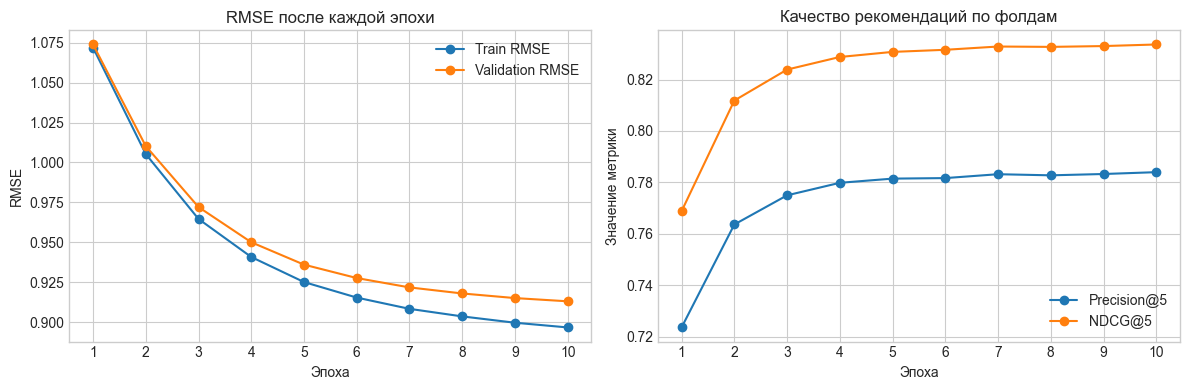

In [29]:
mlp_run = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.0
)

На 10-й эпохе получены средние по пяти фолдам: RMSE на проверке 0.9130, Precision@5 0.7840, NDCG@5 0.8336. Ошибка на обучении и проверке продолжает снижаться, а метрики ранжирования растут медленнее к концу обучения. Явного ухудшения качества на этих десяти эпохах не видно.

Проверим, как скорость обучения влияет на MLP. В одном цикле обучим модель с learning_rate=0.0005 и 0.002 и сравним оба варианта с исходным 0.001. Архитектуру, остальные настройки и пять фолдов не меняем. Посмотрим, как быстро улучшаются метрики за 10 эпох и на какой эпохе достигается лучший NDCG@5.


Learning rate: 0.0005
Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.0005
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.1023, Validation RMSE = 1.1052, Precision@5 = 0.6837, NDCG@5 = 0.7250
  Эпоха 2/10: Train RMSE = 1.0695, Validation RMSE = 1.0739, Precision@5 = 0.7274, NDCG@5 = 0.7719
  Эпоха 3/10: Train RMSE = 1.0325, Validation RMSE = 1.0381, Precision@5 = 0.7514, NDCG@5 = 0.7990
  Эпоха 4/10: Train RMSE = 1.0035, Validation RMSE = 1.0099, Precision@5 = 0.7626, NDCG@5 = 0.8118
  Эпоха 5/10: Train RMSE = 0.9798, Validation RMSE = 0.9871, Precision@5 = 0.7693, NDCG@5 = 0.8191
  Эпоха 6/10: Train RMSE = 0.9625, Validation RMSE = 0.9706, Precision@5 = 0.7741, NDCG@5 = 0.8245
  Эпоха 7/10: Train RMSE = 0.9486, Validation RMSE = 0.9576, Precision@5 = 0.7755, NDCG@5 = 0.8266
  Эпоха 8/10: Train RMSE = 0.9384, Validation RMSE = 0.9481, Precision@5 = 0.7776, NDCG@5 = 0.8282
  Эпоха 9/10: Train RMSE = 0.9

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.1023,1.1052,0.6837,0.7250
1,1,2,1.0695,1.0739,0.7274,0.7719
2,1,3,1.0325,1.0381,0.7514,0.7990
3,1,4,1.0035,1.0099,0.7626,0.8118
4,1,5,0.9798,0.9871,0.7693,0.8191
5,1,6,0.9625,0.9706,0.7741,0.8245
6,1,7,0.9486,0.9576,0.7755,0.8266
7,1,8,0.9384,0.9481,0.7776,0.8282
8,1,9,0.9307,0.9409,0.7798,0.8307
9,1,10,0.9235,0.9345,0.7811,0.8316


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.1022  0.0010          1.1029  0.0019      0.6841  0.0047  0.7237   
2         1.0670  0.0026          1.0690  0.0042      0.7293  0.0038  0.7747   
3         1.0297  0.0032          1.0336  0.0044      0.7540  0.0032  0.8013   
4         1.0010  0.0026          1.0062  0.0035      0.7651  0.0032  0.8136   
5         0.9786  0.0018          0.9853  0.0025      0.7717  0.0024  0.8203   
6         0.9624  0.0011          0.9702  0.0018      0.7753  0.0021  0.8242   
7         0.9493  0.0010          0.9581  0.0016      0.7780  0.0025  0.8272   
8         0.9395  0.0009          0.9490  0.0014      0.7799  0.0024  0.8291   
9         0.9312  0.0008          0.9417  0.0014      0.7813  0.0018  0.8306   
10        0.9248  0.0011          0.9359  0.0017      0.7818  0.0017  0.8314   

               
          std  
эпоха          
1      0.0038  
2      0.0037  
3      0.0023  
4      0.0021  
5      0.0019  
6      0.0012  
7      0.0013  
8      0.0014  
9      0.0015  
10     0.0014

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8314)


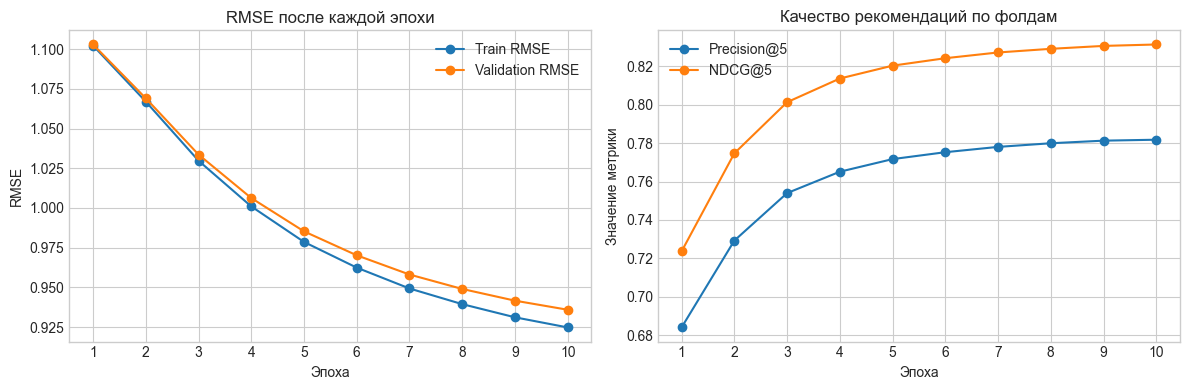


Learning rate: 0.002
Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.002
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0172, Validation RMSE = 1.0226, Precision@5 = 0.7566, NDCG@5 = 0.8057
  Эпоха 2/10: Train RMSE = 0.9434, Validation RMSE = 0.9522, Precision@5 = 0.7751, NDCG@5 = 0.8260
  Эпоха 3/10: Train RMSE = 0.9155, Validation RMSE = 0.9269, Precision@5 = 0.7805, NDCG@5 = 0.8315
  Эпоха 4/10: Train RMSE = 0.9039, Validation RMSE = 0.9169, Precision@5 = 0.7831, NDCG@5 = 0.8341
  Эпоха 5/10: Train RMSE = 0.8988, Validation RMSE = 0.9128, Precision@5 = 0.7836, NDCG@5 = 0.8346
  Эпоха 6/10: Train RMSE = 0.8954, Validation RMSE = 0.9106, Precision@5 = 0.7831, NDCG@5 = 0.8350
  Эпоха 7/10: Train RMSE = 0.8918, Validation RMSE = 0.9086, Precision@5 = 0.7831, NDCG@5 = 0.8344
  Эпоха 8/10: Train RMSE = 0.8901, Validation RMSE = 0.9078, Precision@5 = 0.7820, NDCG@5 = 0.8336
  Эпоха 9/10: Train RMSE = 0.888

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0172,1.0226,0.7566,0.8057
1,1,2,0.9434,0.9522,0.7751,0.8260
2,1,3,0.9155,0.9269,0.7805,0.8315
3,1,4,0.9039,0.9169,0.7831,0.8341
4,1,5,0.8988,0.9128,0.7836,0.8346
5,1,6,0.8954,0.9106,0.7831,0.8350
6,1,7,0.8918,0.9086,0.7831,0.8344
7,1,8,0.8901,0.9078,0.7820,0.8336
8,1,9,0.8886,0.9073,0.7827,0.8349
9,1,10,0.8876,0.9069,0.7831,0.8348


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0148  0.0026          1.0192  0.0035      0.7603  0.0025  0.8086   
2         0.9448  0.0010          0.9535  0.0015      0.7782  0.0019  0.8273   
3         0.9174  0.0012          0.9290  0.0019      0.7816  0.0008  0.8312   
4         0.9050  0.0011          0.9186  0.0015      0.7825  0.0011  0.8323   
5         0.8983  0.0006          0.9135  0.0012      0.7838  0.0012  0.8335   
6         0.8943  0.0010          0.9109  0.0016      0.7839  0.0016  0.8337   
7         0.8914  0.0006          0.9092  0.0016      0.7841  0.0020  0.8337   
8         0.8891  0.0014          0.9079  0.0014      0.7834  0.0016  0.8331   
9         0.8875  0.0017          0.9072  0.0016      0.7833  0.0013  0.8333   
10        0.8850  0.0018          0.9061  0.0015      0.7834  0.0017  0.8333   

               
          std  
эпоха          
1      0.0022  
2      0.0017  
3      0.0013  
4      0.0018  
5      0.0013  
6      0.0013  
7      0.0019  
8      0.0011  
9      0.0015  
10     0.0015

Лучшая эпоха по среднему NDCG@5: 7 (NDCG@5 = 0.8337)


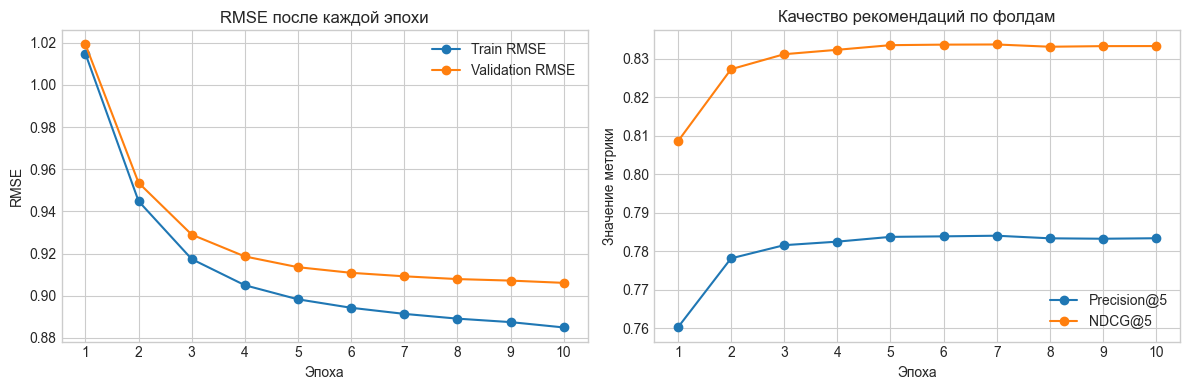

In [30]:
mlp_lr_results = {}

for lr in [0.0005, 0.002]:
    print(f"\nLearning rate: {lr}")

    mlp_lr_results[lr] = run_mlp_cv(
        n_epochs=10,
        learning_rate=lr,
        batch_size=4096,
        embedding_dim=32,
        hidden_dims=(64, 32),
        dropout=0.2,
        weight_decay=0.0,
        use_batch_norm=False,
        seed=42
    )

При learning_rate=0.0005 лучший NDCG@5 составил 0.8314 на 10-й эпохе: модель ещё улучшалась, но за отведённые 10 эпох уступила исходному варианту (0.8336). При learning_rate=0.002 лучший NDCG@5 составил 0.8337 на 7-й эпохе, а к 10-й немного снизился до 0.8333. Увеличенная скорость дала почти тот же лучший результат, что и исходная. Поэтому заметного выигрыша от изменения learning_rate в этих запусках не получили.

Вернём исходный learning_rate=0.001 и добавим слабую регуляризацию весов: weight_decay=0.00001. Архитектуру и dropout=0.2 не меняем. Проверим, уменьшится ли разница между ошибками обучения и проверки и улучшится ли ранжирование.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 1e-05
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0859, Validation RMSE = 1.0894, Precision@5 = 0.7159, NDCG@5 = 0.7605
  Эпоха 2/10: Train RMSE = 1.0220, Validation RMSE = 1.0273, Precision@5 = 0.7586, NDCG@5 = 0.8090
  Эпоха 3/10: Train RMSE = 0.9745, Validation RMSE = 0.9813, Precision@5 = 0.7726, NDCG@5 = 0.8238
  Эпоха 4/10: Train RMSE = 0.9454, Validation RMSE = 0.9537, Precision@5 = 0.7782, NDCG@5 = 0.8288
  Эпоха 5/10: Train RMSE = 0.9264, Validation RMSE = 0.9363, Precision@5 = 0.7819, NDCG@5 = 0.8313
  Эпоха 6/10: Train RMSE = 0.9139, Validation RMSE = 0.9253, Precision@5 = 0.7809, NDCG@5 = 0.8320
  Эпоха 7/10: Train RMSE = 0.9057, Validation RMSE = 0.9186, Precision@5 = 0.7810, NDCG@5 = 0.8325
  Эпоха 8/10: Train RMSE = 0.9006, Validation RMSE = 0.9144, Precision@5 = 0.7795, NDCG@5 = 0.8321
  Эпоха 9/10: Train RMSE = 0.8970, Validation RMSE =

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0859,1.0894,0.7159,0.7605
1,1,2,1.0220,1.0273,0.7586,0.8090
2,1,3,0.9745,0.9813,0.7726,0.8238
3,1,4,0.9454,0.9537,0.7782,0.8288
4,1,5,0.9264,0.9363,0.7819,0.8313
5,1,6,0.9139,0.9253,0.7809,0.8320
6,1,7,0.9057,0.9186,0.7810,0.8325
7,1,8,0.9006,0.9144,0.7795,0.8321
8,1,9,0.8970,0.9118,0.7811,0.8332
9,1,10,0.8935,0.9097,0.7821,0.8335


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0829  0.0025          1.0841  0.0042      0.7171  0.0042  0.7628   
2         1.0185  0.0031          1.0224  0.0042      0.7635  0.0039  0.8120   
3         0.9727  0.0015          0.9789  0.0022      0.7755  0.0027  0.8247   
4         0.9448  0.0006          0.9529  0.0015      0.7799  0.0019  0.8295   
5         0.9261  0.0005          0.9361  0.0014      0.7822  0.0010  0.8315   
6         0.9147  0.0009          0.9262  0.0012      0.7824  0.0012  0.8321   
7         0.9064  0.0008          0.9195  0.0013      0.7832  0.0021  0.8328   
8         0.9009  0.0005          0.9153  0.0015      0.7826  0.0022  0.8327   
9         0.8964  0.0009          0.9122  0.0015      0.7834  0.0019  0.8331   
10        0.8932  0.0008          0.9101  0.0018      0.7836  0.0016  0.8334   

               
          std  
эпоха          
1      0.0037  
2      0.0027  
3      0.0021  
4      0.0020  
5      0.0019  
6      0.0015  
7      0.0019  
8      0.0019  
9      0.0016  
10     0.0020

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8334)


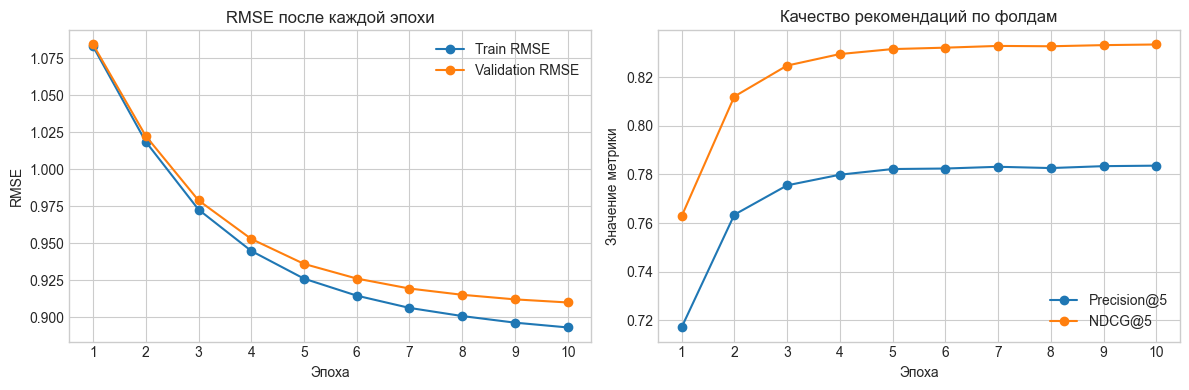

In [31]:
mlp_wd_00001 = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.00001,
    use_batch_norm=False,
    seed=42
)

На 10-й эпохе RMSE на проверке равен 0.9101, Precision@5 — 0.7836, NDCG@5 — 0.8334. RMSE немного ниже исходного (0.9130), но NDCG@5 практически не изменился и чуть ниже исходного (0.8336). Заметного улучшения главной метрики этот вариант не дал.

Увеличим weight_decay в десять раз — до 0.0001. По сравнению с предыдущим запуском меняется только сила этой регуляризации. Проверим, помогает ли более сильное ограничение весов или мешает модели обучиться за 10 эпох.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0001
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.1004, Validation RMSE = 1.1034, Precision@5 = 0.6946, NDCG@5 = 0.7362
  Эпоха 2/10: Train RMSE = 1.0650, Validation RMSE = 1.0690, Precision@5 = 0.7418, NDCG@5 = 0.7898
  Эпоха 3/10: Train RMSE = 1.0321, Validation RMSE = 1.0363, Precision@5 = 0.7620, NDCG@5 = 0.8120
  Эпоха 4/10: Train RMSE = 1.0056, Validation RMSE = 1.0104, Precision@5 = 0.7701, NDCG@5 = 0.8201
  Эпоха 5/10: Train RMSE = 0.9820, Validation RMSE = 0.9880, Precision@5 = 0.7759, NDCG@5 = 0.8257
  Эпоха 6/10: Train RMSE = 0.9623, Validation RMSE = 0.9699, Precision@5 = 0.7766, NDCG@5 = 0.8276
  Эпоха 7/10: Train RMSE = 0.9459, Validation RMSE = 0.9546, Precision@5 = 0.7770, NDCG@5 = 0.8283
  Эпоха 8/10: Train RMSE = 0.9328, Validation RMSE = 0.9427, Precision@5 = 0.7771, NDCG@5 = 0.8290
  Эпоха 9/10: Train RMSE = 0.9240, Validation RMSE 

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.1004,1.1034,0.6946,0.7362
1,1,2,1.0650,1.0690,0.7418,0.7898
2,1,3,1.0321,1.0363,0.7620,0.8120
3,1,4,1.0056,1.0104,0.7701,0.8201
4,1,5,0.9820,0.9880,0.7759,0.8257
5,1,6,0.9623,0.9699,0.7766,0.8276
6,1,7,0.9459,0.9546,0.7770,0.8283
7,1,8,0.9328,0.9427,0.7771,0.8290
8,1,9,0.9240,0.9353,0.7809,0.8318
9,1,10,0.9152,0.9278,0.7797,0.8320


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0985  0.0017          1.0992  0.0035      0.6931  0.0055  0.7353   
2         1.0627  0.0027          1.0648  0.0046      0.7417  0.0054  0.7889   
3         1.0296  0.0024          1.0330  0.0038      0.7622  0.0037  0.8105   
4         1.0027  0.0022          1.0073  0.0031      0.7709  0.0031  0.8198   
5         0.9794  0.0025          0.9853  0.0029      0.7757  0.0016  0.8249   
6         0.9612  0.0017          0.9683  0.0021      0.7773  0.0010  0.8267   
7         0.9450  0.0007          0.9536  0.0014      0.7799  0.0025  0.8293   
8         0.9331  0.0010          0.9430  0.0010      0.7796  0.0019  0.8295   
9         0.9229  0.0011          0.9344  0.0011      0.7813  0.0010  0.8309   
10        0.9152  0.0008          0.9280  0.0012      0.7815  0.0016  0.8314   

               
          std  
эпоха          
1      0.0050  
2      0.0053  
3      0.0043  
4      0.0032  
5      0.0028  
6      0.0021  
7      0.0023  
8      0.0017  
9      0.0023  
10     0.0014

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8314)


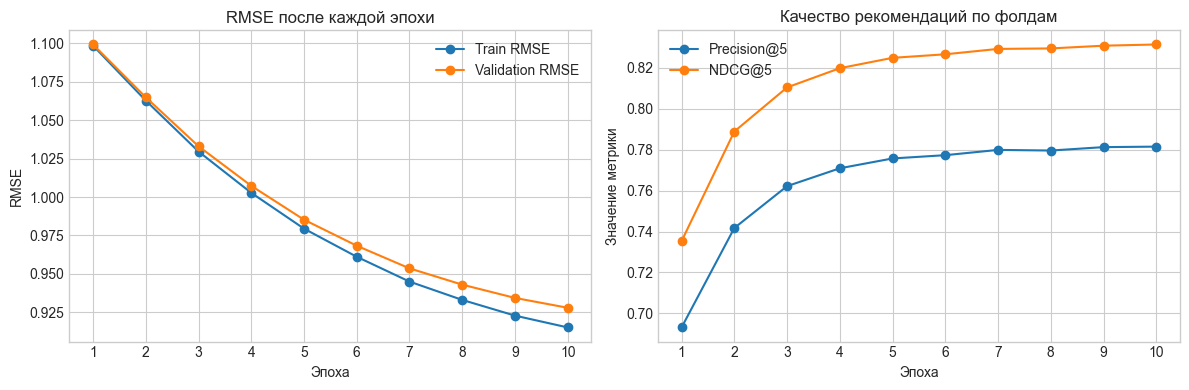

In [32]:
mlp_wd_0001 = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.0001,
    use_batch_norm=False,
    seed=42
)

На 10-й эпохе RMSE на проверке равен 0.9280, Precision@5 — 0.7815, NDCG@5 — 0.8314. Все три значения хуже исходного запуска. При данных настройках и десяти эпохах усиление weight_decay не помогло.

### Промежуточный вывод: learning rate и weight decay

Среди проверенных значений `learning_rate` и `weight_decay` заметного улучшения NDCG@5 по сравнению с исходной настройкой не получено. Это ещё не итоговый выбор MLP: размер эмбеддингов, скрытые слои и длительность обучения пока не проверены.

### Гиперпараметры MLP

| Гиперпараметр | За что отвечает | Исходное значение | Что уже проверили |
|---|---|---:|---|
| `n_epochs` | Число эпох обучения | `10` | Только `10` |
| `learning_rate` | Размер шага при обновлении весов | `0.001` | `0.0005`, `0.001`, `0.002` |
| `batch_size` | Число оценок в одном батче | `4096` | Не меняли |
| `embedding_dim` | Размер векторов пользователя и фильма | `32` | Не меняли |
| `hidden_dims` | Размеры скрытых слоёв | `(64, 32)` | Не меняли |
| `dropout` | Доля временно отключаемых нейронов | `0.2` | Не меняли |
| `weight_decay` | Сила регуляризации весов | `0` | `0`, `0.00001`, `0.0001` |
| `use_batch_norm` | Нормализация внутри сети | `False` | Не меняли |

### 8.5 Проверка BatchNorm

Добавим BatchNorm после линейных слоёв MLP и сравним результат с исходной моделью, где BatchNorm выключен. Нормализация может сделать обучение устойчивее, но её пользу нужно проверить на данных.

Меняем только `use_batch_norm` с `False` на `True`. Архитектуру, `learning_rate=0.001`, `dropout=0.2`, размер батча и остальные настройки оставляем прежними. Обучаем модель 10 эпох на тех же пяти фолдах. Сравним графики обучения и прежде всего NDCG@5; дополнительно посмотрим на Precision@5 и RMSE.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: True
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0921, Validation RMSE = 1.0956, Precision@5 = 0.7080, NDCG@5 = 0.7527
  Эпоха 2/10: Train RMSE = 1.0430, Validation RMSE = 1.0480, Precision@5 = 0.7523, NDCG@5 = 0.8001
  Эпоха 3/10: Train RMSE = 0.9954, Validation RMSE = 1.0014, Precision@5 = 0.7706, NDCG@5 = 0.8204
  Эпоха 4/10: Train RMSE = 0.9628, Validation RMSE = 0.9704, Precision@5 = 0.7767, NDCG@5 = 0.8266
  Эпоха 5/10: Train RMSE = 0.9393, Validation RMSE = 0.9488, Precision@5 = 0.7790, NDCG@5 = 0.8298
  Эпоха 6/10: Train RMSE = 0.9251, Validation RMSE = 0.9359, Precision@5 = 0.7801, NDCG@5 = 0.8315
  Эпоха 7/10: Train RMSE = 0.9149, Validation RMSE = 0.9267, Precision@5 = 0.7803, NDCG@5 = 0.8316
  Эпоха 8/10: Train RMSE = 0.9083, Validation RMSE = 0.9210, Precision@5 = 0.7818, NDCG@5 = 0.8333
  Эпоха 9/10: Train RMSE = 0.9043, Validation RMSE = 0.

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0921,1.0956,0.7080,0.7527
1,1,2,1.0430,1.0480,0.7523,0.8001
2,1,3,0.9954,1.0014,0.7706,0.8204
3,1,4,0.9628,0.9704,0.7767,0.8266
4,1,5,0.9393,0.9488,0.7790,0.8298
5,1,6,0.9251,0.9359,0.7801,0.8315
6,1,7,0.9149,0.9267,0.7803,0.8316
7,1,8,0.9083,0.9210,0.7818,0.8333
8,1,9,0.9043,0.9176,0.7819,0.8334
9,1,10,0.9000,0.9145,0.7815,0.8332


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0883  0.0032          1.0899  0.0034      0.7094  0.0044  0.7533   
2         1.0430  0.0048          1.0464  0.0058      0.7513  0.0041  0.7991   
3         0.9984  0.0073          1.0037  0.0075      0.7694  0.0036  0.8181   
4         0.9663  0.0067          0.9734  0.0069      0.7773  0.0016  0.8257   
5         0.9433  0.0061          0.9523  0.0062      0.7798  0.0010  0.8291   
6         0.9287  0.0047          0.9392  0.0050      0.7811  0.0014  0.8304   
7         0.9180  0.0041          0.9299  0.0044      0.7822  0.0019  0.8317   
8         0.9109  0.0030          0.9237  0.0035      0.7827  0.0016  0.8323   
9         0.9053  0.0022          0.9193  0.0027      0.7829  0.0022  0.8327   
10        0.9016  0.0020          0.9165  0.0024      0.7827  0.0019  0.8327   

               
          std  
эпоха          
1      0.0036  
2      0.0033  
3      0.0039  
4      0.0019  
5      0.0018  
6      0.0016  
7      0.0017  
8      0.0014  
9      0.0019  
10     0.0023

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8327)


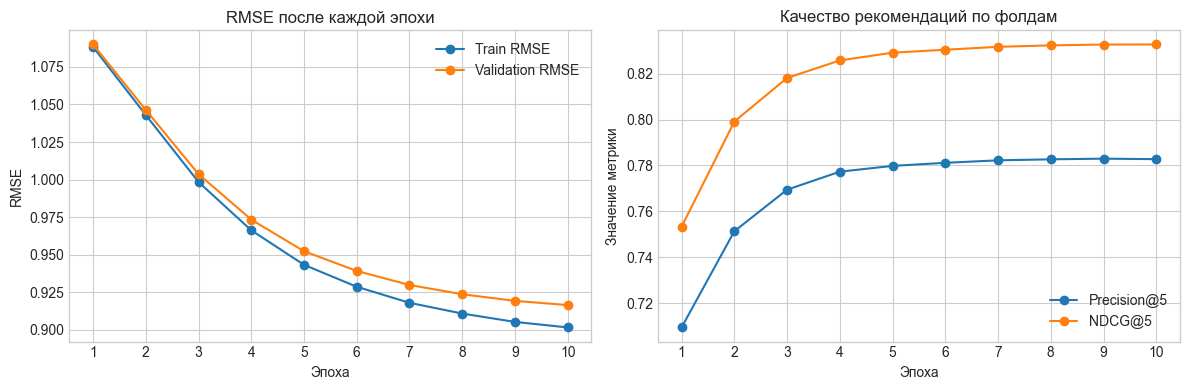

In [17]:
mlp_bn = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=True,
    seed=42
)

При добавлении BatchNorm на 10-й эпохе получили средний NDCG@5 = **0.8327**, Precision@5 = **0.7827** и RMSE на проверке = **0.9165**. У исходной MLP без BatchNorm соответствующие значения были **0.8336**, **0.7840** и **0.9130**.

На графиках качество модели с BatchNorm продолжает улучшаться к концу обучения, но за 10 эпох она не превзошла исходный вариант. Поэтому в следующих экспериментах пока оставим `use_batch_norm=False`. Этот результат относится к проверенной архитектуре и длительности обучения.

### 8.6 Проверка Dropout

В исходной MLP используется `dropout=0.2`. Сначала обучим ту же модель без Dropout (`dropout=0`) и проверим, влияет ли эта регуляризация на качество рекомендаций.

Все остальные настройки оставим исходными, включая `use_batch_norm=False`. Сравним модели на тех же пяти фолдах за 10 эпох по NDCG@5, Precision@5 и RMSE, а также посмотрим на разницу между ошибками обучения и проверки.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.0
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0522, Validation RMSE = 1.0577, Precision@5 = 0.7395, NDCG@5 = 0.7861
  Эпоха 2/10: Train RMSE = 0.9807, Validation RMSE = 0.9902, Precision@5 = 0.7669, NDCG@5 = 0.8163
  Эпоха 3/10: Train RMSE = 0.9451, Validation RMSE = 0.9585, Precision@5 = 0.7755, NDCG@5 = 0.8251
  Эпоха 4/10: Train RMSE = 0.9249, Validation RMSE = 0.9411, Precision@5 = 0.7777, NDCG@5 = 0.8285
  Эпоха 5/10: Train RMSE = 0.9127, Validation RMSE = 0.9314, Precision@5 = 0.7793, NDCG@5 = 0.8308
  Эпоха 6/10: Train RMSE = 0.9048, Validation RMSE = 0.9262, Precision@5 = 0.7791, NDCG@5 = 0.8299
  Эпоха 7/10: Train RMSE = 0.8989, Validation RMSE = 0.9223, Precision@5 = 0.7790, NDCG@5 = 0.8297
  Эпоха 8/10: Train RMSE = 0.8944, Validation RMSE = 0.9200, Precision@5 = 0.7788, NDCG@5 = 0.8298
  Эпоха 9/10: Train RMSE = 0.8913, Validation RMSE = 0

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0522,1.0577,0.7395,0.7861
1,1,2,0.9807,0.9902,0.7669,0.8163
2,1,3,0.9451,0.9585,0.7755,0.8251
3,1,4,0.9249,0.9411,0.7777,0.8285
4,1,5,0.9127,0.9314,0.7793,0.8308
5,1,6,0.9048,0.9262,0.7791,0.8299
6,1,7,0.8989,0.9223,0.7790,0.8297
7,1,8,0.8944,0.9200,0.7788,0.8298
8,1,9,0.8913,0.9182,0.7801,0.8310
9,1,10,0.8880,0.9171,0.7793,0.8301


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0490  0.0038          1.0526  0.0049      0.7389  0.0032  0.7853   
2         0.9795  0.0021          0.9888  0.0027      0.7684  0.0015  0.8167   
3         0.9446  0.0008          0.9580  0.0015      0.7759  0.0024  0.8244   
4         0.9251  0.0005          0.9417  0.0011      0.7780  0.0026  0.8269   
5         0.9131  0.0005          0.9326  0.0012      0.7792  0.0012  0.8287   
6         0.9051  0.0006          0.9271  0.0013      0.7790  0.0014  0.8279   
7         0.8994  0.0006          0.9235  0.0014      0.7796  0.0022  0.8289   
8         0.8946  0.0004          0.9207  0.0012      0.7790  0.0018  0.8284   
9         0.8915  0.0003          0.9193  0.0017      0.7800  0.0018  0.8291   
10        0.8883  0.0002          0.9180  0.0014      0.7793  0.0014  0.8285   

               
          std  
эпоха          
1      0.0033  
2      0.0022  
3      0.0022  
4      0.0028  
5      0.0021  
6      0.0022  
7      0.0027  
8      0.0016  
9      0.0022  
10     0.0021

Лучшая эпоха по среднему NDCG@5: 9 (NDCG@5 = 0.8291)


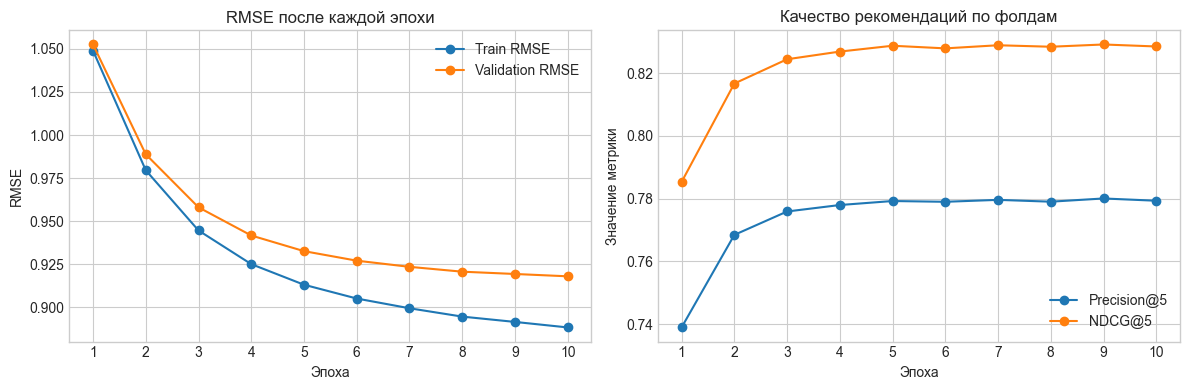

In [18]:
mlp_dropout_0 = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.0,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

Без Dropout ошибка на обучении к 10-й эпохе снизилась до **0.8883** против **0.8967** у исходной модели. Однако ошибка на проверке выросла с **0.9130** до **0.9180**, а NDCG@5 снизился с **0.8336** до **0.8285**. Лучший NDCG@5 без Dropout составил **0.8291** на 9-й эпохе.

Модель лучше подстроилась под обучающие оценки, но хуже сработала на отложенных. В этом сравнении `dropout=0.2` оказался полезен.

Теперь увеличим Dropout с исходных `0.2` до `0.4`. Остальные настройки оставим прежними. Проверим, улучшит ли более сильная регуляризация качество на проверке или начнёт мешать модели обучаться. Сравним NDCG@5, Precision@5, RMSE и графики за те же 10 эпох на пяти фолдах.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.4
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0941, Validation RMSE = 1.0973, Precision@5 = 0.6994, NDCG@5 = 0.7431
  Эпоха 2/10: Train RMSE = 1.0305, Validation RMSE = 1.0352, Precision@5 = 0.7522, NDCG@5 = 0.8004
  Эпоха 3/10: Train RMSE = 0.9785, Validation RMSE = 0.9847, Precision@5 = 0.7712, NDCG@5 = 0.8207
  Эпоха 4/10: Train RMSE = 0.9469, Validation RMSE = 0.9545, Precision@5 = 0.7770, NDCG@5 = 0.8282
  Эпоха 5/10: Train RMSE = 0.9285, Validation RMSE = 0.9376, Precision@5 = 0.7813, NDCG@5 = 0.8321
  Эпоха 6/10: Train RMSE = 0.9155, Validation RMSE = 0.9261, Precision@5 = 0.7822, NDCG@5 = 0.8337
  Эпоха 7/10: Train RMSE = 0.9082, Validation RMSE = 0.9199, Precision@5 = 0.7835, NDCG@5 = 0.8350
  Эпоха 8/10: Train RMSE = 0.9040, Validation RMSE = 0.9162, Precision@5 = 0.7831, NDCG@5 = 0.8347
  Эпоха 9/10: Train RMSE = 0.9006, Validation RMSE = 0

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0941,1.0973,0.6994,0.7431
1,1,2,1.0305,1.0352,0.7522,0.8004
2,1,3,0.9785,0.9847,0.7712,0.8207
3,1,4,0.9469,0.9545,0.7770,0.8282
4,1,5,0.9285,0.9376,0.7813,0.8321
5,1,6,0.9155,0.9261,0.7822,0.8337
6,1,7,0.9082,0.9199,0.7835,0.8350
7,1,8,0.9040,0.9162,0.7831,0.8347
8,1,9,0.9006,0.9134,0.7842,0.8357
9,1,10,0.8976,0.9113,0.7825,0.8343


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0945  0.0022          1.0954  0.0025      0.7000  0.0039  0.7431   
2         1.0324  0.0028          1.0355  0.0034      0.7544  0.0029  0.8023   
3         0.9814  0.0024          0.9869  0.0028      0.7720  0.0019  0.8206   
4         0.9506  0.0027          0.9581  0.0031      0.7783  0.0018  0.8274   
5         0.9310  0.0018          0.9403  0.0025      0.7815  0.0015  0.8310   
6         0.9192  0.0022          0.9301  0.0027      0.7827  0.0019  0.8323   
7         0.9112  0.0019          0.9233  0.0025      0.7838  0.0019  0.8336   
8         0.9060  0.0012          0.9189  0.0022      0.7835  0.0012  0.8334   
9         0.9016  0.0009          0.9156  0.0016      0.7836  0.0016  0.8337   
10        0.8986  0.0009          0.9134  0.0020      0.7839  0.0015  0.8339   

               
          std  
эпоха          
1      0.0025  
2      0.0021  
3      0.0011  
4      0.0014  
5      0.0012  
6      0.0013  
7      0.0013  
8      0.0013  
9      0.0019  
10     0.0013

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8339)


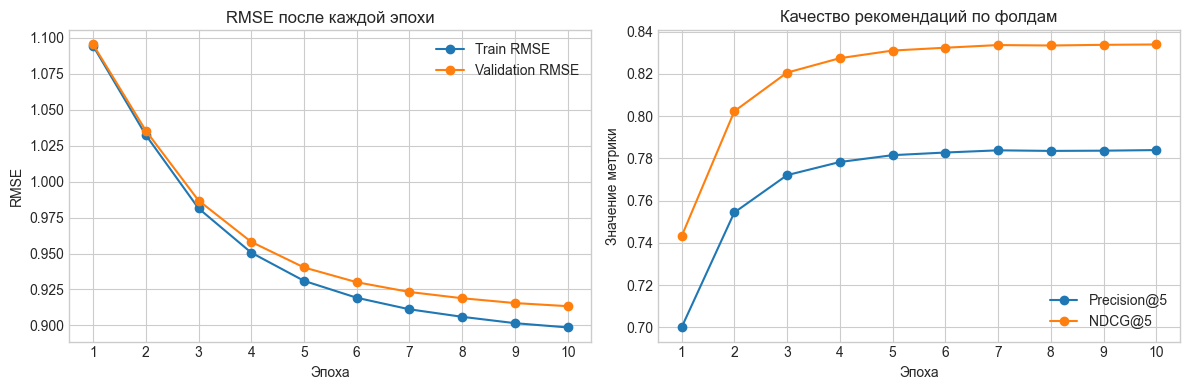

In [19]:
mlp_dropout_04 = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.4,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

При `dropout=0.4` на 10-й эпохе средний NDCG@5 составил **0.8339**, Precision@5 — **0.7839**, RMSE на проверке — **0.9134**. У исходной модели с `dropout=0.2` значения равны **0.8336**, **0.7840** и **0.9130** соответственно.

Различия между `dropout=0.2` и `0.4` очень малы: по этому эксперименту нельзя уверенно назвать один вариант лучше. При `dropout=0` качество ранжирования было ниже. Для следующих проверок оставим исходное `dropout=0.2`; вывод о его точном оптимальном значении пока не делаем.

### 8.7 Проверка числа и размера скрытых слоёв

Исходная MLP имеет два скрытых слоя размером `(64, 32)`. Проверим три варианта архитектуры:

1. `(128, 64)` — два слоя большего размера: выясним, помогает ли увеличение ширины.
2. `(64,)` — один скрытый слой: проверим, достаточно ли более простой сети.
3. `(64, 32, 16)` — три скрытых слоя: проверим, помогает ли дополнительная глубина.

В каждом эксперименте меняем только `hidden_dims`. Размер эмбеддингов оставляем равным 32, `learning_rate=0.001`, `dropout=0.2`, BatchNorm выключен. Все варианты обучаем 10 эпох на тех же пяти фолдах и сравниваем прежде всего по NDCG@5, дополнительно — по Precision@5 и RMSE.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (128, 64)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0588, Validation RMSE = 1.0637, Precision@5 = 0.7372, NDCG@5 = 0.7845
  Эпоха 2/10: Train RMSE = 0.9953, Validation RMSE = 1.0027, Precision@5 = 0.7682, NDCG@5 = 0.8182
  Эпоха 3/10: Train RMSE = 0.9582, Validation RMSE = 0.9677, Precision@5 = 0.7758, NDCG@5 = 0.8262
  Эпоха 4/10: Train RMSE = 0.9377, Validation RMSE = 0.9489, Precision@5 = 0.7814, NDCG@5 = 0.8319
  Эпоха 5/10: Train RMSE = 0.9238, Validation RMSE = 0.9361, Precision@5 = 0.7795, NDCG@5 = 0.8308
  Эпоха 6/10: Train RMSE = 0.9150, Validation RMSE = 0.9281, Precision@5 = 0.7818, NDCG@5 = 0.8331
  Эпоха 7/10: Train RMSE = 0.9072, Validation RMSE = 0.9214, Precision@5 = 0.7829, NDCG@5 = 0.8346
  Эпоха 8/10: Train RMSE = 0.9025, Validation RMSE = 0.9180, Precision@5 = 0.7822, NDCG@5 = 0.8344
  Эпоха 9/10: Train RMSE = 0.8989, Validation RMSE = 

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0588,1.0637,0.7372,0.7845
1,1,2,0.9953,1.0027,0.7682,0.8182
2,1,3,0.9582,0.9677,0.7758,0.8262
3,1,4,0.9377,0.9489,0.7814,0.8319
4,1,5,0.9238,0.9361,0.7795,0.8308
5,1,6,0.9150,0.9281,0.7818,0.8331
6,1,7,0.9072,0.9214,0.7829,0.8346
7,1,8,0.9025,0.9180,0.7822,0.8344
8,1,9,0.8989,0.9152,0.7834,0.8351
9,1,10,0.8964,0.9134,0.7837,0.8350


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0547  0.0042          1.0578  0.0053      0.7392  0.0041  0.7866   
2         0.9924  0.0030          0.9990  0.0038      0.7680  0.0023  0.8171   
3         0.9570  0.0015          0.9664  0.0024      0.7766  0.0015  0.8257   
4         0.9366  0.0013          0.9479  0.0021      0.7801  0.0012  0.8297   
5         0.9224  0.0009          0.9353  0.0018      0.7811  0.0017  0.8310   
6         0.9138  0.0014          0.9279  0.0019      0.7822  0.0010  0.8321   
7         0.9071  0.0007          0.9223  0.0017      0.7826  0.0012  0.8326   
8         0.9022  0.0006          0.9186  0.0012      0.7827  0.0007  0.8329   
9         0.8981  0.0007          0.9155  0.0016      0.7829  0.0007  0.8329   
10        0.8953  0.0007          0.9137  0.0014      0.7835  0.0011  0.8333   

               
          std  
эпоха          
1      0.0037  
2      0.0025  
3      0.0023  
4      0.0025  
5      0.0020  
6      0.0023  
7      0.0024  
8      0.0019  
9      0.0020  
10     0.0021

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8333)


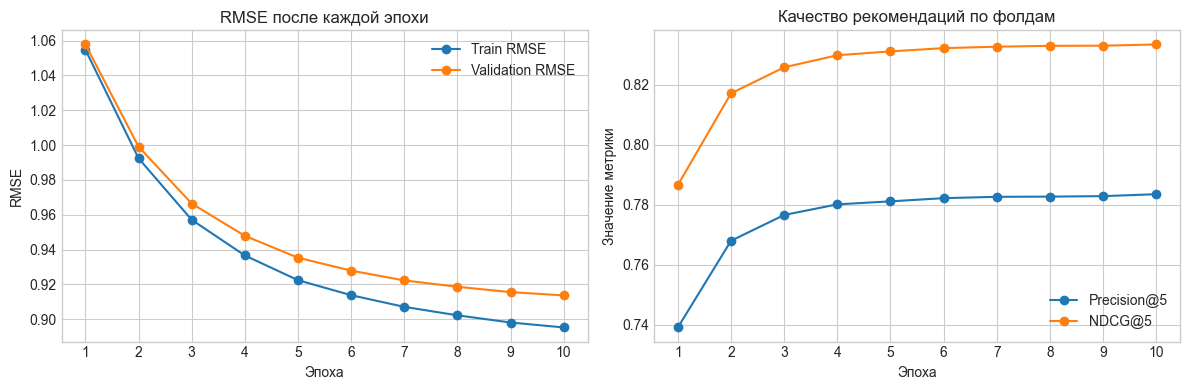

In [20]:
mlp_wider = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(128, 64),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

При увеличении скрытых слоёв с `(64, 32)` до `(128, 64)` на 10-й эпохе получили средний NDCG@5 = **0.8333**, Precision@5 = **0.7835** и RMSE на проверке = **0.9137**. У исходной сети значения составляли **0.8336**, **0.7840** и **0.9130**.

Более широкая сеть немного снизила ошибку на обучении, но не улучшила результаты на проверке. За 10 эпох дополнительная ширина не дала заметной пользы; дальше проверим, достаточно ли одного скрытого слоя.

Посмотрим что будет с одним слоем

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64,)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0775, Validation RMSE = 1.0812, Precision@5 = 0.7179, NDCG@5 = 0.7621
  Эпоха 2/10: Train RMSE = 1.0095, Validation RMSE = 1.0154, Precision@5 = 0.7612, NDCG@5 = 0.8106
  Эпоха 3/10: Train RMSE = 0.9663, Validation RMSE = 0.9740, Precision@5 = 0.7744, NDCG@5 = 0.8248
  Эпоха 4/10: Train RMSE = 0.9405, Validation RMSE = 0.9502, Precision@5 = 0.7804, NDCG@5 = 0.8309
  Эпоха 5/10: Train RMSE = 0.9248, Validation RMSE = 0.9358, Precision@5 = 0.7818, NDCG@5 = 0.8327
  Эпоха 6/10: Train RMSE = 0.9149, Validation RMSE = 0.9268, Precision@5 = 0.7830, NDCG@5 = 0.8341
  Эпоха 7/10: Train RMSE = 0.9081, Validation RMSE = 0.9209, Precision@5 = 0.7827, NDCG@5 = 0.8337
  Эпоха 8/10: Train RMSE = 0.9030, Validation RMSE = 0.9168, Precision@5 = 0.7821, NDCG@5 = 0.8333
  Эпоха 9/10: Train RMSE = 0.8996, Validation RMSE = 0.91

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0775,1.0812,0.7179,0.7621
1,1,2,1.0095,1.0154,0.7612,0.8106
2,1,3,0.9663,0.9740,0.7744,0.8248
3,1,4,0.9405,0.9502,0.7804,0.8309
4,1,5,0.9248,0.9358,0.7818,0.8327
5,1,6,0.9149,0.9268,0.7830,0.8341
6,1,7,0.9081,0.9209,0.7827,0.8337
7,1,8,0.9030,0.9168,0.7821,0.8333
8,1,9,0.8996,0.9141,0.7831,0.8343
9,1,10,0.8971,0.9121,0.7836,0.8351


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0743  0.0034          1.0761  0.0041      0.7198  0.0052  0.7641   
2         1.0079  0.0027          1.0130  0.0036      0.7625  0.0037  0.8111   
3         0.9656  0.0017          0.9731  0.0029      0.7745  0.0024  0.8237   
4         0.9404  0.0012          0.9500  0.0024      0.7794  0.0018  0.8287   
5         0.9248  0.0010          0.9360  0.0024      0.7817  0.0013  0.8313   
6         0.9147  0.0009          0.9272  0.0022      0.7825  0.0015  0.8323   
7         0.9079  0.0006          0.9214  0.0022      0.7828  0.0018  0.8329   
8         0.9030  0.0005          0.9175  0.0020      0.7832  0.0015  0.8330   
9         0.8995  0.0003          0.9148  0.0021      0.7835  0.0015  0.8333   
10        0.8969  0.0002          0.9127  0.0021      0.7834  0.0016  0.8335   

               
          std  
эпоха          
1      0.0047  
2      0.0031  
3      0.0025  
4      0.0023  
5      0.0021  
6      0.0022  
7      0.0020  
8      0.0018  
9      0.0018  
10     0.0019

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8335)


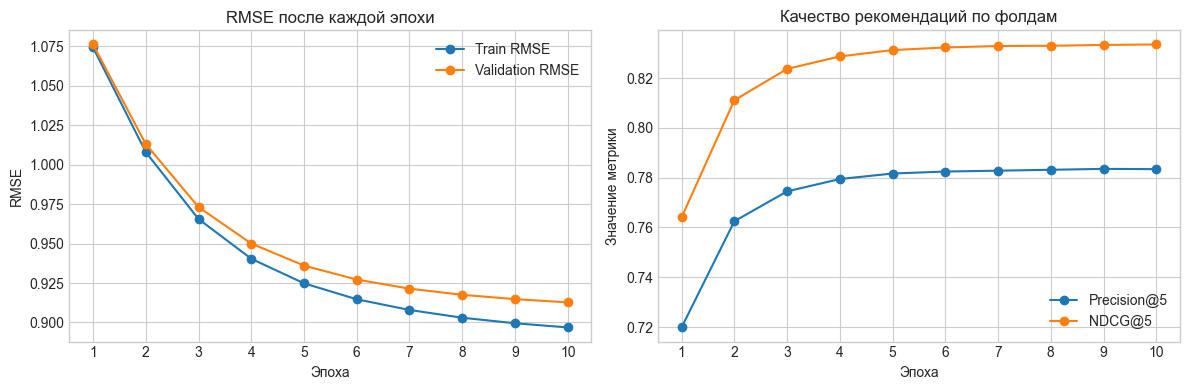

In [21]:
mlp_one_layer = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64,),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

Модель с одним скрытым слоем `(64,)` на 10-й эпохе получила средний NDCG@5 = **0.8335**, Precision@5 = **0.7834** и RMSE на проверке = **0.9127**. Результаты исходной сети с двумя слоями `(64, 32)` составили **0.8336**, **0.7840** и **0.9130**.

Качество практически не изменилось. Значит, в проверенных условиях второй скрытый слой не дал заметного преимущества. Пока не выбираем окончательную архитектуру: осталось проверить вариант с тремя слоями.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32, 16)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/10: Train RMSE = 1.0816, Validation RMSE = 1.0852, Precision@5 = 0.7080, NDCG@5 = 0.7490
  Эпоха 2/10: Train RMSE = 1.0090, Validation RMSE = 1.0152, Precision@5 = 0.7567, NDCG@5 = 0.8027
  Эпоха 3/10: Train RMSE = 0.9655, Validation RMSE = 0.9736, Precision@5 = 0.7728, NDCG@5 = 0.8218
  Эпоха 4/10: Train RMSE = 0.9409, Validation RMSE = 0.9504, Precision@5 = 0.7782, NDCG@5 = 0.8289
  Эпоха 5/10: Train RMSE = 0.9254, Validation RMSE = 0.9362, Precision@5 = 0.7797, NDCG@5 = 0.8306
  Эпоха 6/10: Train RMSE = 0.9166, Validation RMSE = 0.9281, Precision@5 = 0.7798, NDCG@5 = 0.8311
  Эпоха 7/10: Train RMSE = 0.9090, Validation RMSE = 0.9216, Precision@5 = 0.7806, NDCG@5 = 0.8320
  Эпоха 8/10: Train RMSE = 0.9049, Validation RMSE = 0.9183, Precision@5 = 0.7817, NDCG@5 = 0.8334
  Эпоха 9/10: Train RMSE = 0.9015, Validation RMSE

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0816,1.0852,0.7080,0.7490
1,1,2,1.0090,1.0152,0.7567,0.8027
2,1,3,0.9655,0.9736,0.7728,0.8218
3,1,4,0.9409,0.9504,0.7782,0.8289
4,1,5,0.9254,0.9362,0.7797,0.8306
5,1,6,0.9166,0.9281,0.7798,0.8311
6,1,7,0.9090,0.9216,0.7806,0.8320
7,1,8,0.9049,0.9183,0.7817,0.8334
8,1,9,0.9015,0.9155,0.7818,0.8331
9,1,10,0.8996,0.9141,0.7830,0.8343


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0747  0.0095          1.0766  0.0096      0.7166  0.0099  0.7596   
2         1.0054  0.0043          1.0105  0.0050      0.7624  0.0040  0.8098   
3         0.9645  0.0010          0.9721  0.0020      0.7745  0.0019  0.8231   
4         0.9406  0.0009          0.9501  0.0017      0.7788  0.0011  0.8281   
5         0.9251  0.0006          0.9363  0.0016      0.7808  0.0015  0.8306   
6         0.9160  0.0009          0.9283  0.0019      0.7819  0.0018  0.8317   
7         0.9089  0.0003          0.9223  0.0018      0.7832  0.0022  0.8330   
8         0.9045  0.0008          0.9187  0.0019      0.7834  0.0021  0.8333   
9         0.9006  0.0007          0.9157  0.0019      0.7837  0.0022  0.8333   
10        0.8986  0.0010          0.9142  0.0012      0.7841  0.0016  0.8339   

               
          std  
эпоха          
1      0.0105  
2      0.0051  
3      0.0029  
4      0.0022  
5      0.0015  
6      0.0011  
7      0.0017  
8      0.0013  
9      0.0010  
10     0.0008

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8339)


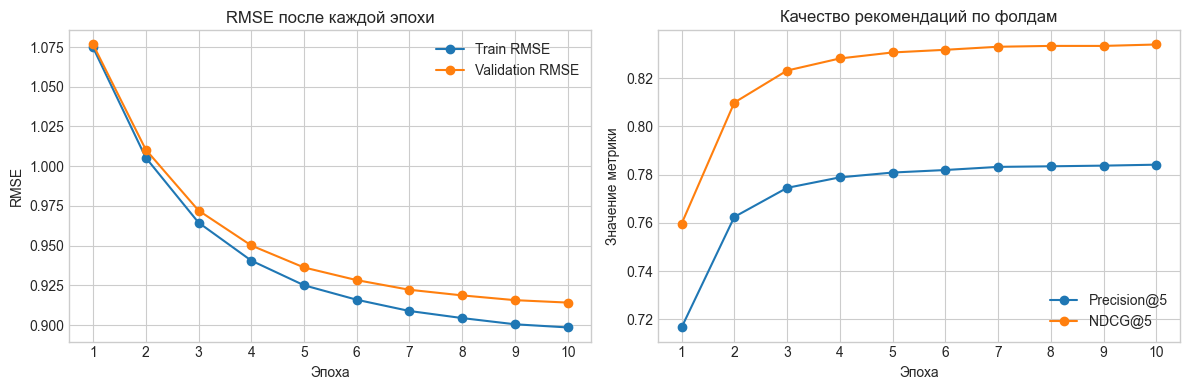

In [22]:
mlp_deeper = run_mlp_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32, 16),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

Модель с тремя скрытыми слоями `(64, 32, 16)` на 10-й эпохе получила средний NDCG@5 = **0.8339**, Precision@5 = **0.7841** и RMSE на проверке = **0.9142**. У исходной сети `(64, 32)` эти значения составляли **0.8336**, **0.7840** и **0.9130**.

Дополнительный слой дал очень небольшое улучшение метрик ранжирования, но увеличил ошибку прогноза оценок. Разница по NDCG@5 слишком мала, чтобы уверенно считать более глубокую архитектуру лучше.

### 8.8 Проверка длительности обучения

В исходном эксперименте качество MLP ещё улучшалось на 10-й эпохе. Поэтому обучим исходную архитектуру `(64, 32)` в течение 20 эпох вместо 10.

Все остальные настройки и пять фолдов оставим прежними. По графикам проверим, продолжает ли расти NDCG@5, на какой эпохе он достигает максимума и не начинает ли ухудшаться качество на проверке.

Устройство: mps
Эмбеддинг: 32
Скрытые слои: (64, 32)
Dropout: 0.2
BatchNorm: False
Learning rate: 0.001
Weight decay: 0.0
Размер батча: 4096

Фолд 1 из 5
  Эпоха 1/20: Train RMSE = 1.0742, Validation RMSE = 1.0784, Precision@5 = 0.7232, NDCG@5 = 0.7676
  Эпоха 2/20: Train RMSE = 1.0060, Validation RMSE = 1.0122, Precision@5 = 0.7593, NDCG@5 = 0.8091
  Эпоха 3/20: Train RMSE = 0.9645, Validation RMSE = 0.9723, Precision@5 = 0.7738, NDCG@5 = 0.8238
  Эпоха 4/20: Train RMSE = 0.9398, Validation RMSE = 0.9490, Precision@5 = 0.7782, NDCG@5 = 0.8284
  Эпоха 5/20: Train RMSE = 0.9248, Validation RMSE = 0.9353, Precision@5 = 0.7805, NDCG@5 = 0.8306
  Эпоха 6/20: Train RMSE = 0.9136, Validation RMSE = 0.9255, Precision@5 = 0.7803, NDCG@5 = 0.8319
  Эпоха 7/20: Train RMSE = 0.9070, Validation RMSE = 0.9199, Precision@5 = 0.7817, NDCG@5 = 0.8330
  Эпоха 8/20: Train RMSE = 0.9028, Validation RMSE = 0.9163, Precision@5 = 0.7808, NDCG@5 = 0.8326
  Эпоха 9/20: Train RMSE = 0.8994, Validation RMSE = 0

,фолд,эпоха,Train RMSE,Validation RMSE,Precision@5,NDCG@5
0,1,1,1.0742,1.0784,0.7232,0.7676
1,1,2,1.0060,1.0122,0.7593,0.8091
2,1,3,0.9645,0.9723,0.7738,0.8238
3,1,4,0.9398,0.9490,0.7782,0.8284
4,1,5,0.9248,0.9353,0.7805,0.8306
...,...,...,...,...,...,...
95,5,16,0.8854,0.9061,0.7838,0.8322
96,5,17,0.8840,0.9054,0.7843,0.8327
97,5,18,0.8836,0.9053,0.7849,0.8336
98,5,19,0.8816,0.9043,0.7848,0.8334


Train RMSE         Validation RMSE         Precision@5          NDCG@5  \
            mean     std            mean     std        mean     std    mean   
эпоха                                                                          
1         1.0720  0.0026          1.0739  0.0041      0.7237  0.0035  0.7688   
2         1.0053  0.0023          1.0103  0.0031      0.7637  0.0035  0.8120   
3         0.9646  0.0012          0.9721  0.0018      0.7751  0.0019  0.8239   
4         0.9408  0.0009          0.9500  0.0016      0.7797  0.0023  0.8288   
5         0.9251  0.0008          0.9360  0.0016      0.7817  0.0017  0.8309   
6         0.9154  0.0011          0.9276  0.0017      0.7818  0.0010  0.8316   
7         0.9083  0.0009          0.9217  0.0016      0.7832  0.0019  0.8329   
8         0.9036  0.0008          0.9179  0.0017      0.7830  0.0021  0.8330   
9         0.8996  0.0007          0.9150  0.0013      0.7831  0.0018  0.8329   
10        0.8967  0.0007          0.9130  0.0016      0.7837  0.0013  0.8334   
11        0.8946  0.0003          0.9117  0.0014      0.7835  0.0022  0.8336   
12        0.8932  0.0010          0.9108  0.0018      0.7834  0.0021  0.8334   
13        0.8911  0.0015          0.9097  0.0018      0.7831  0.0021  0.8332   
14        0.8897  0.0015          0.9088  0.0013      0.7834  0.0016  0.8334   
15        0.8888  0.0019          0.9085  0.0014      0.7835  0.0018  0.8334   
16        0.8872  0.0015          0.9077  0.0016      0.7832  0.0018  0.8332   
17        0.8860  0.0018          0.9071  0.0016      0.7832  0.0017  0.8332   
18        0.8852  0.0018          0.9068  0.0016      0.7835  0.0017  0.8333   
19        0.8838  0.0019          0.9063  0.0018      0.7833  0.0017  0.8334   
20        0.8827  0.0022          0.9060  0.0018      0.7833  0.0016  0.8331   

               
          std  
эпоха          
1      0.0034  
2      0.0023  
3      0.0017  
4      0.0015  
5      0.0012  
6      0.0012  
7      0.0014  
8      0.0013  
9      0.0015  
10     0.0016  
11     0.0013  
12     0.0018  
13     0.0020  
14     0.0012  
15     0.0010  
16     0.0013  
17     0.0008  
18     0.0010  
19     0.0015  
20     0.0012

Лучшая эпоха по среднему NDCG@5: 11 (NDCG@5 = 0.8336)


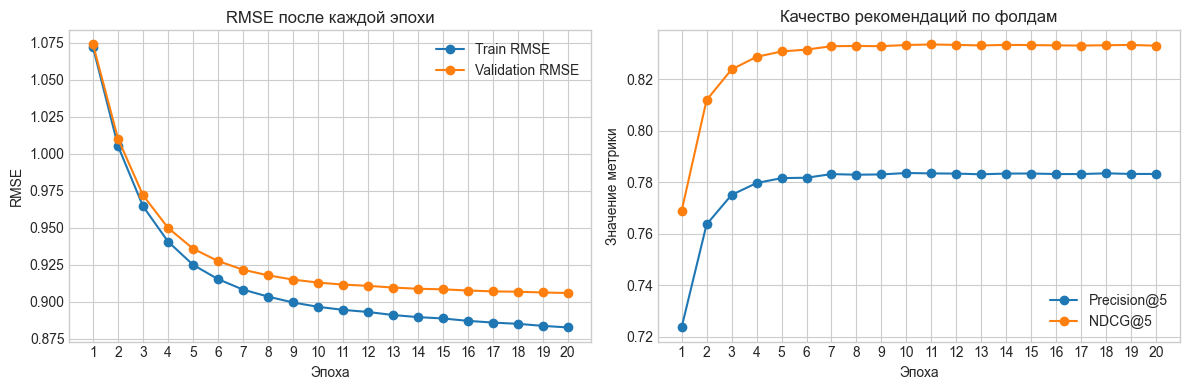

In [23]:
mlp_20_epochs = run_mlp_cv(
    n_epochs=20,
    learning_rate=0.001,
    batch_size=4096,
    embedding_dim=32,
    hidden_dims=(64, 32),
    dropout=0.2,
    weight_decay=0.0,
    use_batch_norm=False,
    seed=42
)

При обучении в течение 20 эпох лучший средний NDCG@5 по пяти фолдам составил **0.8336 на 11-й эпохе**. После этого качество ранжирования колебалось около того же уровня и к 20-й эпохе составило **0.8331**.

При этом RMSE на проверке продолжал снижаться: с **0.9130** на 10-й эпохе до **0.9060** на 20-й. Значит, модель точнее предсказывала сами оценки, но это почти не меняло порядок фильмов в верхней части списка. Поскольку главным критерием выбран NDCG@5, для дальнейшего сравнения ориентируемся примерно на **11 эпох**, а не на минимальный RMSE.

### 8.9 Итог сравнения конфигураций MLP

Все конфигурации сравнивались на одних и тех же пяти фолдах. Для каждой взята эпоха с наибольшим средним NDCG@5; остальные метрики показаны на этой же эпохе.

Наибольший сохранённый NDCG@5 равен **0.8339** у вариантов с `dropout=0.4` и с тремя скрытыми слоями `(64, 32, 16)`. У исходной MLP он составляет **0.8336**. Разница всего **0.0003**, поэтому убедительного улучшения ранжирования новые настройки не показали. Вариант без Dropout заметно уступил исходному.

Для дальнейшего сравнения с ALS оставим исходную архитектуру `(64, 32)` и `dropout=0.2`. Более длительное обучение снизило RMSE, но NDCG@5 вышел на плато примерно после 11-й эпохи. Эти результаты относятся к ранжированию среди отложенных оценённых фильмов, а не среди всего каталога.

,Конфигурация,Эпоха,RMSE,Precision@5,NDCG@5
0,"Исходная, 10 эпох",10,0.9130,0.7840,0.8336
1,LR 0.0005,10,0.9359,0.7818,0.8314
2,LR 0.002,7,0.9092,0.7841,0.8337
3,WD 0.00001,10,0.9101,0.7836,0.8334
4,WD 0.0001,10,0.9280,0.7815,0.8314
5,BatchNorm,10,0.9165,0.7827,0.8327
6,Dropout 0,9,0.9193,0.7800,0.8291
7,Dropout 0.4,10,0.9134,0.7839,0.8339
8,"Шире (128, 64)",10,0.9137,0.7835,0.8333
9,Один слой (64),10,0.9127,0.7834,0.8335


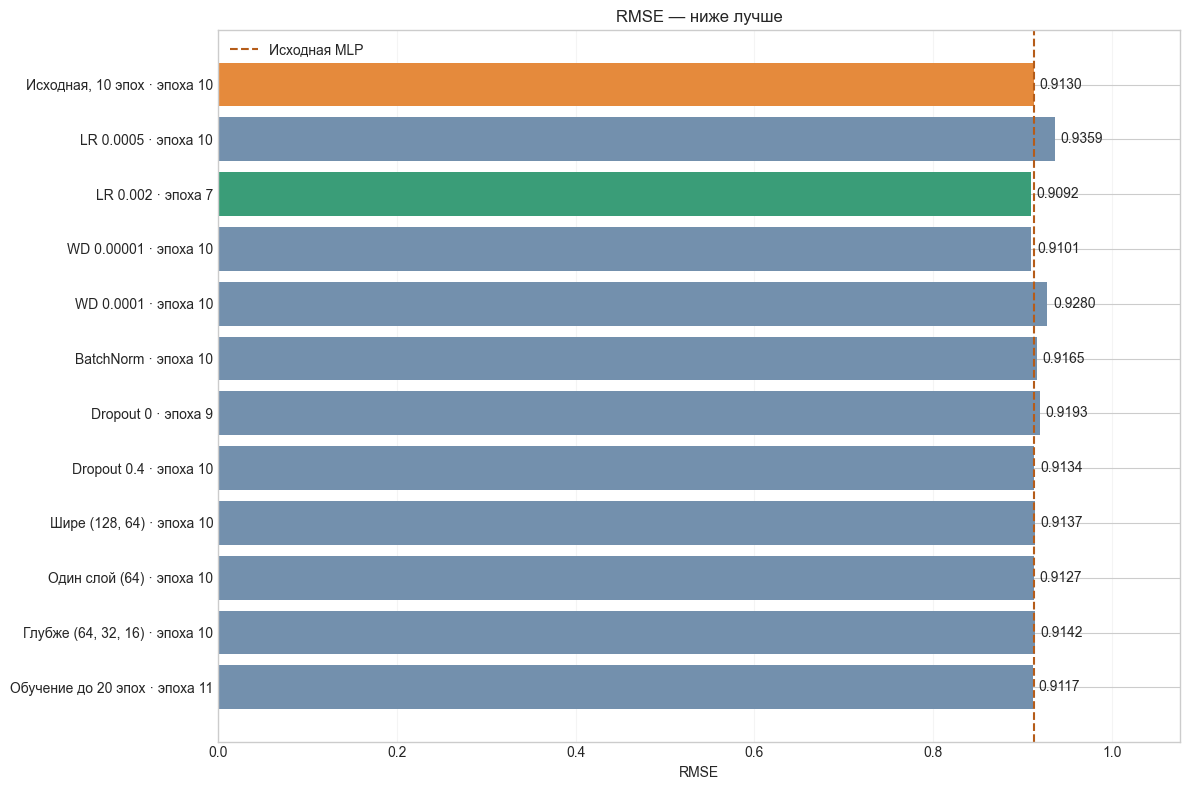

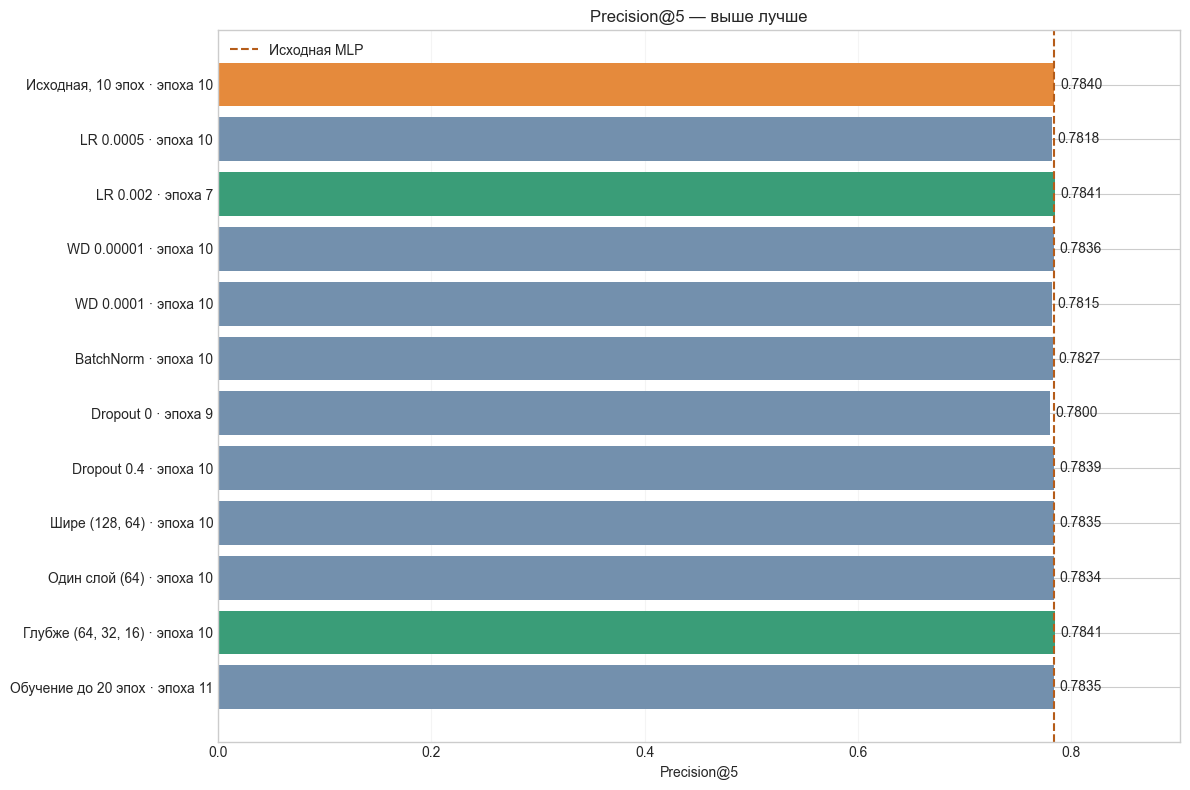

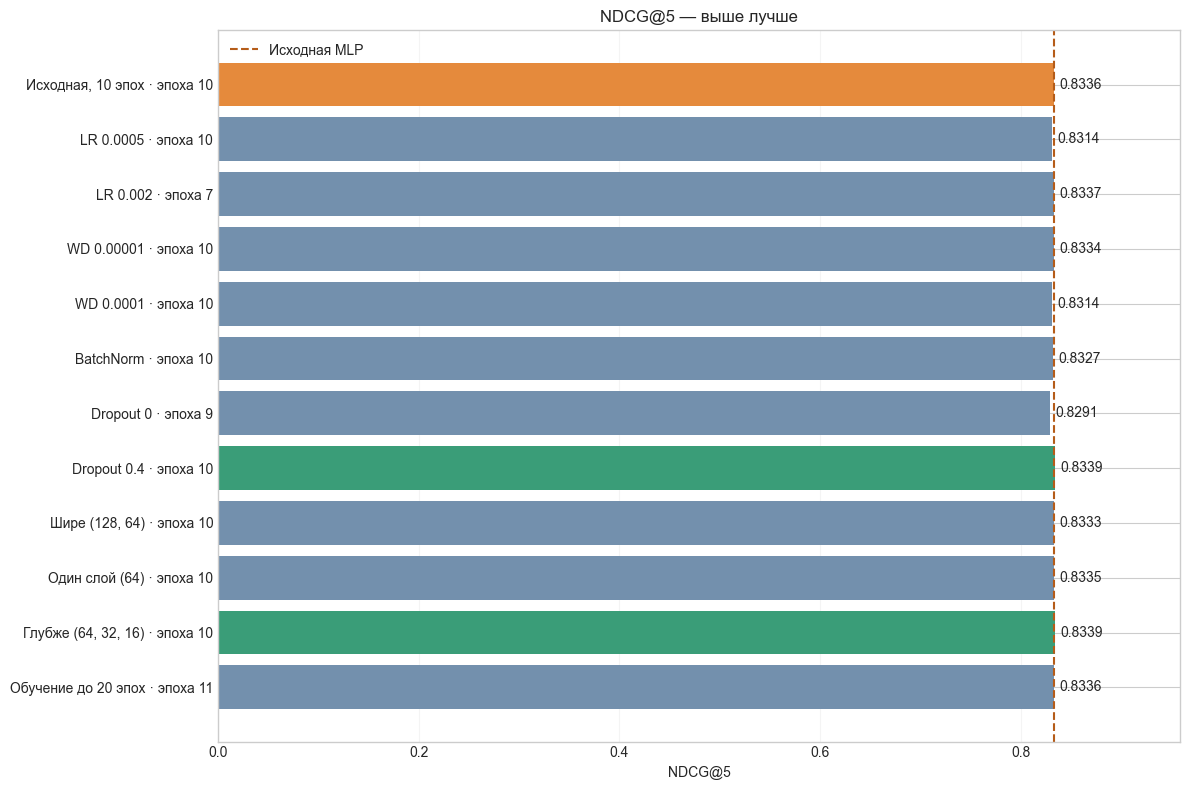

In [27]:
import pandas as pd
import matplotlib.pyplot as plt

# Для каждого варианта берём эпоху с лучшим средним NDCG@5.
# Precision@5 и RMSE взяты на той же эпохе.
runs = [
    ("Исходная, 10 эпох", mlp_run),
    ("LR 0.0005", mlp_lr_results[0.0005]), ("LR 0.002", mlp_lr_results[0.002]),
    ("WD 0.00001", mlp_wd_00001), ("WD 0.0001", mlp_wd_0001),
    ("BatchNorm", mlp_bn), ("Dropout 0", mlp_dropout_0), ("Dropout 0.4", mlp_dropout_04),
    ("Шире (128, 64)", mlp_wider), ("Один слой (64)", mlp_one_layer),
    ("Глубже (64, 32, 16)", mlp_deeper), ("Обучение до 20 эпох", mlp_20_epochs),
]
mlp_rows = []
for name, run in runs:
    epoch = run["best_epoch"]
    row = run["summary"].xs("mean", axis=1, level=1).loc[epoch]
    mlp_rows.append([name, epoch, row["Validation RMSE"], row["Precision@5"], row["NDCG@5"]])
mlp_comparison = pd.DataFrame(mlp_rows, columns=["Конфигурация", "Эпоха", "RMSE", "Precision@5", "NDCG@5"])
display(mlp_comparison.round(4))

baseline = mlp_comparison.iloc[0]

for metric, higher_is_better in [
    ("RMSE", False),
    ("Precision@5", True),
    ("NDCG@5", True),
]:
    values = mlp_comparison[metric]
    best = values.max() if higher_is_better else values.min()

    colors = [
        "#e58a3c" if i == 0 else
        "#3a9d78" if value == best else
        "#7390ad"
        for i, value in enumerate(values)
    ]

    labels = [
        f"{name} · эпоха {epoch}"
        for name, epoch in zip(
            mlp_comparison["Конфигурация"],
            mlp_comparison["Эпоха"],
        )
    ]

    fig, ax = plt.subplots(figsize=(12, 8))
    bars = ax.barh(labels, values, color=colors)
    ax.invert_yaxis()

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in values],
        padding=4,
    )
    ax.axvline(
        baseline[metric],
        color="#b55c19",
        linestyle="--",
        label="Исходная MLP",
    )

    ax.set_xlim(0, values.max() * 1.15)
    ax.set_xlabel(metric)
    ax.set_title(
        f"{metric} — {'выше лучше' if higher_is_better else 'ниже лучше'}"
    )
    ax.grid(axis="x", alpha=0.2)
    ax.set_axisbelow(True)
    ax.legend()

    plt.tight_layout()
    plt.show()

#### Вывод по настройке MLP

Проверенные изменения скорости обучения, BatchNorm, регуляризации и архитектуры не дали заметного улучшения основной метрики NDCG@5. Максимальное значение составило 0.8339 против 0.8336 у исходной MLP; такое небольшое различие не позволяет уверенно выбрать более сложную конфигурацию. Отключение Dropout ухудшило качество ранжирования.

Для итогового сравнения с ALS оставим исходную архитектуру `(64, 32)` с `dropout=0.2`, без BatchNorm и `weight_decay`, при `learning_rate=0.001`. При продлении обучения NDCG@5 достиг максимума примерно на 11-й эпохе и затем вышел на плато. Эти результаты получены на пяти фолдах; итоговый тест пока не использовался.

### 8.10 Сравнение MLP с ALS

Обе модели оценены на одинаковых пяти фолдах. Настроенный ALS получил RMSE **0.8840**, Precision@5 **0.8145** и NDCG@5 **0.8666**. У исходной MLP с dropout=0.2 значения составили **0.9130**, **0.7840** и **0.8336**.

ALS лучше предсказывает оценки и лучше ранжирует отложенные оценённые фильмы. Разница по главной метрике NDCG@5 составляет **0.0330** в пользу ALS. Проверенные изменения архитектуры и настроек MLP не дали заметного улучшения, поэтому в рамках этого протокола ALS остаётся более удачным методом. Итоговый тест пока не использовался.

В §11 на тест переносим вариант с dropout=0.4, который разделил первое место среди MLP по округлённому NDCG@5.

,Модель,RMSE,Precision@5,NDCG@5
0,ALS,0.884,0.8145,0.8666
1,MLP,0.913,0.7840,0.8336


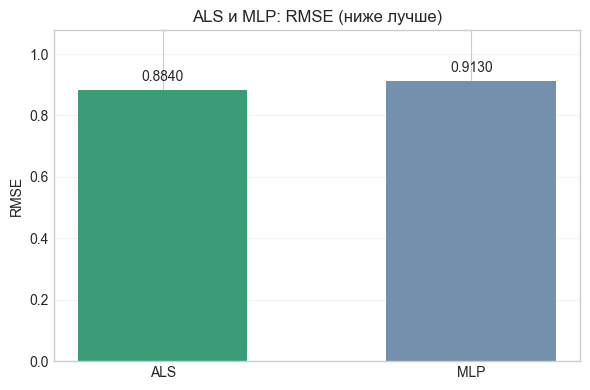

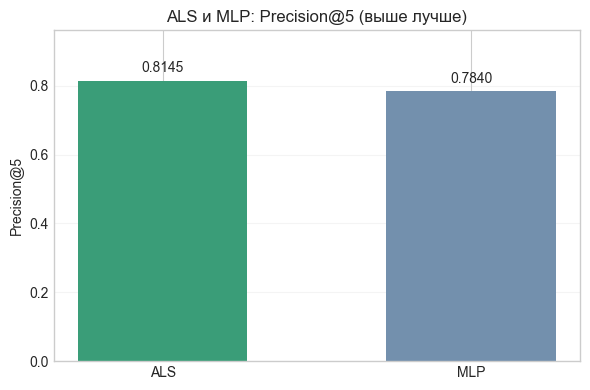

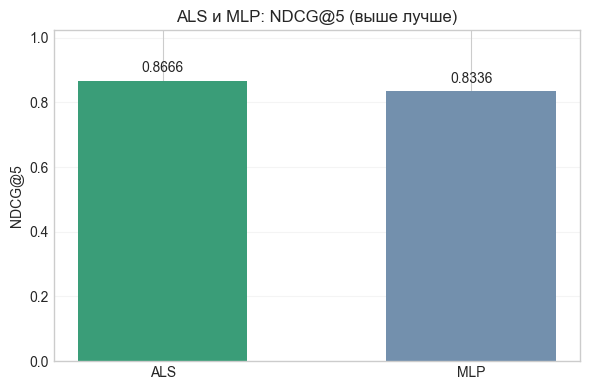

In [28]:
import pandas as pd
import matplotlib.pyplot as plt

als_row = als_grid_summary.xs("mean", axis=1, level=1).loc[(20, 20, 10)]
mlp_row = mlp_run["summary"].xs("mean", axis=1, level=1).loc[10]
model_comparison = pd.DataFrame([
    ["ALS", als_row["RMSE"], als_row["Precision@5"], als_row["NDCG@5"]],
    ["MLP", mlp_row["Validation RMSE"], mlp_row["Precision@5"], mlp_row["NDCG@5"]],
], columns=["Модель", "RMSE", "Precision@5", "NDCG@5"])

display(model_comparison.round(4))

for metric, better in [
    ("RMSE", "ниже лучше"),
    ("Precision@5", "выше лучше"),
    ("NDCG@5", "выше лучше"),
]:
    fig, ax = plt.subplots(figsize=(6, 4))

    bars = ax.bar(
        model_comparison["Модель"],
        model_comparison[metric],
        color=["#3a9d78", "#7390ad"],
        width=0.55,
    )

    ax.bar_label(
        bars,
        labels=[f"{value:.4f}" for value in model_comparison[metric]],
        padding=4,
    )
    ax.set_ylim(0, model_comparison[metric].max() * 1.18)
    ax.set_ylabel(metric)
    ax.set_title(f"ALS и MLP: {metric} ({better})")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

## 9. Двухэтапное ранжирование фильмов

### 9.1 Задача и используемые методы

Проверим, улучшит ли сочетание двух моделей порядок рекомендаций среди отложенных оценённых фильмов. Сохраним тот же протокол пяти фолдов и те же определения Precision@5 и NDCG@5, что использовали для предыдущих методов.

**Первый этап — DSSM (Deep Structured Semantic Model).** Это нейросеть с двумя «башнями»: одна строит вектор пользователя, другая — вектор фильма. По сходству векторов DSSM присваивает каждому отложенному фильму балл и отбирает Top-N кандидатов для дальнейшего ранжирования. Этот балл не является прогнозом оценки от 1 до 5.

**Второй этап — CatBoostClassifier.** Это модель на основе ансамбля деревьев, которая для каждой пары оценивает вероятность оценки 4–5. Она получает кандидатов DSSM, их баллы и дополнительные признаки пары «пользователь — фильм», после чего для каждого пользователя выбираем пять фильмов с наибольшей вероятностью.

Для честного сравнения итоговый Top-5 оценим по тем же настоящим отложенным оценкам, что и раньше: оценки 4–5 считаем положительными. Если DSSM не включил подходящий фильм в Top-N, CatBoost уже не сможет его вернуть. Поэтому при расчёте NDCG@5 идеальный порядок определим по **всем** отложенным оценённым фильмам пользователя, а не только по прошедшим первый этап.

Сначала отдельно оценим DSSM, затем полную систему DSSM + CatBoostClassifier и сравним их с прежними моделями на одинаковых пяти фолдах. Итоговый тест используем после выбора моделей и настроек.

### 9.2 Входные признаки и защита от утечки

**Башня пользователя DSSM** получает ID пользователя и профиль его предпочтений. Профиль строится по фильмам, которым он поставил 4–5: усредняются их жанровые признаки и MPNet-эмбеддинги описаний. **Башня фильма** получает ID фильма, жанры, MPNet-эмбеддинг и признак отсутствия описания. Для фильма без описания используем нулевой текстовый вектор вместе с этим признаком.

CatBoostClassifier получает балл DSSM и признаки пары «пользователь — фильм»: например, сходство жанров фильма с предпочтениями пользователя, сходство описания с его текстовым профилем, год выпуска и популярность фильма. Начнём с небольшого набора признаков, которые уже можно получить из данных проекта.

В каждом фолде историю пользователя, популярность и среднюю оценку фильма рассчитываем **только по обучающим оценкам этого фолда**. Готовые столбцы `user_mean_rating`, `movie_mean_rating` и `movie_rating_count` из раздела 2.4 для обучения здесь не используем: они были рассчитаны до разделения данных. При создании обучающей пары DSSM целевой фильм исключаем из профиля пользователя, чтобы модель не увидела ответ среди входных признаков.

### 9.3 Обучающие пары и функция потерь DSSM

Один обучающий пример — пара «пользователь — фильм» с известной оценкой.
Оценкам 4–5 присваиваем метку 1, оценкам 1–2 — метку 0. Оценку 3 считаем
пограничной и пропускаем при обучении DSSM. Пары без оценки в обучение
не включаем.

Для каждой пары строим профиль пользователя по его положительным оценкам
из обучающей части фолда, исключая целевой фильм. Например, если пользователь
поставил пятёрки фильмам A и B, то для пары с фильмом B профиль строим
по фильму A. Так текст и жанры фильма B не попадут одновременно во вход
башни фильма и в профиль пользователя через его пятёрку.

Обе башни возвращают векторы одинаковой размерности. Их скалярное произведение
даёт балл пары. Обучаем модель с помощью `BCEWithLogitsLoss`, которая принимает
этот балл и метку 0 или 1. При ранжировании сортируем фильмы по убыванию балла
и передаём первые N кандидатов в CatBoostClassifier.

При валидации сохраняем исходный протокол. Среди кандидатов есть все
отложенные оценённые фильмы, включая фильмы с оценкой 3. Для Precision@5
и NDCG@5 релевантными считаем только фильмы с оценками 4–5.

In [35]:
dssm_fold = 0
dssm_fold_train = cv_ratings.loc[cv_ratings["fold"] != dssm_fold]
dssm_fold_valid = cv_ratings.loc[cv_ratings["fold"] == dssm_fold]

dssm_train_pairs = dssm_fold_train.loc[
    dssm_fold_train["rating"] != 3, ["user_id", "movie_id", "rating"]
].copy()
dssm_train_pairs["label"] = (dssm_train_pairs["rating"] >= 4).astype("int8")

# Строки соответствуют content_movie_to_code.
dssm_movie_features = np.concatenate(
    [movie_genres.astype("float32"), movie_mpnet_embeddings], axis=1
)

liked = dssm_train_pairs.loc[dssm_train_pairs["label"] == 1]
dssm_liked_matrix = csr_matrix(
    (
        np.ones(len(liked), dtype="float32"),
        (
            liked["user_id"].map(user_to_code).to_numpy(),
            liked["movie_id"].map(content_movie_to_code).to_numpy(),
        ),
    ),
    shape=(len(user_ids), len(content_movie_ids)),
)

dssm_profile_sums = dssm_liked_matrix @ dssm_movie_features
dssm_profile_counts = np.asarray(dssm_liked_matrix.sum(axis=1)).ravel().astype(int)


def dssm_user_profile(pairs):
    user_codes = pairs["user_id"].map(user_to_code).to_numpy()
    movie_codes = pairs["movie_id"].map(content_movie_to_code).to_numpy()

    # Вычитаем целевой фильм, если он входит в историю лайков.
    in_history = np.asarray(
        dssm_liked_matrix[user_codes, movie_codes]
    ).ravel().astype(bool)

    sums = dssm_profile_sums[user_codes].copy()
    sums[in_history] -= dssm_movie_features[movie_codes[in_history]]
    counts = dssm_profile_counts[user_codes] - in_history

    profiles = np.divide(
        sums,
        counts[:, None],
        out=np.zeros_like(sums),
        where=counts[:, None] > 0,
    )
    return profiles, counts


# Сверяем расчёт с прямым средним на двух примерах каждого класса.
examples = dssm_train_pairs.groupby("label").head(2).copy()
profiles, counts = dssm_user_profile(examples)

for pair, profile, count in zip(examples.itertuples(index=False), profiles, counts):
    history = liked.loc[
        (liked["user_id"] == pair.user_id) & (liked["movie_id"] != pair.movie_id)
    ]
    history_codes = history["movie_id"].map(content_movie_to_code).to_numpy()
    expected = (
        dssm_movie_features[history_codes].mean(axis=0)
        if len(history_codes)
        else np.zeros_like(profile)
    )
    assert count == len(history_codes)
    np.testing.assert_allclose(profile, expected, atol=1e-6)

display(dssm_train_pairs["label"].value_counts().sort_index())
display(examples.assign(profile_movies=counts))
print("Кандидатов на валидации:", len(dssm_fold_valid))

label
0    104332
1    366701
Name: count, dtype: int64

Кандидатов на валидации: 162531


### 9.4 Архитектура DSSM и пробный расчёт

Модель состоит из двух нейросетей — башни пользователя и башни фильма.

Башня пользователя получает обучаемый ID-эмбеддинг размером 32 и профиль
предпочтений, построенный по жанрам и MPNet-векторам понравившихся фильмов.
Башня фильма получает обучаемый ID-эмбеддинг размером 32, жанры,
MPNet-вектор описания и признак отсутствия описания.

В каждой башне входные признаки проходят через скрытый слой из 64 нейронов
с ReLU, затем через выходной слой из 32 нейронов. На выходе получаем
векторы пользователя и фильма одинаковой размерности.

Балл пары вычисляем как скалярное произведение этих векторов:

$$
s_{ui} = \sum_{j=1}^{32} v_{u,j}v_{i,j}.
$$

Для обучения используем `BCEWithLogitsLoss`. Она переводит балл в вероятность
класса 1 через сигмоиду и рассчитывает бинарную кросс-энтропию:

$$
p_{ui} = \frac{1}{1 + e^{-s_{ui}}},
$$

$$
\ell_{ui} = -\left[y_{ui}\ln p_{ui}
+ (1-y_{ui})\ln(1-p_{ui})\right].
$$

Loss батча — средний штраф по всем его парам.

Перед обучением проверяем расчёт на четырёх парах — двух с меткой 1
и двух с меткой 0. При случайных начальных весах получили loss около 0.7024.
Эта проверка подтверждает, что модель выдаёт по одному баллу на пару
и функция потерь рассчитывается.

In [36]:
import torch
from torch import nn


class MovieDSSM(nn.Module):
    def __init__(self, num_users, num_movies, content_dim, id_dim=32, output_dim=32):
        super().__init__()
        self.user_embedding = nn.Embedding(num_users, id_dim)
        self.movie_embedding = nn.Embedding(num_movies, id_dim)

        self.user_tower = nn.Sequential(
            nn.Linear(id_dim + content_dim, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim),
        )
        self.movie_tower = nn.Sequential(
            nn.Linear(id_dim + content_dim + 1, 64),
            nn.ReLU(),
            nn.Linear(64, output_dim),
        )

    def forward(self, user_codes, movie_codes, user_profiles, movie_features):
        user_input = torch.cat(
            [self.user_embedding(user_codes), user_profiles], dim=1
        )
        movie_input = torch.cat(
            [self.movie_embedding(movie_codes), movie_features], dim=1
        )
        user_vectors = self.user_tower(user_input)
        movie_vectors = self.movie_tower(movie_input)

        # Скалярное произведение отдельно для каждой пары в батче.
        return (user_vectors * movie_vectors).sum(dim=1)


dssm_item_features = np.column_stack(
    [dssm_movie_features, (~has_overview).to_numpy(dtype="float32")]
)

torch.manual_seed(42)
dssm_model = MovieDSSM(
    num_users=len(user_ids),
    num_movies=len(content_movie_ids),
    content_dim=dssm_movie_features.shape[1],
)

# Берём две пары с меткой 0 и две с меткой 1.
batch = dssm_train_pairs.groupby("label").head(2).copy()
batch_profiles, _ = dssm_user_profile(batch)
batch_user_codes = batch["user_id"].map(user_to_code).to_numpy()
batch_movie_codes = batch["movie_id"].map(content_movie_to_code).to_numpy()
labels = torch.from_numpy(batch["label"].to_numpy(dtype="float32"))

dssm_loss_fn = nn.BCEWithLogitsLoss()
with torch.no_grad():
    logits = dssm_model(
        torch.as_tensor(batch_user_codes, dtype=torch.long),
        torch.as_tensor(batch_movie_codes, dtype=torch.long),
        torch.from_numpy(batch_profiles),
        torch.from_numpy(dssm_item_features[batch_movie_codes]),
    )
    loss = dssm_loss_fn(logits, labels)

assert logits.shape == labels.shape
assert torch.isfinite(loss).item()

display(batch.assign(dssm_score=logits.numpy().round(4)))
print(f"Loss на пробном батче: {loss.item():.4f}")

Loss на пробном батче: 0.7024


### 9.5 Первый запуск обучения DSSM

Обучим модель на обучающей части первого фолда в течение трёх эпох.
Используем Adam с learning_rate=0.001 и батчи по 1024 пары.
Перед каждой эпохой перемешиваем обучающие примеры.

Для каждого батча строим профили пользователей с исключением целевого
фильма, рассчитываем баллы и BCEWithLogitsLoss. Затем вычисляем градиенты
и обновляем веса обеих башен.

После каждой эпохи выводим средний обучающий loss и время.
Качество ранжирования на валидации проверим следующим шагом.

In [37]:
import time

dssm_device = training_device()
print("Устройство:", dssm_device)

# Каждый повторный запуск этой ячейки начинает обучение заново.
torch.manual_seed(42)
dssm_rng = np.random.default_rng(42)

dssm_model = MovieDSSM(
    num_users=len(user_ids),
    num_movies=len(content_movie_ids),
    content_dim=dssm_movie_features.shape[1],
).to(dssm_device)

dssm_optimizer = torch.optim.Adam(
    dssm_model.parameters(),
    lr=0.001,
)
dssm_loss_fn = nn.BCEWithLogitsLoss()

dssm_epochs = 3
dssm_batch_size = 1024
dssm_history = []

for epoch in range(1, dssm_epochs + 1):
    start_time = time.perf_counter()
    dssm_model.train()
    total_loss = 0.0

    order = dssm_rng.permutation(len(dssm_train_pairs))

    for start in range(0, len(order), dssm_batch_size):
        positions = order[start:start + dssm_batch_size]
        batch = dssm_train_pairs.iloc[positions]

        profiles, _ = dssm_user_profile(batch)
        user_codes = batch["user_id"].map(user_to_code).to_numpy()
        movie_codes = batch["movie_id"].map(content_movie_to_code).to_numpy()

        batch_users = torch.as_tensor(
            user_codes, dtype=torch.long, device=dssm_device
        )
        batch_movies = torch.as_tensor(
            movie_codes, dtype=torch.long, device=dssm_device
        )
        batch_profiles = torch.as_tensor(
            profiles, dtype=torch.float32, device=dssm_device
        )
        batch_features = torch.as_tensor(
            dssm_item_features[movie_codes],
            dtype=torch.float32,
            device=dssm_device,
        )
        batch_labels = torch.as_tensor(
            batch["label"].to_numpy(),
            dtype=torch.float32,
            device=dssm_device,
        )

        dssm_optimizer.zero_grad()
        scores = dssm_model(
            batch_users, batch_movies, batch_profiles, batch_features
        )
        loss = dssm_loss_fn(scores, batch_labels)

        loss.backward()
        dssm_optimizer.step()

        total_loss += loss.item() * len(batch)

    mean_loss = total_loss / len(dssm_train_pairs)
    elapsed = time.perf_counter() - start_time

    dssm_history.append({
        "epoch": epoch,
        "train_loss": mean_loss,
        "seconds": elapsed,
    })
    print(
        f"Эпоха {epoch}/{dssm_epochs} | "
        f"train loss = {mean_loss:.4f} | "
        f"{elapsed:.1f} с",
        flush=True,
    )

dssm_history = pd.DataFrame(dssm_history)

Устройство: mps
Эпоха 1/3 | train loss = 0.4410 | 38.1 с
Эпоха 2/3 | train loss = 0.3654 | 35.1 с
Эпоха 3/3 | train loss = 0.3482 | 35.8 с


### 9.6 Проверка DSSM после трёх эпох

Оценим обученную модель на первом фолде. Рассчитаем Train BCE
и Validation BCE по парам с оценками 1–2 и 4–5.

Для Precision@5 и NDCG@5 используем все отложенные оценённые фильмы,
включая фильмы с оценкой 3. Релевантными считаем оценки 4–5.
В расчёт метрик включаем пользователей минимум с пятью кандидатами.

In [38]:
def evaluate_dssm(pairs):
    dssm_model.eval()
    all_scores = []

    with torch.no_grad():
        for start in range(0, len(pairs), dssm_batch_size):
            batch = pairs.iloc[start:start + dssm_batch_size]
            profiles, _ = dssm_user_profile(batch)

            user_codes = batch["user_id"].map(user_to_code).to_numpy()
            movie_codes = batch["movie_id"].map(content_movie_to_code).to_numpy()

            scores = dssm_model(
                torch.as_tensor(
                    user_codes, dtype=torch.long, device=dssm_device
                ),
                torch.as_tensor(
                    movie_codes, dtype=torch.long, device=dssm_device
                ),
                torch.as_tensor(
                    profiles, dtype=torch.float32, device=dssm_device
                ),
                torch.as_tensor(
                    dssm_item_features[movie_codes],
                    dtype=torch.float32,
                    device=dssm_device,
                ),
            )
            all_scores.append(scores.cpu().numpy())

    scores = np.concatenate(all_scores)

    # BCE считаем только для однозначных оценок.
    mask = pairs["rating"].to_numpy() != 3
    labels = (pairs["rating"].to_numpy()[mask] >= 4).astype("float32")

    bce = dssm_loss_fn(
        torch.from_numpy(scores[mask]),
        torch.from_numpy(labels),
    ).item()

    return scores, bce


# Оба loss считаются с весами модели после третьей эпохи.
_, train_bce = evaluate_dssm(dssm_train_pairs)
valid_scores, valid_bce = evaluate_dssm(dssm_fold_valid)

scored = dssm_fold_valid[["user_id", "movie_id", "rating"]].copy()
scored["score"] = valid_scores

discounts = 1 / np.log2(np.arange(2, 7))
precisions = []
ndcgs = []

for _, group in scored.groupby("user_id"):
    if len(group) < 5:
        continue

    top5 = group.sort_values(
        ["score", "movie_id"],
        ascending=[False, True],
    ).head(5)

    top5_relevant = (top5["rating"] >= 4).to_numpy()
    all_relevant = (group["rating"] >= 4).to_numpy()

    precisions.append(top5_relevant.mean())

    dcg = np.sum(top5_relevant * discounts)
    ideal_top5 = np.sort(all_relevant)[::-1][:5]
    idcg = np.sum(ideal_top5 * discounts)
    ndcgs.append(dcg / idcg if idcg > 0 else 0.0)

dssm_pilot_results = pd.DataFrame([{
    "фолд": dssm_fold + 1,
    "эпоха": dssm_epochs,
    "Train BCE": train_bce,
    "Validation BCE": valid_bce,
    "Precision@5": np.mean(precisions),
    "NDCG@5": np.mean(ndcgs),
}])

display(dssm_pilot_results.round(4))

,фолд,эпоха,Train BCE,Validation BCE,Precision@5,NDCG@5
0,1,3,0.3374,0.35,0.7805,0.8299


После трёх эпох на первом фолде получили Train BCE = 0.3374
и Validation BCE = 0.3500. Ошибка на отложенных парах немного выше
обучающей. Precision@5 составила 0.7805, NDCG@5 — 0.8299.

Это предварительный результат одного фолда. Далее проверим динамику
ошибки и метрик ранжирования по эпохам на всех пяти фолдах.

### 9.7 Кросс-валидация DSSM и динамика обучения

В пробном запуске после трёх эпох на первом фолде получили
Train BCE = 0.3374, Validation BCE = 0.3500,
Precision@5 = 0.7805 и NDCG@5 = 0.8299.

Теперь увеличим длительность обучения до 10 эпох и оценим DSSM
на тех же пяти фолдах, которые использовали для предыдущих моделей.
В каждом фолде заново создаём модель и обучаем её на четырёх частях,
а оставшуюся часть используем для валидации. Профили пользователей
строим только по обучающей истории этого фолда.

Используем две башни с ID-эмбеддингами размером 32, скрытым слоем
из 64 нейронов с ReLU и выходным вектором размером 32.
Сохраняем Adam, learning_rate=0.001 и размер батча 1024.

После каждой эпохи рассчитываем Train BCE и Validation BCE
с текущими весами модели. Дополнительно считаем Precision@5
и NDCG@5 среди всех отложенных оценённых фильмов пользователя.

Выведем результаты каждого фолда и средние значения со стандартными
отклонениями по эпохам. Построим два графика: Train BCE и Validation BCE
слева, Precision@5 и NDCG@5 справа.

По среднему NDCG@5 выберем лучшую эпоху среди проверенных.
Посмотрим, помогает ли более длительное обучение и появляется ли
ухудшение качества на валидации. Итоговый тест используем после
выбора моделей и настроек.

In [39]:
def run_dssm_cv(n_epochs=10, learning_rate=0.001, batch_size=1024, seed=42):
    import time
    from scipy.sparse import csr_matrix
    from torch.utils.data import DataLoader, TensorDataset

    device = training_device()

    print("Устройство:", device)
    print("ID-эмбеддинги: 32")
    print("Скрытый слой каждой башни: 64, ReLU")
    print("Выходной вектор каждой башни: 32")
    print("Learning rate:", learning_rate)
    print("Размер батча:", batch_size)

    # Метаданные фильмов одинаковы для всех фолдов.
    content = np.concatenate(
        [movie_genres.astype("float32"), movie_mpnet_embeddings],
        axis=1,
    )
    item_features = np.column_stack(
        [content, (~has_overview).to_numpy(dtype="float32")]
    )

    content_tensor = torch.as_tensor(content, device=device)
    item_tensor = torch.as_tensor(item_features, device=device)

    rows = []
    models_by_fold = {}

    discounts = 1 / np.log2(np.arange(2, 7))
    ideal_gains = np.r_[0, np.cumsum(discounts)]
    fold_ids = sorted(cv_ratings["fold"].unique())

    for fold_id in fold_ids:
        started = time.perf_counter()
        print(
            f"\nФолд {fold_id + 1} из {len(fold_ids)}",
            flush=True,
        )

        train = cv_ratings.loc[
            (cv_ratings["fold"] != fold_id)
            & (cv_ratings["rating"] != 3)
        ].copy()

        valid = cv_ratings.loc[
            cv_ratings["fold"] == fold_id
        ].copy()

        # История содержит только положительные обучающие оценки.
        liked = train.loc[train["rating"] >= 4]

        liked_matrix = csr_matrix(
            (
                np.ones(len(liked), dtype="float32"),
                (
                    liked["user_id"].map(user_to_code).to_numpy(),
                    liked["movie_id"].map(content_movie_to_code).to_numpy(),
                ),
            ),
            shape=(len(user_ids), len(content_movie_ids)),
        )

        profile_sums = torch.as_tensor(
            liked_matrix @ content,
            device=device,
        )
        profile_counts = torch.as_tensor(
            np.asarray(liked_matrix.sum(axis=1)).ravel(),
            device=device,
        )

        # Храним ID и метки. Профили собираем для каждого батча.
        datasets = []

        for frame, is_train in [(train, True), (valid, False)]:
            labels = (
                frame["rating"].to_numpy() >= 4
            ).astype("float32")

            # -1 означает, что тройку пропускаем при расчёте BCE.
            labels[frame["rating"].to_numpy() == 3] = -1

            # Положительный обучающий фильм входит в историю.
            # Его нужно вычесть при построении профиля этой пары.
            exclude_target = (labels == 1) & is_train

            datasets.append(TensorDataset(
                torch.as_tensor(
                    frame["user_id"].map(user_to_code).to_numpy(),
                    dtype=torch.long,
                ),
                torch.as_tensor(
                    frame["movie_id"].map(content_movie_to_code).to_numpy(),
                    dtype=torch.long,
                ),
                torch.from_numpy(labels),
                torch.from_numpy(exclude_target),
            ))

        generator = torch.Generator().manual_seed(
            seed + int(fold_id)
        )

        train_loader = DataLoader(
            datasets[0],
            batch_size=batch_size,
            shuffle=True,
            generator=generator,
        )
        train_eval_loader = DataLoader(
            datasets[0],
            batch_size=batch_size,
            shuffle=False,
        )
        valid_loader = DataLoader(
            datasets[1],
            batch_size=batch_size,
            shuffle=False,
        )

        # Для каждого фолда создаём новую модель.
        torch.manual_seed(seed + int(fold_id))

        model = MovieDSSM(
            num_users=len(user_ids),
            num_movies=len(content_movie_ids),
            content_dim=content.shape[1],
        ).to(device)

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=learning_rate,
        )
        loss_fn = nn.BCEWithLogitsLoss()

        def predict_batch(batch):
            users, movies, labels, exclude_target = [
                value.to(device) for value in batch
            ]

            exclude = exclude_target.to(torch.float32)

            sums = (
                profile_sums[users]
                - content_tensor[movies] * exclude[:, None]
            )
            counts = profile_counts[users] - exclude

            profiles = sums / counts.clamp_min(1)[:, None]
            profiles = profiles.masked_fill(
                counts[:, None] == 0, 0
            )

            scores = model(
                users,
                movies,
                profiles,
                item_tensor[movies],
            )
            return scores, labels

        def evaluate(loader):
            model.eval()
            all_scores = []

            with torch.no_grad():
                for batch in loader:
                    scores, _ = predict_batch(batch)
                    all_scores.append(scores.cpu())

            scores = torch.cat(all_scores)
            labels = loader.dataset.tensors[2]

            mask = labels >= 0
            bce = loss_fn(
                scores[mask], labels[mask]
            ).item()

            return scores.numpy(), bce

        for epoch in range(1, n_epochs + 1):
            model.train()

            for batch in train_loader:
                optimizer.zero_grad()

                scores, labels = predict_batch(batch)
                loss = loss_fn(scores, labels)

                loss.backward()
                optimizer.step()

            # Обе части оцениваем с весами после завершения эпохи.
            _, train_bce = evaluate(train_eval_loader)
            valid_scores, valid_bce = evaluate(valid_loader)

            scored = valid[
                ["user_id", "movie_id", "rating"]
            ].copy()
            scored["score"] = valid_scores
            scored["relevant"] = (
                scored["rating"] >= 4
            ).astype(int)

            scored = scored.sort_values(
                ["user_id", "score", "movie_id"],
                ascending=[True, False, True],
            )

            # То же ограничение, что и в MLP.
            candidate_counts = (
                scored.groupby("user_id")["movie_id"]
                .transform("size")
            )
            scored = scored.loc[
                candidate_counts >= 5
            ].copy()

            scored["position"] = (
                scored.groupby("user_id").cumcount() + 1
            )
            top5 = scored.loc[
                scored["position"] <= 5
            ].copy()

            precision5 = (
                top5.groupby("user_id")["relevant"]
                .mean()
                .mean()
            )

            top5["gain"] = (
                top5["relevant"]
                / np.log2(top5["position"] + 1)
            )
            dcg = top5.groupby("user_id")["gain"].sum()

            # Идеальный порядок — по всем кандидатам пользователя.
            relevant_counts = (
                scored.groupby("user_id")["relevant"]
                .sum()
                .reindex(dcg.index)
                .clip(upper=5)
                .to_numpy(dtype=int)
            )
            idcg = ideal_gains[relevant_counts]

            ndcg5 = np.divide(
                dcg.to_numpy(),
                idcg,
                out=np.zeros(len(dcg)),
                where=idcg > 0,
            ).mean()

            rows.append({
                "фолд": fold_id + 1,
                "эпоха": epoch,
                "Train BCE": train_bce,
                "Validation BCE": valid_bce,
                "Precision@5": precision5,
                "NDCG@5": ndcg5,
            })

            print(
                f"  Эпоха {epoch}/{n_epochs}: "
                f"Train BCE = {train_bce:.4f}, "
                f"Validation BCE = {valid_bce:.4f}, "
                f"Precision@5 = {precision5:.4f}, "
                f"NDCG@5 = {ndcg5:.4f}",
                flush=True,
            )

        # Здесь сохраняется модель после последней эпохи.
        models_by_fold[fold_id + 1] = model.to("cpu")

        print(
            f"Фолд завершён за "
            f"{time.perf_counter() - started:.1f} секунд"
        )

    results = pd.DataFrame(rows)
    metrics = [
        "Train BCE",
        "Validation BCE",
        "Precision@5",
        "NDCG@5",
    ]

    summary = (
        results.groupby("эпоха")[metrics]
        .agg(["mean", "std"])
    )

    display(results.round(4))
    display(summary.round(4))

    mean_ndcg = summary[("NDCG@5", "mean")]
    best_epoch = mean_ndcg.idxmax()

    print(
        f"Лучшая эпоха по среднему NDCG@5: {best_epoch} "
        f"(NDCG@5 = {mean_ndcg.loc[best_epoch]:.4f})"
    )

    epochs = summary.index
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    for metric in ["Train BCE", "Validation BCE"]:
        axes[0].plot(
            epochs,
            summary[(metric, "mean")],
            marker="o",
            label=metric,
        )

    axes[0].set(
        title="BCE после каждой эпохи",
        xlabel="Эпоха",
        ylabel="BCE",
    )

    for metric in ["Precision@5", "NDCG@5"]:
        axes[1].plot(
            epochs,
            summary[(metric, "mean")],
            marker="o",
            label=metric,
        )

    axes[1].set(
        title="Качество рекомендаций по фолдам",
        xlabel="Эпоха",
        ylabel="Значение метрики",
    )

    for ax in axes:
        ax.set_xticks(epochs)
        ax.legend()
        ax.grid(True)

    plt.tight_layout()
    plt.show()

    return {
        "models_by_fold": models_by_fold,
        "results": results,
        "summary": summary,
        "best_epoch": best_epoch,
        "last_epoch": n_epochs,
        "device": device,
    }

Устройство: mps
ID-эмбеддинги: 32
Скрытый слой каждой башни: 64, ReLU
Выходной вектор каждой башни: 32
Learning rate: 0.001
Размер батча: 1024

Фолд 1 из 5
  Эпоха 1/10: Train BCE = 0.3791, Validation BCE = 0.3848, Precision@5 = 0.7740, NDCG@5 = 0.8244
  Эпоха 2/10: Train BCE = 0.3488, Validation BCE = 0.3594, Precision@5 = 0.7755, NDCG@5 = 0.8232
  Эпоха 3/10: Train BCE = 0.3380, Validation BCE = 0.3513, Precision@5 = 0.7783, NDCG@5 = 0.8272
  Эпоха 4/10: Train BCE = 0.3296, Validation BCE = 0.3447, Precision@5 = 0.7802, NDCG@5 = 0.8299
  Эпоха 5/10: Train BCE = 0.3228, Validation BCE = 0.3399, Precision@5 = 0.7832, NDCG@5 = 0.8332
  Эпоха 6/10: Train BCE = 0.3181, Validation BCE = 0.3376, Precision@5 = 0.7835, NDCG@5 = 0.8324
  Эпоха 7/10: Train BCE = 0.3146, Validation BCE = 0.3363, Precision@5 = 0.7842, NDCG@5 = 0.8353
  Эпоха 8/10: Train BCE = 0.3087, Validation BCE = 0.3338, Precision@5 = 0.7875, NDCG@5 = 0.8362
  Эпоха 9/10: Train BCE = 0.3055, Validation BCE = 0.3330, Precision

,фолд,эпоха,Train BCE,Validation BCE,Precision@5,NDCG@5
0,1,1,0.3791,0.3848,0.7740,0.8244
1,1,2,0.3488,0.3594,0.7755,0.8232
2,1,3,0.3380,0.3513,0.7783,0.8272
3,1,4,0.3296,0.3447,0.7802,0.8299
4,1,5,0.3228,0.3399,0.7832,0.8332
5,1,6,0.3181,0.3376,0.7835,0.8324
6,1,7,0.3146,0.3363,0.7842,0.8353
7,1,8,0.3087,0.3338,0.7875,0.8362
8,1,9,0.3055,0.3330,0.7864,0.8370
9,1,10,0.2991,0.3299,0.7879,0.8373


Train BCE         Validation BCE         Precision@5          NDCG@5  \
           mean     std           mean     std        mean     std    mean   
эпоха                                                                        
1        0.3786  0.0023         0.3857  0.0030      0.7738  0.0023  0.8219   
2        0.3483  0.0009         0.3602  0.0018      0.7759  0.0011  0.8245   
3        0.3368  0.0011         0.3515  0.0013      0.7789  0.0008  0.8268   
4        0.3287  0.0013         0.3458  0.0017      0.7808  0.0017  0.8291   
5        0.3221  0.0010         0.3417  0.0015      0.7820  0.0026  0.8310   
6        0.3168  0.0011         0.3392  0.0019      0.7835  0.0024  0.8324   
7        0.3124  0.0013         0.3374  0.0012      0.7843  0.0032  0.8337   
8        0.3072  0.0011         0.3349  0.0018      0.7874  0.0026  0.8363   
9        0.3027  0.0016         0.3333  0.0019      0.7878  0.0041  0.8366   
10       0.2980  0.0008         0.3314  0.0017      0.7884  0.0037  0.8371   

               
          std  
эпоха          
1      0.0029  
2      0.0010  
3      0.0019  
4      0.0013  
5      0.0025  
6      0.0027  
7      0.0035  
8      0.0028  
9      0.0033  
10     0.0041

Лучшая эпоха по среднему NDCG@5: 10 (NDCG@5 = 0.8371)


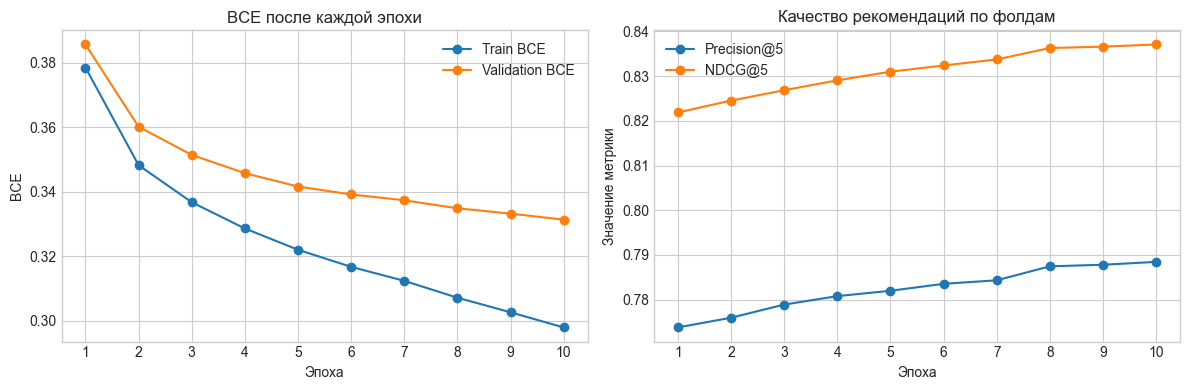

In [40]:
dssm_run = run_dssm_cv(
    n_epochs=10,
    learning_rate=0.001,
    batch_size=1024,
    seed=42,
)

### 9.8 Результаты DSSM и сравнение с MLP

После 10 эпох DSSM получила средние результаты на пяти фолдах:
Train BCE — **0.2980**, Validation BCE — **0.3314**,
Precision@5 — **0.7884**, NDCG@5 — **0.8371**.

Средний NDCG@5 достиг максимума на последней из проверенных эпох.
За 10 эпох Validation BCE снизился с **0.3857** до **0.3314**,
а NDCG@5 вырос с **0.8219** до **0.8371**. При этом разница между
обучающей и проверочной ошибкой увеличилась. К концу запуска качество
на валидации продолжало улучшаться, поэтому пока неизвестно, помогут
ли дополнительные эпохи.

Сравним результаты ранжирования на одинаковых пяти фолдах:

| Метод | Precision@5 ↑ | NDCG@5 ↑ |
|---|---:|---:|
| Исходная MLP, 10 эпох | 0.7840 | 0.8336 |
| MLP с `dropout=0.4`, 10 эпох | 0.7839 | 0.8339 |
| **DSSM, 10 эпох** | **0.7884** | **0.8371** |
| ALS после подбора, 10 итераций | 0.8145 | 0.8666 |

DSSM немного опередила исходную MLP: разница по NDCG@5 составила
**0.0035**. При этом ALS сохранил лучший результат и опередил DSSM
на **0.0295** по NDCG@5.

Архитектуры отличаются и входными данными, и задачей обучения:
MLP предсказывает числовую оценку по ID пользователя и фильма,
а DSSM использует ID, жанры и описания и обучается различать
положительные и отрицательные пары. Поэтому по этому сравнению
нельзя отдельно определить вклад содержания фильмов.

Далее используем DSSM для отбора кандидатов и проверим,
сможет ли CatBoostClassifier улучшить их порядок.

### 9.9 DSSM и CatBoostClassifier на одном фолде

In [41]:
def run_dssm_catboost(outer_fold=0, inner_fold=1, top_n=10, epochs=10):
    from catboost import CatBoostClassifier
    from scipy.sparse import csr_matrix

    seed, batch_size = 42, 1024
    device = training_device()
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    # Нумерация фолдов в cv_ratings начинается с нуля.
    history = cv_ratings.loc[~cv_ratings["fold"].isin([outer_fold, inner_fold])]
    cat_train = cv_ratings.loc[cv_ratings["fold"] == inner_fold]
    valid = cv_ratings.loc[cv_ratings["fold"] == outer_fold]
    train = history.loc[history["rating"] != 3]
    liked = history.loc[history["rating"] >= 4]

    def codes(frame):
        return (
            frame["user_id"].map(user_to_code).to_numpy(),
            frame["movie_id"].map(content_movie_to_code).to_numpy(),
        )

    liked_users, liked_movies = codes(liked)
    content = dssm_movie_features
    liked_matrix = csr_matrix(
        (np.ones(len(liked), dtype="float32"), (liked_users, liked_movies)),
        shape=(len(user_ids), len(content_movie_ids)),
    )
    profile_sums = liked_matrix @ content
    profile_counts = np.asarray(liked_matrix.sum(axis=1)).ravel()
    movie_stats = history.groupby("movie_id")["rating"].agg(["mean", "size"])
    movie_year = movies.set_index("movie_id")["release_year"]
    genre_end = movie_genres.shape[1]

    model = MovieDSSM(len(user_ids), len(content_movie_ids), content.shape[1]).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()

    def forward(batch, training=False):
        users, items = codes(batch)
        sums = profile_sums[users].copy()
        counts = profile_counts[users].copy()

        if training:
            liked_target = batch["rating"].to_numpy() >= 4
            sums[liked_target] -= content[items[liked_target]]
            counts[liked_target] -= 1

        profiles = np.divide(
            sums, counts[:, None], out=np.zeros_like(sums),
            where=counts[:, None] > 0,
        )
        scores = model(
            torch.as_tensor(users, dtype=torch.long, device=device),
            torch.as_tensor(items, dtype=torch.long, device=device),
            torch.as_tensor(profiles, device=device),
            torch.as_tensor(dssm_item_features[items], device=device),
        )
        return scores, profiles, content[items]

    for epoch in range(epochs):
        model.train()
        order = rng.permutation(len(train))
        for start in range(0, len(order), batch_size):
            batch = train.iloc[order[start:start + batch_size]]
            labels = torch.as_tensor(
                (batch["rating"].to_numpy() >= 4).astype("float32"),
                device=device,
            )
            optimizer.zero_grad()
            scores, _, _ = forward(batch, training=True)
            loss_fn(scores, labels).backward()
            optimizer.step()

        print(f"DSSM: эпоха {epoch + 1}/{epochs}", flush=True)

    def cosine(a, b):
        denom = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
        dot = (a * b).sum(axis=1)
        return np.divide(dot, denom, out=np.zeros_like(dot), where=denom > 0)

    @torch.no_grad()
    def shortlist(frame):
        model.eval()
        parts = []
        for start in range(0, len(frame), batch_size):
            batch = frame.iloc[start:start + batch_size]
            scores, profiles, items = forward(batch)
            part = batch[["user_id", "movie_id", "rating"]].copy()
            part["dssm_score"] = scores.cpu().numpy()
            part["genre_cosine"] = cosine(profiles[:, :genre_end], items[:, :genre_end])
            part["text_cosine"] = cosine(profiles[:, genre_end:], items[:, genre_end:])
            parts.append(part)

        scored = pd.concat(parts).sort_values(
            ["user_id", "dssm_score", "movie_id"], ascending=[True, False, True]
        )
        candidates = scored.groupby("user_id", sort=False).head(top_n).copy()
        candidates["movie_mean"] = candidates["movie_id"].map(movie_stats["mean"])
        candidates["movie_count"] = candidates["movie_id"].map(movie_stats["size"]).fillna(0)
        candidates["release_year"] = candidates["movie_id"].map(movie_year)
        return candidates

    fit_candidates = shortlist(cat_train)
    valid_candidates = shortlist(valid)
    features = [
        "dssm_score", "genre_cosine", "text_cosine",
        "movie_mean", "movie_count", "release_year",
    ]

    classifier = CatBoostClassifier(
        iterations=300, depth=6, learning_rate=0.05,
        random_seed=seed, verbose=False, allow_writing_files=False,
    )
    classifier.fit(
        fit_candidates[features],
        (fit_candidates["rating"] >= 4).astype(int),
    )
    valid_candidates["catboost_score"] = classifier.predict_proba(
        valid_candidates[features]
    )[:, 1]

    # Идеальный Top-5 считаем по всей внешней валидации пользователя.
    discounts = 1 / np.log2(np.arange(2, 7))
    relevant = valid["rating"].ge(4).groupby(valid["user_id"])
    ideal = relevant.sum().loc[relevant.size() >= 5].clip(upper=5)
    idcg = pd.Series(
        np.r_[0, discounts.cumsum()][ideal.to_numpy()], index=ideal.index
    )

    results = []
    for name, score in [("DSSM", "dssm_score"), ("DSSM + CatBoost", "catboost_score")]:
        top = valid_candidates.loc[valid_candidates["user_id"].isin(ideal.index)]
        top = top.sort_values(
            ["user_id", score, "movie_id"], ascending=[True, False, True]
        ).groupby("user_id", sort=False).head(5)

        hit = top["rating"].ge(4)
        position = top.groupby("user_id", sort=False).cumcount()
        dcg = (hit * discounts[position.to_numpy()]).groupby(top["user_id"]).sum()
        ndcg = dcg.reindex(idcg.index).div(idcg.where(idcg > 0)).fillna(0).mean()
        results.append({"Метод": name, "Precision@5": hit.mean(), "NDCG@5": ndcg})

    return pd.DataFrame(results), classifier

In [44]:
catboost_pilot, catboost_model = run_dssm_catboost()
display(catboost_pilot.round(4))

DSSM: эпоха 1/10
DSSM: эпоха 2/10
DSSM: эпоха 3/10
DSSM: эпоха 4/10
DSSM: эпоха 5/10
DSSM: эпоха 6/10
DSSM: эпоха 7/10
DSSM: эпоха 8/10
DSSM: эпоха 9/10
DSSM: эпоха 10/10


,Метод,Precision@5,NDCG@5
0,DSSM,0.7800,0.8293
1,DSSM + CatBoost,0.7911,0.8448


В пилотном эксперименте на первом внешнем фолде CatBoostClassifier
улучшил порядок фильмов среди Top-10 кандидатов, отобранных DSSM.
Precision@5 выросла с **0.7800** до **0.7911**, а NDCG@5 — с **0.8293**
до **0.8448**.

Обе версии использовали один и тот же список кандидатов для каждого
пользователя. Прирост получен за счёт изменения порядка этих фильмов.
Далее добавим прогноз ALS как отдельный признак и сравним обе версии
CatBoost на тех же пяти внешних фолдах.

### 9.10 Добавление прогноза ALS в CatBoostClassifier

Проверим, улучшает ли прогноз ALS ранжирование, если добавить его как
отдельный признак в CatBoostClassifier.

В эксперименте используем пять фолдов, сформированных ранее для
кросс-валидации. В этом запуске у них следующие роли:

| Фолды | Роль в эксперименте |
|---|---|
| 3, 4 и 5 | Обучаем DSSM и ALS, строим профили пользователей и рассчитываем статистику фильмов |
| 2 — внутренний фолд | Считаем метрики DSSM по эпохам и обучаем CatBoost на отложенных прогнозах DSSM и ALS |
| 1 — внешний фолд | Оцениваем итоговое качество всей системы |

В таблице нумерация начинается с единицы, а в коде — с нуля.
Поэтому `outer_fold=0` соответствует фолду 1, а `inner_fold=1` —
фолду 2.

1. **Обучаем DSSM** на фолдах 3–5 в течение 10 эпох. После каждой
   эпохи считаем Train BCE на этих трёх фолдах. Inner BCE, Precision@5
   и NDCG@5 считаем на внутреннем фолде 2.
2. **Отбираем кандидатов.** После десятой эпохи DSSM выбирает до 10
   фильмов с наибольшим скором для каждого пользователя. Отбор
   выполняем отдельно на внутреннем фолде 2 и внешнем фолде 1.
3. **Получаем прогноз ALS.** Обучаем ALS на фолдах 3–5 с 20 факторами,
   `reg=20` и 10 итерациями. Для каждого кандидата на фолдах 2 и 1
   сохраняем предсказанную оценку в `als_prediction`.
4. **Обучаем две версии CatBoostClassifier** на кандидатах из
   внутреннего фолда 2. Оценкам 4–5 присваиваем метку 1, остальным
   оценкам — метку 0. Первая версия получает скор DSSM, сходство
   жанров и описаний с профилем пользователя, среднюю оценку фильма,
   число его оценок и год выпуска. Вторая дополнительно получает
   `als_prediction`. Обе версии используют одинаковые настройки
   обучения. Прогнозы DSSM и ALS для этих кандидатов получены на парах,
   оценки которых обе модели впервые встречают на фолде 2.
5. **Оцениваем результат на внешнем фолде 1.** Сортируем один и тот же
   список кандидатов каждого пользователя тремя способами — по скору
   DSSM, по прогнозу CatBoost и по прогнозу CatBoost с признаком ALS.
   Для каждого варианта берём первые пять фильмов и считаем Precision@5
   и NDCG@5. Идеальный порядок для NDCG@5 определяем по всем оценённым
   фильмам пользователя на внешнем фолде.

Вклад ALS оцениваем по разнице Precision@5 и NDCG@5 между двумя
версиями CatBoost на внешнем фолде 1.

In [ ]:
import numpy as np
import pandas as pd
import torch

from catboost import CatBoostClassifier
from scipy.sparse import csr_matrix
from torch import nn


def run_catboost_als_pilot(outer_fold=0, inner_fold=1):
    epochs, batch_size, top_n = 10, 1024, 10
    seed = 42

    device = training_device()
    rng = np.random.default_rng(seed)
    torch.manual_seed(seed)

    history = cv_ratings.loc[~cv_ratings["fold"].isin([outer_fold, inner_fold])]
    inner = cv_ratings.loc[cv_ratings["fold"] == inner_fold]
    outer = cv_ratings.loc[cv_ratings["fold"] == outer_fold]
    dssm_train = history.loc[history["rating"] != 3]
    liked = history.loc[history["rating"] >= 4]

    content = dssm_movie_features
    n_genres = movie_genres.shape[1]

    def codes(frame):
        users = frame["user_id"].map(user_to_code).to_numpy(dtype=int)
        items = frame["movie_id"].map(content_movie_to_code).to_numpy(dtype=int)
        return users, items

    liked_users, liked_items = codes(liked)
    liked_matrix = csr_matrix(
        (np.ones(len(liked), dtype="float32"), (liked_users, liked_items)),
        shape=(len(user_ids), len(content_movie_ids)),
    )
    profile_sums = liked_matrix @ content
    profile_counts = np.asarray(liked_matrix.sum(axis=1)).ravel()

    dssm = MovieDSSM(
        len(user_ids), len(content_movie_ids), content.shape[1]
    ).to(device)
    optimizer = torch.optim.Adam(dssm.parameters(), lr=0.001)
    loss_fn = nn.BCEWithLogitsLoss()

    def score_batch(batch, training=False):
        users, items = codes(batch)
        sums = profile_sums[users].copy()
        counts = profile_counts[users].copy()

        if training:
            # Убираем целевой фильм из профиля положительной пары.
            mask = batch["rating"].ge(4).to_numpy()
            sums[mask] -= content[items[mask]]
            counts[mask] -= 1

        profiles = np.divide(
            sums, counts[:, None],
            out=np.zeros_like(sums), where=counts[:, None] > 0,
        )
        scores = dssm(
            torch.as_tensor(users, dtype=torch.long, device=device),
            torch.as_tensor(items, dtype=torch.long, device=device),
            torch.as_tensor(profiles, device=device),
            torch.as_tensor(dssm_item_features[items], device=device),
        )
        return scores, profiles, content[items]

    def ranking_metrics(frame, score_column, all_candidates):
        discounts = 1 / np.log2(np.arange(2, 7))

        relevant = all_candidates["rating"].ge(4).groupby(all_candidates["user_id"])
        ideal = relevant.sum().loc[relevant.size() >= 5].clip(upper=5)
        idcg = pd.Series(
            np.r_[0, discounts.cumsum()][ideal.to_numpy()],
            index=ideal.index,
        )

        top5 = (
            frame.loc[frame["user_id"].isin(idcg.index)]
            .sort_values(
                ["user_id", score_column, "movie_id"],
                ascending=[True, False, True],
            )
            .groupby("user_id", sort=False)
            .head(5)
        )

        hits = top5["rating"].ge(4)
        positions = top5.groupby("user_id", sort=False).cumcount()
        dcg = (hits * discounts[positions.to_numpy()]).groupby(top5["user_id"]).sum()
        ndcg = dcg.reindex(idcg.index).div(idcg.where(idcg > 0)).fillna(0)

        return {"Precision@5": hits.mean(), "NDCG@5": ndcg.mean()}

    @torch.no_grad()
    def monitor_dssm(frame, training=False):
        dssm.eval()
        parts = []
        for start in range(0, len(frame), batch_size):
            batch = frame.iloc[start:start + batch_size]
            scores, _, _ = score_batch(batch, training=training)
            parts.append(scores.cpu())

        scores = torch.cat(parts)
        ratings = frame["rating"].to_numpy()
        mask = ratings != 3
        labels = torch.from_numpy((ratings[mask] >= 4).astype("float32"))
        return loss_fn(scores[mask], labels).item(), scores.numpy()

    print(f"Устройство: {device} | Батч: {batch_size} | Learning rate: 0.001")
    print(f"Внешний фолд {outer_fold + 1} | Внутренняя часть {inner_fold + 1}")

    for epoch in range(1, epochs + 1):
        dssm.train()
        order = rng.permutation(len(dssm_train))

        for start in range(0, len(order), batch_size):
            batch = dssm_train.iloc[order[start:start + batch_size]]
            labels = torch.as_tensor(
                batch["rating"].ge(4).to_numpy(dtype="float32"),
                device=device,
            )
            optimizer.zero_grad()
            scores, _, _ = score_batch(batch, training=True)
            loss_fn(scores, labels).backward()
            optimizer.step()

        train_bce, _ = monitor_dssm(dssm_train, training=True)
        inner_bce, inner_scores = monitor_dssm(inner)
        inner_metrics = ranking_metrics(
            inner.assign(dssm_score=inner_scores), "dssm_score", inner
        )
        print(
            f"  Эпоха {epoch}/{epochs}: "
            f"Train BCE = {train_bce:.4f}, Inner BCE = {inner_bce:.4f}, "
            f"Precision@5 = {inner_metrics['Precision@5']:.4f}, "
            f"NDCG@5 = {inner_metrics['NDCG@5']:.4f}",
            flush=True,
        )

    movie_stats = history.groupby("movie_id")["rating"].agg(["mean", "size"])
    movie_year = movies.set_index("movie_id")["release_year"]

    def cosine(a, b):
        denominator = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
        dot = (a * b).sum(axis=1)
        return np.divide(dot, denominator, out=np.zeros_like(dot), where=denominator > 0)

    @torch.no_grad()
    def shortlist(frame):
        dssm.eval()
        parts = []

        for start in range(0, len(frame), batch_size):
            batch = frame.iloc[start:start + batch_size]
            scores, profiles, items = score_batch(batch)
            part = batch[["user_id", "movie_id", "rating"]].copy()

            part["dssm_score"] = scores.cpu().numpy()
            part["genre_cosine"] = cosine(profiles[:, :n_genres], items[:, :n_genres])
            part["text_cosine"] = cosine(profiles[:, n_genres:], items[:, n_genres:])
            parts.append(part)

        candidates = (
            pd.concat(parts)
            .sort_values(
                ["user_id", "dssm_score", "movie_id"],
                ascending=[True, False, True],
            )
            .groupby("user_id", sort=False)
            .head(top_n)
            .copy()
        )

        candidates["movie_mean"] = candidates["movie_id"].map(movie_stats["mean"])
        candidates["movie_count"] = candidates["movie_id"].map(movie_stats["size"]).fillna(0)
        candidates["release_year"] = candidates["movie_id"].map(movie_year)
        return candidates

    fit_candidates = shortlist(inner)
    valid_candidates = shortlist(outer)

    print("Обучаем ALS: 20 факторов, reg=20, 10 итераций", flush=True)
    als_mean, als_users, als_movies = fit_als(
        history, n_factors=20, n_iterations=10, reg=20, seed=seed
    )

    for candidates in (fit_candidates, valid_candidates):
        users = candidates["user_id"].map(user_to_code).to_numpy(dtype=int)
        items = candidates["movie_id"].map(movie_to_code).to_numpy(dtype=int)
        predictions = als_mean + np.sum(als_users[users] * als_movies[items], axis=1)
        candidates["als_prediction"] = np.clip(predictions, 1, 5)

    base_features = [
        "dssm_score", "genre_cosine", "text_cosine",
        "movie_mean", "movie_count", "release_year",
    ]
    labels = fit_candidates["rating"].ge(4).astype(int)
    models = {}

    for name, features, score_column in [
        ("DSSM + CatBoost", base_features, "catboost_score"),
        (
            "DSSM + CatBoost + признак ALS",
            base_features + ["als_prediction"],
            "catboost_als_score",
        ),
    ]:
        print(f"\nОбучаем {name}", flush=True)
        classifier = CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.05,
            random_seed=seed, verbose=100, allow_writing_files=False,
        )
        classifier.fit(fit_candidates[features], labels)
        valid_candidates[score_column] = classifier.predict_proba(
            valid_candidates[features]
        )[:, 1]
        models[name] = classifier

    rows = []
    for name, score_column in [
        ("DSSM", "dssm_score"),
        ("DSSM + CatBoost", "catboost_score"),
        ("DSSM + CatBoost + признак ALS", "catboost_als_score"),
    ]:
        rows.append({
            "Метод": name,
            **ranking_metrics(valid_candidates, score_column, outer),
        })

    return pd.DataFrame(rows), models["DSSM + CatBoost + признак ALS"]

In [ ]:
catboost_als_pilot, catboost_als_model = run_catboost_als_pilot()
display(catboost_als_pilot.round(4))

comparison = catboost_als_pilot.set_index("Метод")
delta = (
    comparison.loc["DSSM + CatBoost + признак ALS"]
    - comparison.loc["DSSM + CatBoost"]
)
print(f"Изменение Precision@5 после добавления ALS: {delta['Precision@5']:+.4f}")
print(f"Изменение NDCG@5 после добавления ALS:      {delta['NDCG@5']:+.4f}")

На первом внешнем фолде CatBoost улучшил NDCG@5 с **0.8280**
до **0.8447**. Добавление прогноза ALS дало ещё **0.0168**,
повысив NDCG@5 до **0.8615**. Precision@5 при этом выросла
с **0.7920** до **0.8058** по сравнению с CatBoost без ALS.

Все три варианта ранжировали один и тот же список кандидатов,
отобранных DSSM. Добавление прогноза ALS помогло CatBoost поднять
релевантные фильмы выше в итоговом списке. Чтобы проверить, насколько
устойчив этот прирост, повторим сравнение на всех пяти внешних фолдах.

| Внешний фолд — проверяем всю связку | Внутренний фолд — обучаем CatBoost | Обучаем DSSM и ALS |
|---:|---:|---|
| **1 — готово** | 2 | 3, 4, 5 |
| 2 | 3 | 1, 4, 5 |
| 3 | 4 | 1, 2, 5 |
| 4 | 5 | 1, 2, 3 |
| 5 | 1 | 2, 3, 4 |

Внешний фолд 1/5 — результат уже есть
Устройство: mps | Батч: 1024 | Learning rate: 0.001
Внешний фолд 2 | Внутренняя часть 3
  Эпоха 1/10: Train BCE = 0.3918, Inner BCE = 0.4007, Precision@5 = 0.7655, NDCG@5 = 0.8115
  Эпоха 2/10: Train BCE = 0.3539, Inner BCE = 0.3690, Precision@5 = 0.7712, NDCG@5 = 0.8181
  Эпоха 3/10: Train BCE = 0.3401, Inner BCE = 0.3582, Precision@5 = 0.7718, NDCG@5 = 0.8180
  Эпоха 4/10: Train BCE = 0.3325, Inner BCE = 0.3540, Precision@5 = 0.7743, NDCG@5 = 0.8205
  Эпоха 5/10: Train BCE = 0.3250, Inner BCE = 0.3497, Precision@5 = 0.7759, NDCG@5 = 0.8228
  Эпоха 6/10: Train BCE = 0.3195, Inner BCE = 0.3471, Precision@5 = 0.7785, NDCG@5 = 0.8256
  Эпоха 7/10: Train BCE = 0.3154, Inner BCE = 0.3462, Precision@5 = 0.7797, NDCG@5 = 0.8269
  Эпоха 8/10: Train BCE = 0.3112, Inner BCE = 0.3449, Precision@5 = 0.7816, NDCG@5 = 0.8282
  Эпоха 9/10: Train BCE = 0.3075, Inner BCE = 0.3444, Precision@5 = 0.7830, NDCG@5 = 0.8289
  Эпоха 10/10: Train BCE = 0.3041, Inner BCE =

,Метод,Precision@5,NDCG@5
0,DSSM,0.7826,0.8363
1,DSSM + CatBoost,0.7926,0.8476
2,DSSM + CatBoost + признак ALS,0.8081,0.8647


Устройство: mps | Батч: 1024 | Learning rate: 0.001
Внешний фолд 3 | Внутренняя часть 4
  Эпоха 1/10: Train BCE = 0.3886, Inner BCE = 0.3972, Precision@5 = 0.7704, NDCG@5 = 0.8151
  Эпоха 2/10: Train BCE = 0.3544, Inner BCE = 0.3685, Precision@5 = 0.7771, NDCG@5 = 0.8224
  Эпоха 3/10: Train BCE = 0.3431, Inner BCE = 0.3597, Precision@5 = 0.7787, NDCG@5 = 0.8253
  Эпоха 4/10: Train BCE = 0.3320, Inner BCE = 0.3517, Precision@5 = 0.7803, NDCG@5 = 0.8270
  Эпоха 5/10: Train BCE = 0.3263, Inner BCE = 0.3483, Precision@5 = 0.7806, NDCG@5 = 0.8264
  Эпоха 6/10: Train BCE = 0.3197, Inner BCE = 0.3455, Precision@5 = 0.7846, NDCG@5 = 0.8300
  Эпоха 7/10: Train BCE = 0.3147, Inner BCE = 0.3430, Precision@5 = 0.7831, NDCG@5 = 0.8292
  Эпоха 8/10: Train BCE = 0.3112, Inner BCE = 0.3421, Precision@5 = 0.7855, NDCG@5 = 0.8317
  Эпоха 9/10: Train BCE = 0.3072, Inner BCE = 0.3433, Precision@5 = 0.7846, NDCG@5 = 0.8310
  Эпоха 10/10: Train BCE = 0.3035, Inner BCE = 0.3401, Precision@5 = 0.7860, NDCG@5 

,Метод,Precision@5,NDCG@5
0,DSSM,0.7794,0.8274
1,DSSM + CatBoost,0.7920,0.8424
2,DSSM + CatBoost + признак ALS,0.8067,0.8596


Устройство: mps | Батч: 1024 | Learning rate: 0.001
Внешний фолд 4 | Внутренняя часть 5
  Эпоха 1/10: Train BCE = 0.3960, Inner BCE = 0.4027, Precision@5 = 0.7675, NDCG@5 = 0.8145
  Эпоха 2/10: Train BCE = 0.3565, Inner BCE = 0.3686, Precision@5 = 0.7763, NDCG@5 = 0.8243
  Эпоха 3/10: Train BCE = 0.3416, Inner BCE = 0.3577, Precision@5 = 0.7751, NDCG@5 = 0.8224
  Эпоха 4/10: Train BCE = 0.3312, Inner BCE = 0.3508, Precision@5 = 0.7780, NDCG@5 = 0.8256
  Эпоха 5/10: Train BCE = 0.3257, Inner BCE = 0.3486, Precision@5 = 0.7803, NDCG@5 = 0.8269
  Эпоха 6/10: Train BCE = 0.3191, Inner BCE = 0.3457, Precision@5 = 0.7807, NDCG@5 = 0.8278
  Эпоха 7/10: Train BCE = 0.3144, Inner BCE = 0.3429, Precision@5 = 0.7816, NDCG@5 = 0.8300
  Эпоха 8/10: Train BCE = 0.3104, Inner BCE = 0.3424, Precision@5 = 0.7830, NDCG@5 = 0.8302
  Эпоха 9/10: Train BCE = 0.3047, Inner BCE = 0.3399, Precision@5 = 0.7836, NDCG@5 = 0.8315
  Эпоха 10/10: Train BCE = 0.3003, Inner BCE = 0.3393, Precision@5 = 0.7853, NDCG@5 

,Метод,Precision@5,NDCG@5
0,DSSM,0.7866,0.8331
1,DSSM + CatBoost,0.7985,0.8489
2,DSSM + CatBoost + признак ALS,0.8115,0.8647


... (3 outputs left out)

Precision@5          NDCG@5        
                                     mean     std    mean     std
Метод                                                            
DSSM                               0.7817  0.0032  0.8306  0.0039
DSSM + CatBoost                    0.7935  0.0028  0.8452  0.0030
DSSM + CatBoost + признак ALS      0.8078  0.0022  0.8623  0.0023

,Precision@5,NDCG@5
фолд,,
1,0.0137,0.0168
2,0.0155,0.0171
3,0.0147,0.0172
4,0.0130,0.0158
5,0.0147,0.0183


Средний прирост Precision@5 от ALS: +0.0143
Средний прирост NDCG@5 от ALS:      +0.0171
Фолдов с приростом NDCG@5: 5 из 5


,mean,std
Признак,,
als_prediction,45.61,1.99
dssm_score,16.74,1.39
movie_mean,8.61,0.98
genre_cosine,8.38,0.60
text_cosine,7.31,0.45
movie_count,7.31,0.28
release_year,6.04,0.56


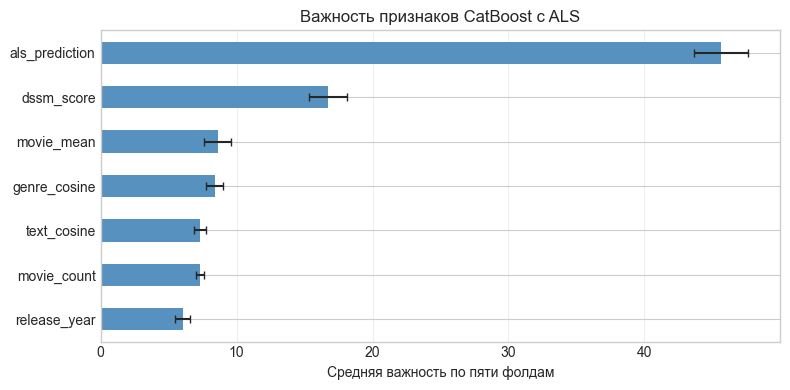

In [51]:
metrics = ["Precision@5", "NDCG@5"]
base_method = "DSSM + CatBoost"
als_method = "DSSM + CatBoost + признак ALS"

# Храним завершённые запуски, чтобы продолжить после прерывания.
if "catboost_cv_runs" not in globals():
    catboost_cv_runs = {}
    if "catboost_als_pilot" in globals() and "catboost_als_model" in globals():
        catboost_cv_runs[0] = (catboost_als_pilot, catboost_als_model)

for outer_fold in range(5):
    inner_fold = (outer_fold + 1) % 5

    if outer_fold in catboost_cv_runs:
        print(f"Внешний фолд {outer_fold + 1}/5 — результат уже есть")
        continue

    catboost_cv_runs[outer_fold] = run_catboost_als_pilot(
        outer_fold=outer_fold,
        inner_fold=inner_fold,
    )

    fold_results, _ = catboost_cv_runs[outer_fold]
    display(fold_results.round(4))

# Результаты и важность признаков по внешним фолдам.
fold_tables = []
importance_tables = []

for outer_fold in range(5):
    fold_results, model = catboost_cv_runs[outer_fold]
    fold_tables.append(fold_results.assign(фолд=outer_fold + 1))
    importance_tables.append(pd.DataFrame({
        "фолд": outer_fold + 1,
        "Признак": model.feature_names_,
        "Важность": model.feature_importances_,
    }))

catboost_cv_results = pd.concat(fold_tables, ignore_index=True)
display(catboost_cv_results[["фолд", "Метод", *metrics]].round(4))

catboost_cv_summary = (
    catboost_cv_results
    .groupby("Метод", sort=False)[metrics]
    .agg(["mean", "std"])
)
display(catboost_cv_summary.round(4))

# Сравниваем две версии CatBoost внутри каждого внешнего фолда.
by_fold = catboost_cv_results.set_index(["Метод", "фолд"])[metrics]
als_gain = by_fold.loc[als_method] - by_fold.loc[base_method]
display(als_gain.round(4))

print(f"Средний прирост Precision@5 от ALS: {als_gain['Precision@5'].mean():+.4f}")
print(f"Средний прирост NDCG@5 от ALS:      {als_gain['NDCG@5'].mean():+.4f}")
print(f"Фолдов с приростом NDCG@5: {(als_gain['NDCG@5'] > 0).sum()} из 5")

catboost_feature_importance = (
    pd.concat(importance_tables, ignore_index=True)
    .groupby("Признак")["Важность"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
display(catboost_feature_importance.round(2))

plot_data = catboost_feature_importance.sort_values("mean")
ax = plot_data["mean"].plot.barh(
    xerr=plot_data["std"],
    figsize=(8, 4),
    color="#5791bf",
    capsize=3,
)
ax.set_xlabel("Средняя важность по пяти фолдам")
ax.set_ylabel("")
ax.set_title("Важность признаков CatBoost с ALS")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 9.11 Итоги кросс-валидации и финальный эксперимент с ALS

По пяти внешним фолдам средний NDCG@5 вырос с **0.8306** у DSSM
до **0.8452** после пересортировки кандидатов с помощью CatBoost.
Добавление прогноза ALS повысило NDCG@5 до **0.8623**.
Прирост относительно CatBoost без ALS составил **0.0171**
и наблюдался на всех пяти фолдах.

Прогноз ALS получил наибольшую среднюю важность в CatBoost (**45.61**).
Важность скора DSSM составила **16.74**. Поэтому в финальном
эксперименте проверим ALS на первом этапе и сравним три варианта:
ALS → Top-5, ALS → Top-10 → CatBoost и ALS → Top-30 → CatBoost.

Для каждого внешнего фолда обучаем ALS на трёх фолдах, обучаем
CatBoost на кандидатах внутреннего фолда и оцениваем все три
варианта на внешнем фолде. В CatBoost используем прогноз ALS,
сходство жанров и описаний, статистику оценок и год выпуска.
Сравниваем Precision@5 и NDCG@5 среди отложенных оценённых фильмов.

## 10. Финальный эксперимент: отбор кандидатов с ALS и ранжирование с CatBoost

В предыдущем эксперименте прогноз ALS оказался самым важным
признаком CatBoost. Теперь используем ALS для отбора кандидатов
и проверим, сможет ли CatBoost улучшить их порядок.

Сравним три варианта:

1. **ALS → Top-5.** Берём пять фильмов с наибольшим прогнозом ALS.
2. **ALS → Top-10 → CatBoost.** CatBoost пересортировывает до 10
   кандидатов ALS, после чего берём первые пять фильмов.
3. **ALS → Top-30 → CatBoost.** Проверяем, помогает ли CatBoost
   более широкий список кандидатов.

На каждом из пяти внешних фолдов все три варианта используют одну
и ту же модель ALS. Обучаем её на трёх фолдах, обучаем CatBoost
на внутреннем фолде и сравниваем результаты на внешнем.
Основная метрика — **NDCG@5**, дополнительная — **Precision@5**.
Считаем обе метрики среди отложенных оценённых фильмов.

In [52]:
from catboost import CatBoostClassifier
from scipy.sparse import csr_matrix


def run_als_catboost_final():
    fold_ids = sorted(cv_ratings["fold"].unique())
    metrics = ["Precision@5", "NDCG@5"]
    features = [
        "als_prediction", "genre_cosine", "text_cosine",
        "movie_mean", "movie_count", "release_year",
    ]

    content = np.column_stack([
        movie_genres.astype("float32"), movie_mpnet_embeddings
    ])
    n_genres = movie_genres.shape[1]
    years = movies.set_index("movie_id")["release_year"]
    discounts = 1 / np.log2(np.arange(2, 7))
    ideal_gains = np.r_[0, discounts.cumsum()]
    rows = []

    def cosine(a, b):
        dot = (a * b).sum(axis=1)
        norm = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
        return np.divide(dot, norm, out=np.zeros_like(dot), where=norm > 0)

    def evaluate(frame, score, idcg):
        top = (
            frame.loc[frame["user_id"].isin(idcg.index)]
            .sort_values(
                ["user_id", score, "movie_id"], ascending=[True, False, True]
            )
            .groupby("user_id", sort=False).head(5)
        )
        hits = top["rating"].ge(4)
        positions = top.groupby("user_id", sort=False).cumcount().to_numpy()
        dcg = (hits * discounts[positions]).groupby(top["user_id"]).sum()
        ndcg = dcg.reindex(idcg.index).div(idcg.where(idcg > 0)).fillna(0)
        return {"Precision@5": hits.mean(), "NDCG@5": ndcg.mean()}

    for position, outer_fold in enumerate(fold_ids):
        inner_fold = fold_ids[(position + 1) % len(fold_ids)]
        print(
            f"Внешний фолд {outer_fold + 1} | Внутренний фолд {inner_fold + 1}",
            flush=True,
        )

        history = cv_ratings.loc[~cv_ratings["fold"].isin([outer_fold, inner_fold])]
        inner = cv_ratings.loc[cv_ratings["fold"].eq(inner_fold)]
        outer = cv_ratings.loc[cv_ratings["fold"].eq(outer_fold)]

        mu, user_factors, item_factors = fit_als(
            history, n_factors=20, n_iterations=10, reg=20, seed=42,
        )

        liked = history.loc[history["rating"].ge(4)]
        likes = csr_matrix(
            (
                np.ones(len(liked), dtype="float32"),
                (
                    liked["user_id"].map(user_to_code).to_numpy(dtype=int),
                    liked["movie_id"].map(content_movie_to_code).to_numpy(dtype=int),
                ),
            ),
            shape=(len(user_ids), len(content_movie_ids)),
        )
        counts = np.asarray(likes.sum(axis=1)).ravel()
        profiles = (likes @ content) / np.maximum(counts[:, None], 1)
        movie_stats = history.groupby("movie_id")["rating"].agg(["mean", "size"])

        def candidates(frame):
            result = frame[["user_id", "movie_id", "rating"]].copy()
            users = frame["user_id"].map(user_to_code).to_numpy(dtype=int)
            items = frame["movie_id"].map(movie_to_code).to_numpy(dtype=int)
            result["als_prediction"] = np.clip(
                mu + (user_factors[users] * item_factors[items]).sum(axis=1),
                1, 5,
            )

            result = (
                result.sort_values(
                    ["user_id", "als_prediction", "movie_id"],
                    ascending=[True, False, True],
                )
                .groupby("user_id", sort=False).head(30)
                .copy()
            )
            result["als_rank"] = result.groupby("user_id", sort=False).cumcount() + 1

            users = result["user_id"].map(user_to_code).to_numpy(dtype=int)
            items = result["movie_id"].map(content_movie_to_code).to_numpy(dtype=int)
            genre_cosine = []
            text_cosine = []

            for start in range(0, len(result), 4096):
                batch = slice(start, start + 4096)
                user_vectors = profiles[users[batch]]
                item_vectors = content[items[batch]]
                genre_cosine.append(
                    cosine(user_vectors[:, :n_genres], item_vectors[:, :n_genres])
                )
                text_cosine.append(
                    cosine(user_vectors[:, n_genres:], item_vectors[:, n_genres:])
                )

            result["genre_cosine"] = np.concatenate(genre_cosine)
            result["text_cosine"] = np.concatenate(text_cosine)
            result["movie_mean"] = result["movie_id"].map(movie_stats["mean"])
            result["movie_count"] = result["movie_id"].map(movie_stats["size"]).fillna(0)
            result["release_year"] = result["movie_id"].map(years)
            return result

        train_candidates = candidates(inner)
        valid_candidates = candidates(outer)

        # Идеальный Top-5 считаем по всем оценённым фильмам внешнего фолда.
        relevant = outer["rating"].ge(4).groupby(outer["user_id"])
        ideal = relevant.sum().loc[relevant.size().ge(5)].clip(upper=5)
        idcg = pd.Series(
            ideal_gains[ideal.to_numpy(dtype=int)], index=ideal.index
        )

        fold_rows = [{
            "фолд": outer_fold + 1,
            "Метод": "ALS → Top-5",
            **evaluate(valid_candidates, "als_prediction", idcg),
        }]

        for k in (10, 30):
            fit = train_candidates.loc[train_candidates["als_rank"].le(k)]
            valid = valid_candidates.loc[valid_candidates["als_rank"].le(k)].copy()

            model = CatBoostClassifier(
                iterations=300, depth=6, learning_rate=0.05,
                random_seed=42, verbose=False, allow_writing_files=False,
            )
            model.fit(fit[features], fit["rating"].ge(4).astype(int))
            valid["catboost_score"] = model.predict_proba(valid[features])[:, 1]

            fold_rows.append({
                "фолд": outer_fold + 1,
                "Метод": f"ALS → Top-{k} → CatBoost",
                **evaluate(valid, "catboost_score", idcg),
            })

        rows.extend(fold_rows)
        display(pd.DataFrame(fold_rows).round(4))

    results = pd.DataFrame(rows)
    display(
        results.groupby("Метод", sort=False)[metrics].agg(["mean", "std"]).round(4)
    )

    by_fold = results.pivot(index="фолд", columns="Метод", values="NDCG@5")
    gains = by_fold.drop(columns="ALS → Top-5").sub(by_fold["ALS → Top-5"], axis=0)
    print("Прирост NDCG@5 относительно ALS на каждом фолде")
    display(gains.round(4))
    return results


als_final_cv = run_als_catboost_final()

Внешний фолд 1 | Внутренний фолд 2


,фолд,Метод,Precision@5,NDCG@5
0,1,ALS → Top-5,0.8056,0.8575
1,1,ALS → Top-10 → CatBoost,0.8106,0.8645
2,1,ALS → Top-30 → CatBoost,0.8117,0.8653


Внешний фолд 2 | Внутренний фолд 3


,фолд,Метод,Precision@5,NDCG@5
0,2,ALS → Top-5,0.8079,0.8606
1,2,ALS → Top-10 → CatBoost,0.8102,0.8660
2,2,ALS → Top-30 → CatBoost,0.8105,0.8664


Внешний фолд 3 | Внутренний фолд 4


,фолд,Метод,Precision@5,NDCG@5
0,3,ALS → Top-5,0.8053,0.8559
1,3,ALS → Top-10 → CatBoost,0.8111,0.8634
2,3,ALS → Top-30 → CatBoost,0.8107,0.8619


... (3 outputs left out)

,фолд,Метод,Precision@5,NDCG@5
0,5,ALS → Top-5,0.8080,0.8583
1,5,ALS → Top-10 → CatBoost,0.8124,0.8646
2,5,ALS → Top-30 → CatBoost,0.8130,0.8642


Precision@5          NDCG@5        
                               mean     std    mean     std
Метод                                                      
ALS → Top-5                  0.8071  0.0016  0.8582  0.0018
ALS → Top-10 → CatBoost      0.8117  0.0017  0.8648  0.0010
ALS → Top-30 → CatBoost      0.8119  0.0013  0.8645  0.0017

Прирост NDCG@5 относительно ALS на каждом фолде


Метод,ALS → Top-10 → CatBoost,ALS → Top-30 → CatBoost
фолд,,
1,0.0070,0.0079
2,0.0054,0.0058
3,0.0076,0.0061
4,0.0066,0.0058
5,0.0062,0.0059


### 10.1 Результаты финального эксперимента

На пяти внешних фолдах CatBoost улучшил ранжирование кандидатов ALS
при обоих размерах списка. Вариант с Top-10 повысил средний NDCG@5
с **0.8582** до **0.8648**. Средний прирост составил **0.0066**,
и метрика выросла на каждом из пяти фолдов. Все три варианта использовали
одну и ту же ALS, обученную на трёх фолдах.

При расширении списка до Top-30 средняя Precision@5 оказалась немного
выше (**0.8119** против **0.8117**), а NDCG@5 — немного ниже
(**0.8645** против **0.8648**). Разница между вариантами мала.
По основной метрике выбираем Top-10 как лучший из двух проверенных
вариантов пересортировки.

По сравнению с предыдущей двухэтапной схемой, где кандидатов отбирала
DSSM, средний NDCG@5 вырос с **0.8623** до **0.8648**. Лучший результат
среди всех экспериментов сохранил самостоятельный ALS — **0.8666**.
Он обучался на четырёх фолдах, а в двухэтапной схеме один из этих фолдов
выделялся для обучения CatBoost.

Пересортировка с CatBoost улучшила рекомендации при общей истории
обучения ALS. Среди проверенных схем лучший средний NDCG@5 на
отложенных оценённых фильмах показал самостоятельный ALS.

## 11. Итоговое сравнение рекомендательных моделей

Сравним лучшие проверенные конфигурации каждого метода по кросс-валидации и на отложенной выборке `test_ratings`. Основная метрика — NDCG@5 среди отложенных оценённых фильмов. Дополнительно считаем Precision@5 и RMSE для методов, предсказывающих числовую оценку.

### 11.1 Лучшие результаты кросс-валидации

Результаты усреднены по пяти внешним фолдам для каждой указанной конфигурации. Главный критерий выбора — NDCG@5. Для MLP две конфигурации достигли одинакового максимума по округлённому NDCG@5. В итоговую проверку включили вариант с `dropout=0.4`.

| Метод | Конфигурация | RMSE ↓ | Precision@5 ↑ | NDCG@5 ↑ | Комментарий |
|---|---|---:|---:|---:|---|
| ALS | §6.3 · 20 факторов, reg=20, 10 итераций | 0.8840 | 0.8145 | 0.8666 | Лидер по обеим метрикам ранжирования на CV. |
| ALS → Top-10 → CatBoost | §10 · до 10 кандидатов | — | 0.8117 | 0.8648 | Лучший NDCG@5 среди двухэтапных схем. |
| ALS → Top-30 → CatBoost | §10 · до 30 кандидатов | — | 0.8119 | 0.8645 | Лучшая Precision@5 среди вариантов §10. |
| SGD | §6.2 · 20 факторов, 20 эпох, lr=0.01, reg=0.05 | 0.8698 | 0.8110 | 0.8627 | Второй среди самостоятельных моделей по NDCG@5. |
| DSSM + CatBoost + признак ALS | §9.10 · до 10 кандидатов DSSM | — | 0.8078 | 0.8623 | Прогноз ALS добавил 0.0171 к среднему NDCG@5. |
| ALS (история для CatBoost) | §10 · ALS на общей с CatBoost истории | — | 0.8071 | 0.8582 | База для измерения эффекта пересортировки. |
| User-based, k=50 | §4 · 50 соседей | 0.9089 | 0.7980 | 0.8502 | Лучший из двух методов ближайших соседей. |
| DSSM + CatBoost | §9.9–9.11 · до 10 кандидатов DSSM | — | 0.7935 | 0.8452 | Пересортировка увеличила NDCG@5 с 0.8306 до 0.8452. |
| DSSM | §9.7 · две башни, 10 эпох | — | 0.7884 | 0.8371 | Использует ID, жанры и описания. Опередила MLP по NDCG@5. |
| MLP | §8 · dropout=0.4, 10 эпох | 0.9134 | 0.7839 | 0.8339 | Одна из двух конфигураций MLP с NDCG@5 0.8339. |
| Item-based, k=50 | §5 · 50 соседей | 0.9559 | 0.7829 | 0.8289 | Показал лучший NDCG@5 среди проверенных значений k для Item-based. |
| MPNet + жанры | §7.4 · вес текста 0.7 | — | 0.6778 | 0.7173 | Лучший контентный вариант по NDCG@5. |
| TF-IDF + жанры | §7.3 · вес текста 0.7 | — | 0.6715 | 0.7113 | Добавление описаний повысило NDCG@5 относительно жанрового метода. |
| Жанры | §7.1 · сходство жанров | — | 0.6517 | 0.6835 | Базовый контентный метод. |

In [53]:
cv_metrics = ["RMSE", "Precision@5", "NDCG@5"]
rank_metrics = cv_metrics[1:]
rows = {}
rows["User-based, k=50"] = user_cv_summary.xs("mean", axis=1, level=1).loc[50]
rows["Item-based, k=50"] = item_cv_summary.xs("mean", axis=1, level=1).loc[50]
rows["SGD"] = sgd_full_cv_summary.xs("mean", axis=1, level=1).loc[(20, 20, 0.01, 0.05)]
rows["ALS"] = als_grid_summary.xs("mean", axis=1, level=1).loc[(20, 20, 10)]
for name, folds in [("Жанры", genre_rank_results), ("TF-IDF + жанры", tfidf_rank_results),
                    ("MPNet + жанры", mpnet_rank_results)]:
    rows[name] = folds[rank_metrics].mean()
rows["MLP"] = mlp_dropout_04["summary"].xs("mean", axis=1, level=1).loc[10].rename(
    {"Validation RMSE": "RMSE"})
rows["DSSM"] = dssm_run["summary"].xs("mean", axis=1, level=1).loc[10]
for name in ["DSSM + CatBoost", "DSSM + CatBoost + признак ALS"]:
    rows[name] = catboost_cv_summary.xs("mean", axis=1, level=1).loc[name]
for name, folds in als_final_cv.groupby("Метод", sort=False):
    label = "ALS (история для CatBoost)" if name == "ALS → Top-5" else name
    rows[label] = folds[rank_metrics].mean()
cv_section_11 = pd.DataFrame.from_dict(rows, orient="index")[cv_metrics].rename_axis("Метод").reset_index()

### 11.2 Проверка на отложенной выборке

В `train_ratings` — 800 193 оценки. В `test_ratings` — 200 016 оценок, отложенных до кросс-валидации.

- Самостоятельные методы обучаем на всей выборке `train_ratings`.
- Для двухэтапных схем выделяем первый фолд из `train_ratings` под обучение CatBoost. Модели отбора и статистики признаков получаем по четырём оставшимся фолдам.
- Дополнительно проверяем ALS на той же истории, чтобы измерить эффект CatBoost при одинаковых данных первого этапа.

Релевантными считаем фильмы с оценками 4–5. Метрики ранжирования считаем для пользователей как минимум с пятью отложенными оценками. Идеальный Top-5 для NDCG@5 строим по всем отложенным оценкам пользователя.

In [54]:
import numpy as np
import pandas as pd
import torch
from catboost import CatBoostClassifier
from IPython.display import display
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity
from torch import nn


def run_final_evaluation():
    train, test = train_ratings, test_ratings
    inner = cv_ratings.loc[cv_ratings["fold"].eq(0)]
    history = train.drop(index=inner.index)
    assert train.index.intersection(test.index).empty
    assert inner.index.difference(train.index).empty

    seed = 42
    device = training_device()
    content = np.column_stack([movie_genres.astype("float32"), movie_mpnet_embeddings])
    item_content = np.column_stack([content, (~has_overview).to_numpy(dtype="float32")])
    n_genres = movie_genres.shape[1]
    years = movies.set_index("movie_id")["release_year"]
    actual = test["rating"].to_numpy()
    discounts = 1 / np.log2(np.arange(2, 7))
    relevant = test["rating"].ge(4).groupby(test["user_id"])
    ideal = relevant.sum().loc[relevant.size().ge(5)].clip(upper=5)
    idcg = pd.Series(np.r_[0, discounts.cumsum()][ideal.to_numpy(dtype=int)], index=ideal.index)
    rows = []

    def codes(frame, item_index):
        return (
            frame["user_id"].map(user_to_code).to_numpy(dtype=int),
            frame["movie_id"].map(item_index).to_numpy(dtype=int),
        )

    def sparse_ratings(frame, item_index, size, values):
        return csr_matrix((values, codes(frame, item_index)), shape=(len(user_ids), size))

    def ordered(frame, score):
        return frame.sort_values(["user_id", score, "movie_id"], ascending=[True, False, True])

    def add_result(name, scores, frame=test, rating_prediction=False):
        scored = frame[["user_id", "movie_id", "rating"]].assign(score=np.asarray(scores))
        top = ordered(scored.loc[scored["user_id"].isin(idcg.index)], "score")
        top = top.groupby("user_id", sort=False).head(5)
        hits = top["rating"].ge(4)
        positions = top.groupby("user_id", sort=False).cumcount().to_numpy()
        dcg = (hits * discounts[positions]).groupby(top["user_id"]).sum()
        ndcg = dcg.reindex(idcg.index).div(idcg.where(idcg > 0)).fillna(0).mean()
        rows.append({
            "Метод": name,
            "RMSE": np.sqrt(np.mean((actual - scores) ** 2)) if rating_prediction else np.nan,
            "Precision@5": hits.mean(), "NDCG@5": ndcg,
        })
        print(f"{name}: NDCG@5 = {ndcg:.4f}", flush=True)

    test_users, test_items = codes(test, movie_to_code)
    matrix = sparse_ratings(train, movie_to_code, len(movie_ids), train["rating"].to_numpy(dtype=float))
    user_means = train.groupby("user_id")["rating"].mean().reindex(user_ids).fillna(train["rating"].mean()).to_numpy()
    for name, predict, similarity_input, ratings_index in [
        ("User-based, k=50", predict_user_based, matrix, matrix.tocsc()),
        ("Item-based, k=50", predict_item_based, matrix.T, matrix),
    ]:
        similarities = cosine_similarity(similarity_input)
        scores = np.array([
            predict(u, i, similarities, ratings_index, user_means, k=50)
            for u, i in zip(test_users, test_items)
        ])
        add_result(name, scores, rating_prediction=True)
        del similarities

    def als_scores(frame, factors):
        mu, users, items = factors
        u, i = codes(frame, movie_to_code)
        return np.clip(mu + np.einsum("ij,ij->i", users[u], items[i]), 1, 5)

    sgd_mu, sgd_users, sgd_items = fit_sgd(
        train, n_factors=20, n_epochs=20, learning_rate=0.01, reg=0.05, seed=seed
    )
    sgd = sgd_mu + np.einsum("ij,ij->i", sgd_users[test_users], sgd_items[test_items])
    known = test["user_id"].isin(train["user_id"]) & test["movie_id"].isin(train["movie_id"])
    sgd[~known.to_numpy()] = sgd_mu
    add_result("SGD", np.clip(sgd, 1, 5), rating_prediction=True)

    def fit_final_als(frame):
        return fit_als(frame, n_factors=20, n_iterations=10, reg=20, seed=seed)

    add_result("ALS", als_scores(test, fit_final_als(train)), rating_prediction=True)

    liked = train.loc[train["rating"].ge(4)]
    liked_ratings = sparse_ratings(
        liked, content_movie_to_code, len(content_movie_ids), liked["rating"].to_numpy(dtype=float)
    )
    _, content_test_items = codes(test, content_movie_to_code)
    for name, similarities in [
        ("Жанры", content_similarity),
        ("TF-IDF + жанры", content_similarity_matrix),
        ("MPNet + жанры", mpnet_content_similarity_matrix),
    ]:
        scores = np.zeros(len(test))
        for user, positions in test.groupby("user_id").indices.items():
            previous = liked_ratings.getrow(user_to_code[user])
            if previous.nnz:
                similar = similarities[np.ix_(content_test_items[positions], previous.indices)]
                scores[positions] = (similar * previous.data).max(axis=1)
        add_result(name, scores)

    torch.manual_seed(seed)
    mlp = MovieMLP(
        len(user_ids), len(movie_ids), train["rating"].mean(),
        embedding_dim=32, hidden_dims=(64, 32), dropout=0.4,
    ).to(device)
    optimizer = torch.optim.Adam(mlp.parameters(), lr=0.001)

    def tensor_codes(frame, item_index):
        return tuple(torch.as_tensor(x, dtype=torch.long, device=device) for x in codes(frame, item_index))

    users, items = tensor_codes(train, movie_to_code)
    ratings = torch.as_tensor(train["rating"].to_numpy(dtype="float32"), device=device)
    for epoch in range(10):
        mlp.train()
        for batch in torch.randperm(len(train)).split(4096):
            batch = batch.to(device)
            optimizer.zero_grad()
            prediction = mlp(users[batch], items[batch])
            loss = ((prediction - ratings[batch]).square().mean() + 1e-8).sqrt()
            loss.backward()
            optimizer.step()
        print(f"MLP: эпоха {epoch + 1}/10", flush=True)
    mlp.eval()
    with torch.no_grad():
        u, i = tensor_codes(test, movie_to_code)
        scores = torch.cat([mlp(a, b).cpu() for a, b in zip(u.split(4096), i.split(4096))]).numpy()
    add_result("MLP", scores, rating_prediction=True)

    def profile_history(frame):
        liked = frame.loc[frame["rating"].ge(4)]
        likes = sparse_ratings(
            liked, content_movie_to_code, len(content_movie_ids), np.ones(len(liked), dtype="float32")
        )
        return likes @ content, np.asarray(likes.sum(axis=1)).ravel()

    def fit_final_dssm(frame, sums, counts, label):
        torch.manual_seed(seed)
        rng = np.random.default_rng(seed)
        model = MovieDSSM(len(user_ids), len(content_movie_ids), content.shape[1]).to(device)
        optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
        loss_fn = nn.BCEWithLogitsLoss()
        pairs = frame.loc[frame["rating"].ne(3)]
        users, items = codes(pairs, content_movie_to_code)
        liked = pairs["rating"].ge(4).to_numpy()

        def scores_for(u, i, exclude=None):
            sums_batch = sums[u].copy()
            counts_batch = counts[u].copy()
            if exclude is not None:
                sums_batch[exclude] -= content[i[exclude]]
                counts_batch[exclude] -= 1
            profiles = np.divide(
                sums_batch, counts_batch[:, None], out=np.zeros_like(sums_batch),
                where=counts_batch[:, None] > 0,
            )
            return model(
                torch.as_tensor(u, dtype=torch.long, device=device),
                torch.as_tensor(i, dtype=torch.long, device=device),
                torch.as_tensor(profiles, device=device),
                torch.as_tensor(item_content[i], device=device),
            )

        for epoch in range(10):
            model.train()
            order = rng.permutation(len(pairs))
            for start in range(0, len(order), 1024):
                batch = order[start:start + 1024]
                labels = torch.as_tensor(liked[batch], dtype=torch.float32, device=device)
                optimizer.zero_grad()
                loss_fn(scores_for(users[batch], items[batch], liked[batch]), labels).backward()
                optimizer.step()
            print(f"{label}: эпоха {epoch + 1}/10", flush=True)

        @torch.no_grad()
        def predict(frame):
            model.eval()
            u, i = codes(frame, content_movie_to_code)
            return np.concatenate([
                scores_for(u[start:start + 1024], i[start:start + 1024]).cpu().numpy()
                for start in range(0, len(frame), 1024)
            ])

        return predict

    dssm_full = fit_final_dssm(train, *profile_history(train), "DSSM")
    add_result("DSSM", dssm_full(test))
    del dssm_full

    sums, counts = profile_history(history)
    profiles = sums / np.maximum(counts[:, None], 1)
    dssm_hybrid = fit_final_dssm(history, sums, counts, "DSSM для CatBoost")
    als_hybrid = fit_final_als(history)
    stats = history.groupby("movie_id")["rating"].agg(["mean", "size"])

    def cosine(a, b):
        dot = (a * b).sum(axis=1)
        norms = np.linalg.norm(a, axis=1) * np.linalg.norm(b, axis=1)
        return np.divide(dot, norms, out=np.zeros_like(dot), where=norms > 0)

    def add_features(frame):
        result = frame.copy()
        u, i = codes(result, content_movie_to_code)
        for col, dims in [("genre_cosine", slice(0, n_genres)), ("text_cosine", slice(n_genres, None))]:
            result[col] = np.concatenate([
                cosine(profiles[u[start:start + 4096], dims], content[i[start:start + 4096], dims])
                for start in range(0, len(result), 4096)
            ])
        result["movie_mean"] = result["movie_id"].map(stats["mean"])
        result["movie_count"] = result["movie_id"].map(stats["size"]).fillna(0)
        result["release_year"] = result["movie_id"].map(years)
        return result

    def shortlist(frame, score, k):
        return ordered(frame, score).groupby("user_id", sort=False).head(k)

    features = ["genre_cosine", "text_cosine", "movie_mean", "movie_count", "release_year"]

    def rerank(name, fit, valid, columns):
        model = CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.05,
            random_seed=seed, verbose=False, allow_writing_files=False,
        )
        model.fit(fit[columns], fit["rating"].ge(4).astype(int))
        add_result(name, model.predict_proba(valid[columns])[:, 1], frame=valid)

    inner_scores = inner.assign(als_prediction=als_scores(inner, als_hybrid), dssm_score=dssm_hybrid(inner))
    test_scores = test.assign(als_prediction=als_scores(test, als_hybrid), dssm_score=dssm_hybrid(test))
    fit = add_features(shortlist(inner_scores, "dssm_score", 10))
    valid = add_features(shortlist(test_scores, "dssm_score", 10))
    rerank("DSSM + CatBoost", fit, valid, ["dssm_score", *features])
    rerank("DSSM + CatBoost + признак ALS", fit, valid, ["dssm_score", *features, "als_prediction"])

    add_result("ALS (история для CatBoost)", test_scores["als_prediction"].to_numpy(), rating_prediction=True)
    fit = add_features(shortlist(inner_scores, "als_prediction", 30))
    valid = add_features(shortlist(test_scores, "als_prediction", 30))
    columns = ["als_prediction", *features]
    for k in (10, 30):
        rerank(
            f"ALS → Top-{k} → CatBoost",
            shortlist(fit, "als_prediction", k),
            shortlist(valid, "als_prediction", k),
            columns,
        )
    return pd.DataFrame(rows)

In [64]:
required = [
    ("§2–3 — данные и фолды", ["movies", "train_ratings", "test_ratings", "cv_ratings",
                              "user_ids", "movie_ids", "user_to_code", "movie_to_code"]),
    ("§4.1 — User-based", ["predict_user_based"]),
    ("§5.1 — Item-based", ["predict_item_based"]),
    ("§6.2 — SGD", ["fit_sgd"]),
    ("§6.3 — ALS", ["fit_als"]),
    ("§7.1 — жанры", ["movie_genres", "content_similarity",
                      "content_movie_ids", "content_movie_to_code"]),
    ("§7.2–7.3 — описания и TF-IDF", ["has_overview", "content_similarity_matrix"]),
    ("§7.4 — MPNet", ["movie_mpnet_embeddings", "mpnet_content_similarity_matrix"]),
    ("§8.2 — MLP", ["MovieMLP", "training_device"]),
    ("§9.4 — DSSM", ["MovieDSSM"]),
]

missing = False
for section, names in required:
    absent = [name for name in names if name not in globals()]
    if absent:
        print(section, "— отсутствует", ", ".join(absent))
        missing = True

if missing:
    raise RuntimeError("Загрузите перечисленные зависимости для теста §11.2.")
print("Все зависимости для расчёта тестовых метрик загружены")

Все зависимости для расчёта тестовых метрик загружены


In [65]:
test_section_11 = run_final_evaluation()

User-based, k=50: NDCG@5 = 0.8566
Item-based, k=50: NDCG@5 = 0.8351
SGD: NDCG@5 = 0.8709
ALS: NDCG@5 = 0.8736
Жанры: NDCG@5 = 0.6809
TF-IDF + жанры: NDCG@5 = 0.7149
MPNet + жанры: NDCG@5 = 0.7226
MLP: эпоха 1/10
MLP: эпоха 2/10
MLP: эпоха 3/10
MLP: эпоха 4/10
MLP: эпоха 5/10
MLP: эпоха 6/10
MLP: эпоха 7/10
MLP: эпоха 8/10
MLP: эпоха 9/10
MLP: эпоха 10/10
MLP: NDCG@5 = 0.8364
DSSM: эпоха 1/10
DSSM: эпоха 2/10
DSSM: эпоха 3/10
DSSM: эпоха 4/10
DSSM: эпоха 5/10
DSSM: эпоха 6/10
DSSM: эпоха 7/10
DSSM: эпоха 8/10
DSSM: эпоха 9/10
DSSM: эпоха 10/10
DSSM: NDCG@5 = 0.8445
DSSM для CatBoost: эпоха 1/10
DSSM для CatBoost: эпоха 2/10
DSSM для CatBoost: эпоха 3/10
DSSM для CatBoost: эпоха 4/10
DSSM для CatBoost: эпоха 5/10
DSSM для CatBoost: эпоха 6/10
DSSM для CatBoost: эпоха 7/10
DSSM для CatBoost: эпоха 8/10
DSSM для CatBoost: эпоха 9/10
DSSM для CatBoost: эпоха 10/10
DSSM + CatBoost: NDCG@5 = 0.8503
DSSM + CatBoost + признак ALS: NDCG@5 = 0.8687
ALS (история для CatBoost): NDCG@5 = 0.8672
ALS 

In [66]:
comparison_section_11 = cv_section_11.merge(
    test_section_11, on="Метод", suffixes=(" CV", " Test"), validate="one_to_one"
).sort_values("NDCG@5 Test", ascending=False)
display(comparison_section_11.round(4))

,Метод,RMSE CV,Precision@5 CV,NDCG@5 CV,RMSE Test,Precision@5 Test,NDCG@5 Test
3,ALS,0.8840,0.8145,0.8666,0.8701,0.8249,0.8736
13,ALS → Top-30 → CatBoost,NaN,0.8119,0.8645,NaN,0.8231,0.8728
12,ALS → Top-10 → CatBoost,NaN,0.8117,0.8648,NaN,0.8223,0.8720
2,SGD,0.8698,0.8110,0.8627,0.8596,0.8218,0.8709
10,DSSM + CatBoost + признак ALS,NaN,0.8078,0.8623,NaN,0.8176,0.8687
11,ALS (история для CatBoost),NaN,0.8071,0.8582,0.8848,0.8188,0.8672
0,"User-based, k=50",0.9089,0.7980,0.8502,0.9057,0.8067,0.8566
9,DSSM + CatBoost,NaN,0.7935,0.8452,NaN,0.8023,0.8503
8,DSSM,NaN,0.7884,0.8371,NaN,0.7972,0.8445
7,MLP,0.9134,0.7839,0.8339,0.9101,0.7906,0.8364


### 11.3 Итоговый вывод

Самостоятельный **ALS с 20 факторами, `reg=20` и 10 итерациями** занял первое место по NDCG@5 на кросс-валидации (**0.8666**) и на отложенном тесте (**0.8736**). Он также получил лучшую тестовую Precision@5 (**0.8249**). Наименьший тестовый RMSE у SGD (**0.8596**).

При одинаковой истории первого этапа пересортировка повысила тестовый NDCG@5 ALS с **0.8672** до **0.8720** для Top-10 и **0.8728** для Top-30. Лучшим двухэтапным вариантом по CV был Top-10. На тесте Top-30 оказался чуть выше. Самостоятельный ALS, обученный на всех доступных обучающих оценках, сохранил лидерство. Его выбираем итоговой моделью для ранжирования отложенных оценённых фильмов.

## 12 Обсуждение результатов

На MovieLens 1M лучшие результаты показали методы матричной
факторизации. ALS занял первое место по качеству ранжирования
с NDCG@5 = **0.8736** и Precision@5 = **0.8249** на тесте.
SGD получил минимальный RMSE (**0.8596**) и NDCG@5 = **0.8709**.
Самостоятельные нейросетевые модели уступили обоим методам
по NDCG@5: у MLP получилось **0.8364**, у DSSM — **0.8445**.

Двухэтапная схема улучшила рекомендации DSSM. При одинаковом отборе
кандидатов средний NDCG@5 на пяти фолдах вырос с **0.8306** у DSSM
до **0.8452** после CatBoost и до **0.8623** после добавления прогноза ALS.
CatBoost также помог при отборе кандидатов самим ALS. При одинаковой
истории обучения первого этапа тестовый NDCG@5 вырос с **0.8672**
до **0.8728** для Top-30. Самостоятельный ALS, обученный на всей
обучающей выборке, сохранил лучший результат (**0.8736**).
Часть обучающих оценок в двухэтапной схеме использовалась для обучения
CatBoost, поэтому у её первого этапа было меньше данных.

И ALS, и нейросети обучались на оценках многих пользователей и могли находить общие предпочтения у фильмов разных жанров. Возможно, на этих данных для ранжирования хватило 20 скрытых факторов ALS с регуляризацией. У DSSM отличалась и задача обучения. Она объединяла оценки 4–5 и 1–2 в два класса и пропускала тройки. MLP использовала полную шкалу. Эксперименты показывают разницу в качестве, а причину этой разницы отдельно не проверяли.

Я ожидал, что описания фильмов дадут больший прирост. Добавление
MPNet повысило тестовый NDCG@5 контентного метода с **0.6809**
для одних жанров до **0.7226**, но контентный вариант по-прежнему
заметно уступил моделям, использующим оценки пользователей.
Возможная причина в том, что близость сюжетов и тем отражает
сходство фильмов, а предпочтения пользователя могут зависеть
от других свойств. Кроме того, в нашем контентном методе балл
кандидата определялся по максимальному взвешенному сходству
с одним из понравившихся фильмов. Поэтому результат относится
к этому способу использования описаний. Отдельный вклад MPNet
в DSSM и CatBoost в этом эксперименте не измерялся.